In [59]:
# ===================================
# Importation des bibliothèques
# Isolation Forest
# ===================================


# Manipulation des données

import pandas as pd

import numpy as np


# Visualisation

import matplotlib.pyplot as plt

import seaborn as sns


# Prétraitement

from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

# Modèle Isolation Forest

from sklearn.ensemble import IsolationForest


# Métriques d'évaluation

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)


# Sauvegarde du modèle

import joblib


# Gestion des avertissements

import warnings

warnings.filterwarnings("ignore")


# ===================================
# Configuration graphique
# ===================================

plt.rcParams["font.family"] = "Consolas"

plt.rcParams["figure.dpi"] = 120

plt.rcParams["savefig.dpi"] = 300


# ===================================
# Reproductibilité
# ===================================

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [18]:
dataset_path = "UNSW-NB15_1.csv"
df = pd.read_csv(dataset_path, header = None,low_memory=False)

In [19]:
columns = [
    'srcip','sport','dstip','dsport','proto','state',
    'dur','sbytes','dbytes','sttl','dttl','sloss','dloss',
    'service','Sload','Dload','Spkts','Dpkts',
    'swin','dwin','stcpb','dtcpb','smeansz','dmeansz',
    'trans_depth','res_bdy_len','Sjit','Djit',
    'Stime','Ltime','Sintpkt','Dintpkt',
    'tcprtt','synack','ackdat','is_sm_ips_ports',
    'ct_state_ttl','ct_flw_http_mthd','is_ftp_login',
    'ct_ftp_cmd','ct_srv_src','ct_srv_dst',
    'ct_dst_ltm','ct_src_ltm',
    'ct_src_dport_ltm','ct_dst_sport_ltm',
    'ct_dst_src_ltm','attack_cat','label'
]
df.columns = columns

In [20]:
# ===================================
# Vérification du dataset
# ===================================

print("Dimensions du dataset :", df.shape)

#Valeurs manquantes
df.isnull().sum().sum()

#Nombre de doublons
df.duplicated().sum()



# ===================================
# Identification des variables
# ===================================

numeric_features = df.select_dtypes(
    include=np.number
).columns.tolist()


categorical_features = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

Dimensions du dataset : (700001, 49)



Variable cible sélectionnée : label


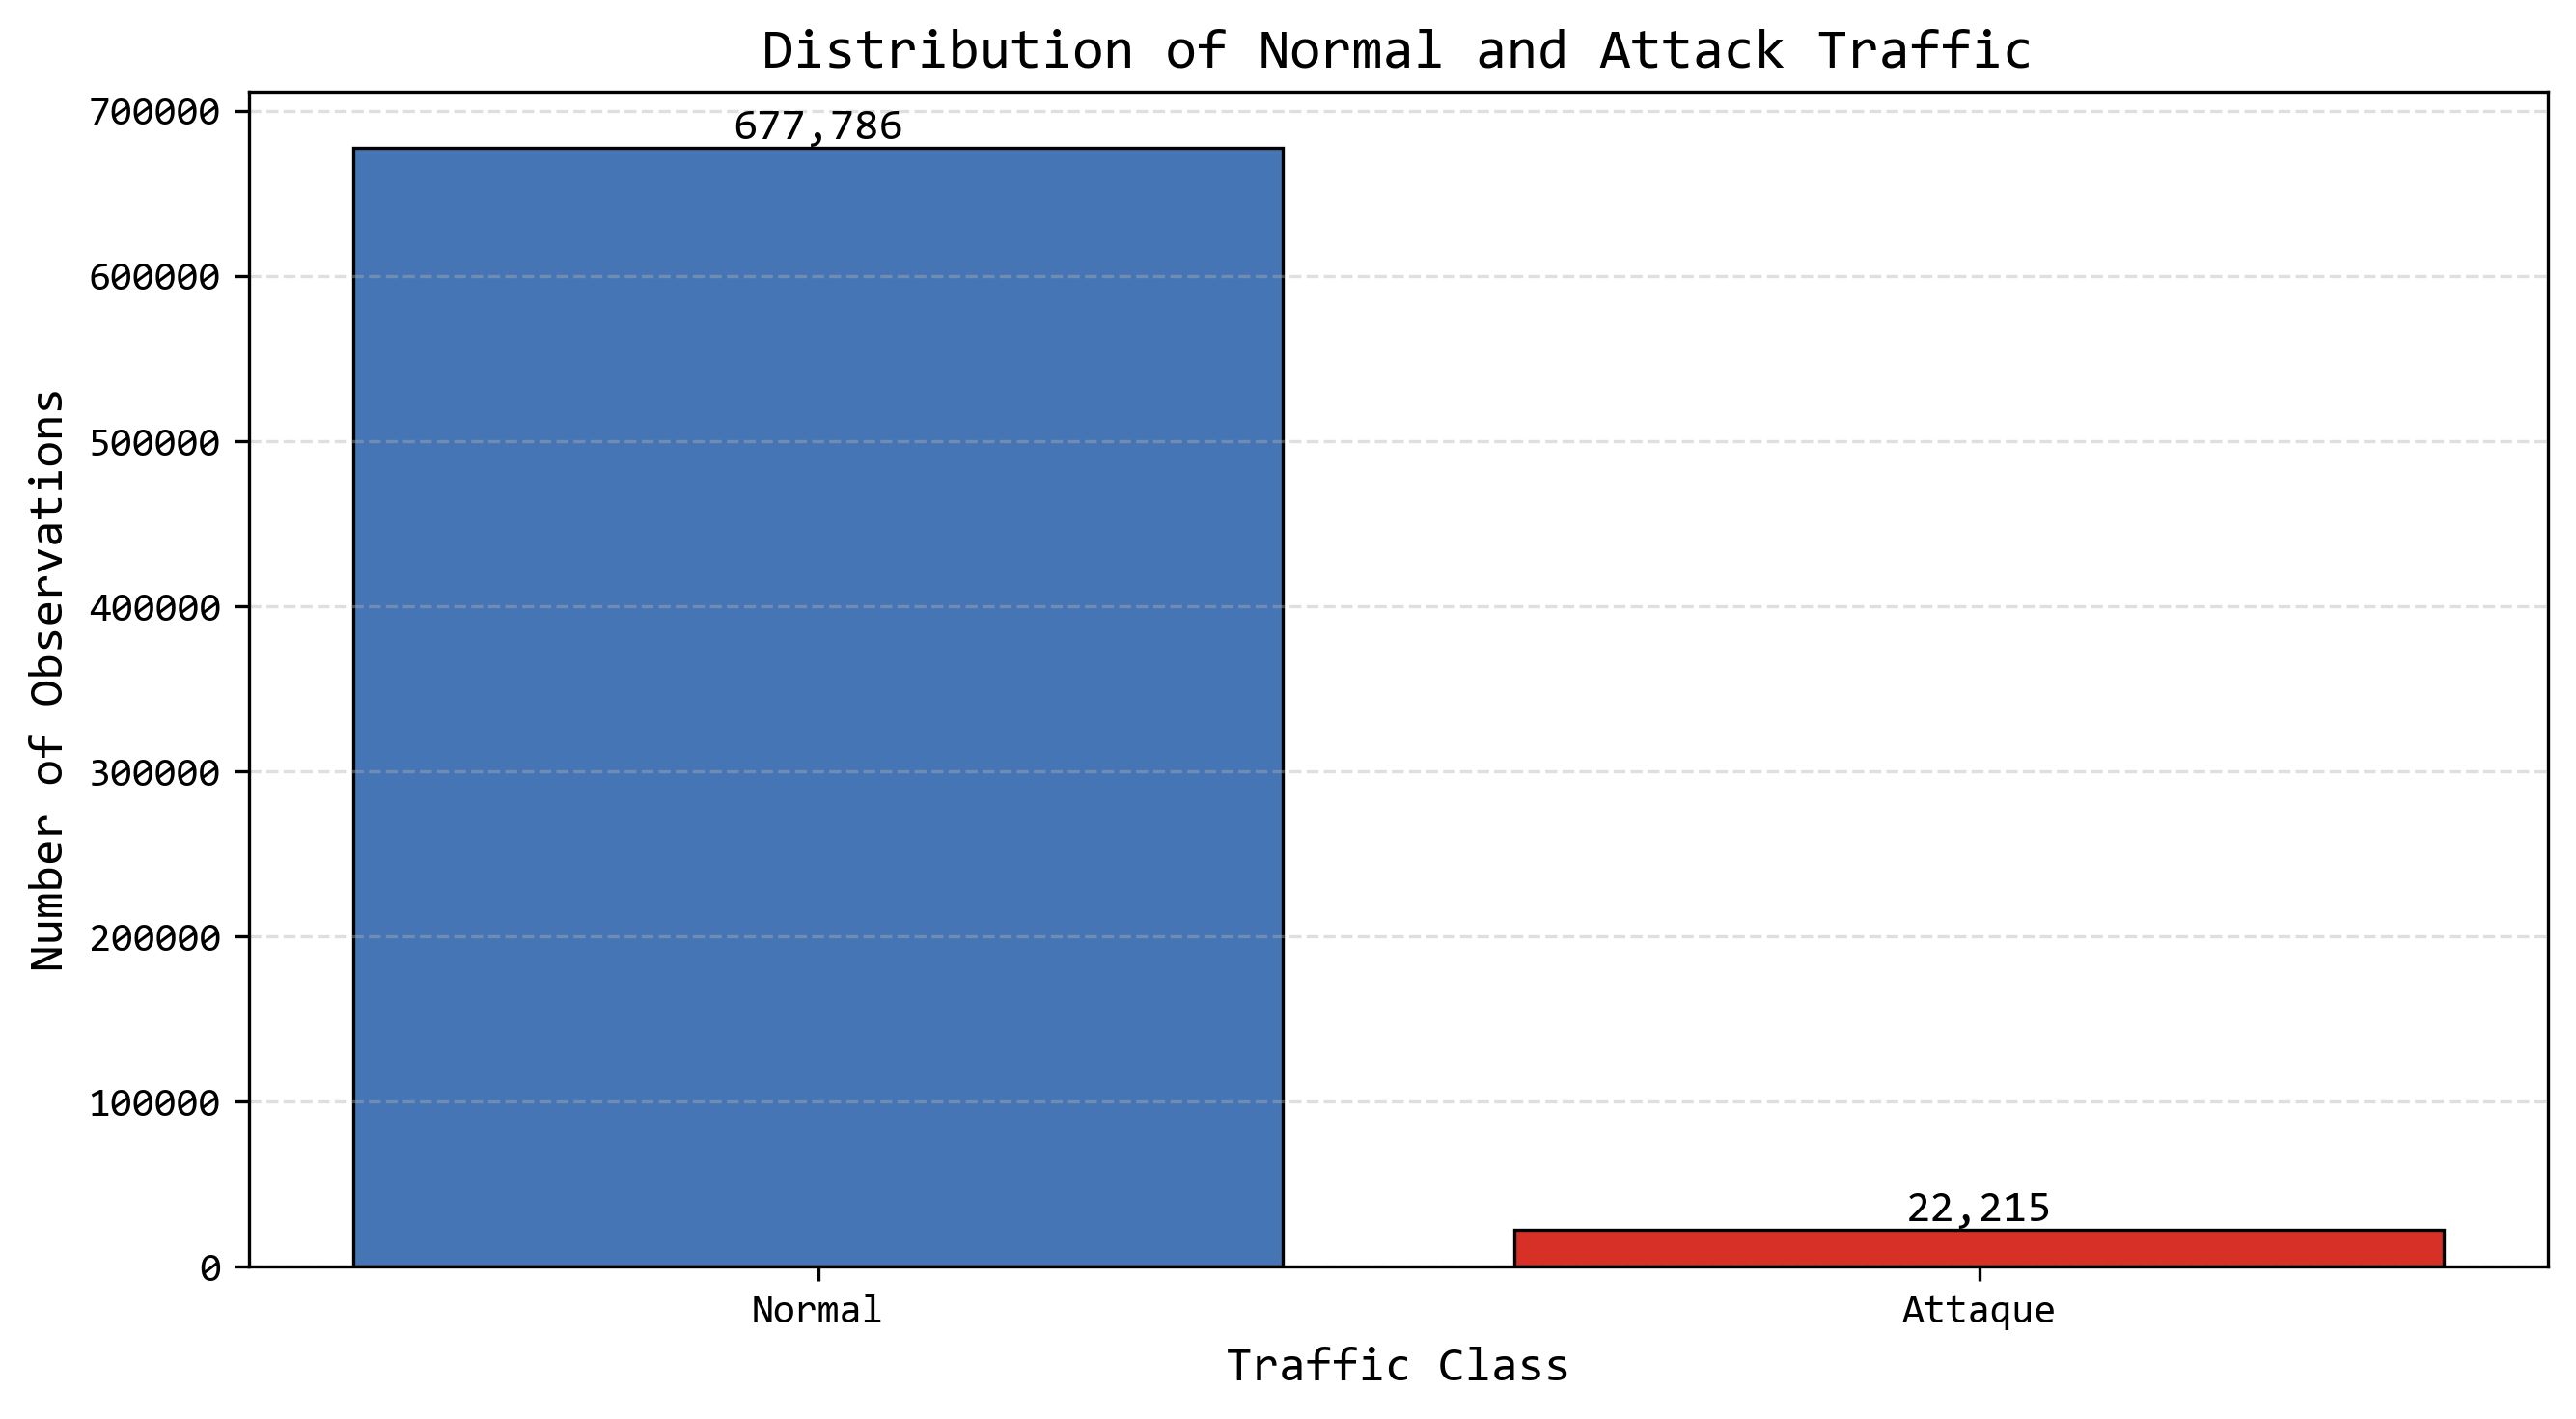

In [32]:
# ===================================
# Analyse de la variable cible
# Normal / Attaque
# ===================================

# ===================================
# Définition de la variable cible
# ===================================

TARGET = "label"


if TARGET not in df.columns:
    
    raise ValueError(
        f"La colonne cible '{TARGET}' est absente du dataset."
    )


print(
    f"\nVariable cible sélectionnée : {TARGET}"
)


# ===================================
# Valeurs uniques de la cible
# ===================================

target_values = (
    
    df[TARGET]
    
    .value_counts(
        dropna=False
    )
    
    .sort_index()
    
)


# ===================================
# Vérification des classes
# ===================================

unique_classes = (
    
    df[TARGET]
    
    .dropna()
    
    .unique()
    
)

# ===================================
# Convention expérimentale
# ===================================

NORMAL_LABEL = 0

ATTACK_LABEL = 1


# ===================================
# Comptage des observations
# ===================================

n_normal = (
    
    df[
        df[TARGET] == NORMAL_LABEL
    ]
    
    .shape[0]
    
)


n_attack = (
    
    df[
        df[TARGET] == ATTACK_LABEL
    ]
    
    .shape[0]
    
)


n_total = len(df)


# ===================================
# Calcul des pourcentages
# ===================================

normal_percent = (
    
    n_normal
    
    / n_total
    
    * 100
    
)


attack_percent = (
    
    n_attack
    
    / n_total
    
    * 100
    
)

# ===================================
# Tableau récapitulatif
# ===================================

class_distribution = pd.DataFrame({
    
    "Classe": [
        "Normal",
        "Attaque"
    ],
    
    "Label": [
        NORMAL_LABEL,
        ATTACK_LABEL
    ],
    
    "Nombre": [
        n_normal,
        n_attack
    ],
    
    "Pourcentage (%)": [
        normal_percent,
        attack_percent
    ]
    
})

# ===================================
# Visualisation
# ===================================

plt.rcParams[
    "font.family"
] = "Consolas"


fig, ax = plt.subplots(
    
    figsize=(
        9,
        5
    ),
    
    dpi=300
    
)


bars = ax.bar(
    
    class_distribution[
        "Classe"
    ],
    
    class_distribution[
        "Nombre"
    ],
    
    color=[
        "#4575B4",
        "#D73027"
    ],
    
    edgecolor="black",
    
    linewidth=0.8
    
)


# ===================================
# Valeurs au-dessus des barres
# ===================================

for bar, value in zip(
    
    bars,
    
    class_distribution[
        "Nombre"
    ]
    
):
    
    ax.text(
        
        bar.get_x()
        + bar.get_width() / 2,
        
        bar.get_height(),
        
        f"{value:,}",
        
        ha="center",
        
        va="bottom",
        
        fontsize=11,
        
        fontfamily="Consolas"
        
    )


# ===================================
# Mise en forme du graphique
# ===================================

ax.set_title(
    
    "Distribution of Normal and Attack Traffic",
    
    fontsize=14,
    
    fontfamily="Consolas"
    
)


ax.set_xlabel(
    
    "Traffic Class",
    
    fontsize=12,
    
    fontfamily="Consolas"
    
)


ax.set_ylabel(
    
    "Number of Observations",
    
    fontsize=12,
    
    fontfamily="Consolas"
    
)


ax.grid(
    
    axis="y",
    
    linestyle="--",
    
    alpha=0.4
    
)


plt.tight_layout()


# ===================================
# Sauvegarde de la figure
# ===================================

plt.savefig(
    
    "isolation_forest_class_distribution.png",
    
    dpi=300,
    
    bbox_inches="tight"
    
)


plt.show()


Variable cible sélectionnée : label


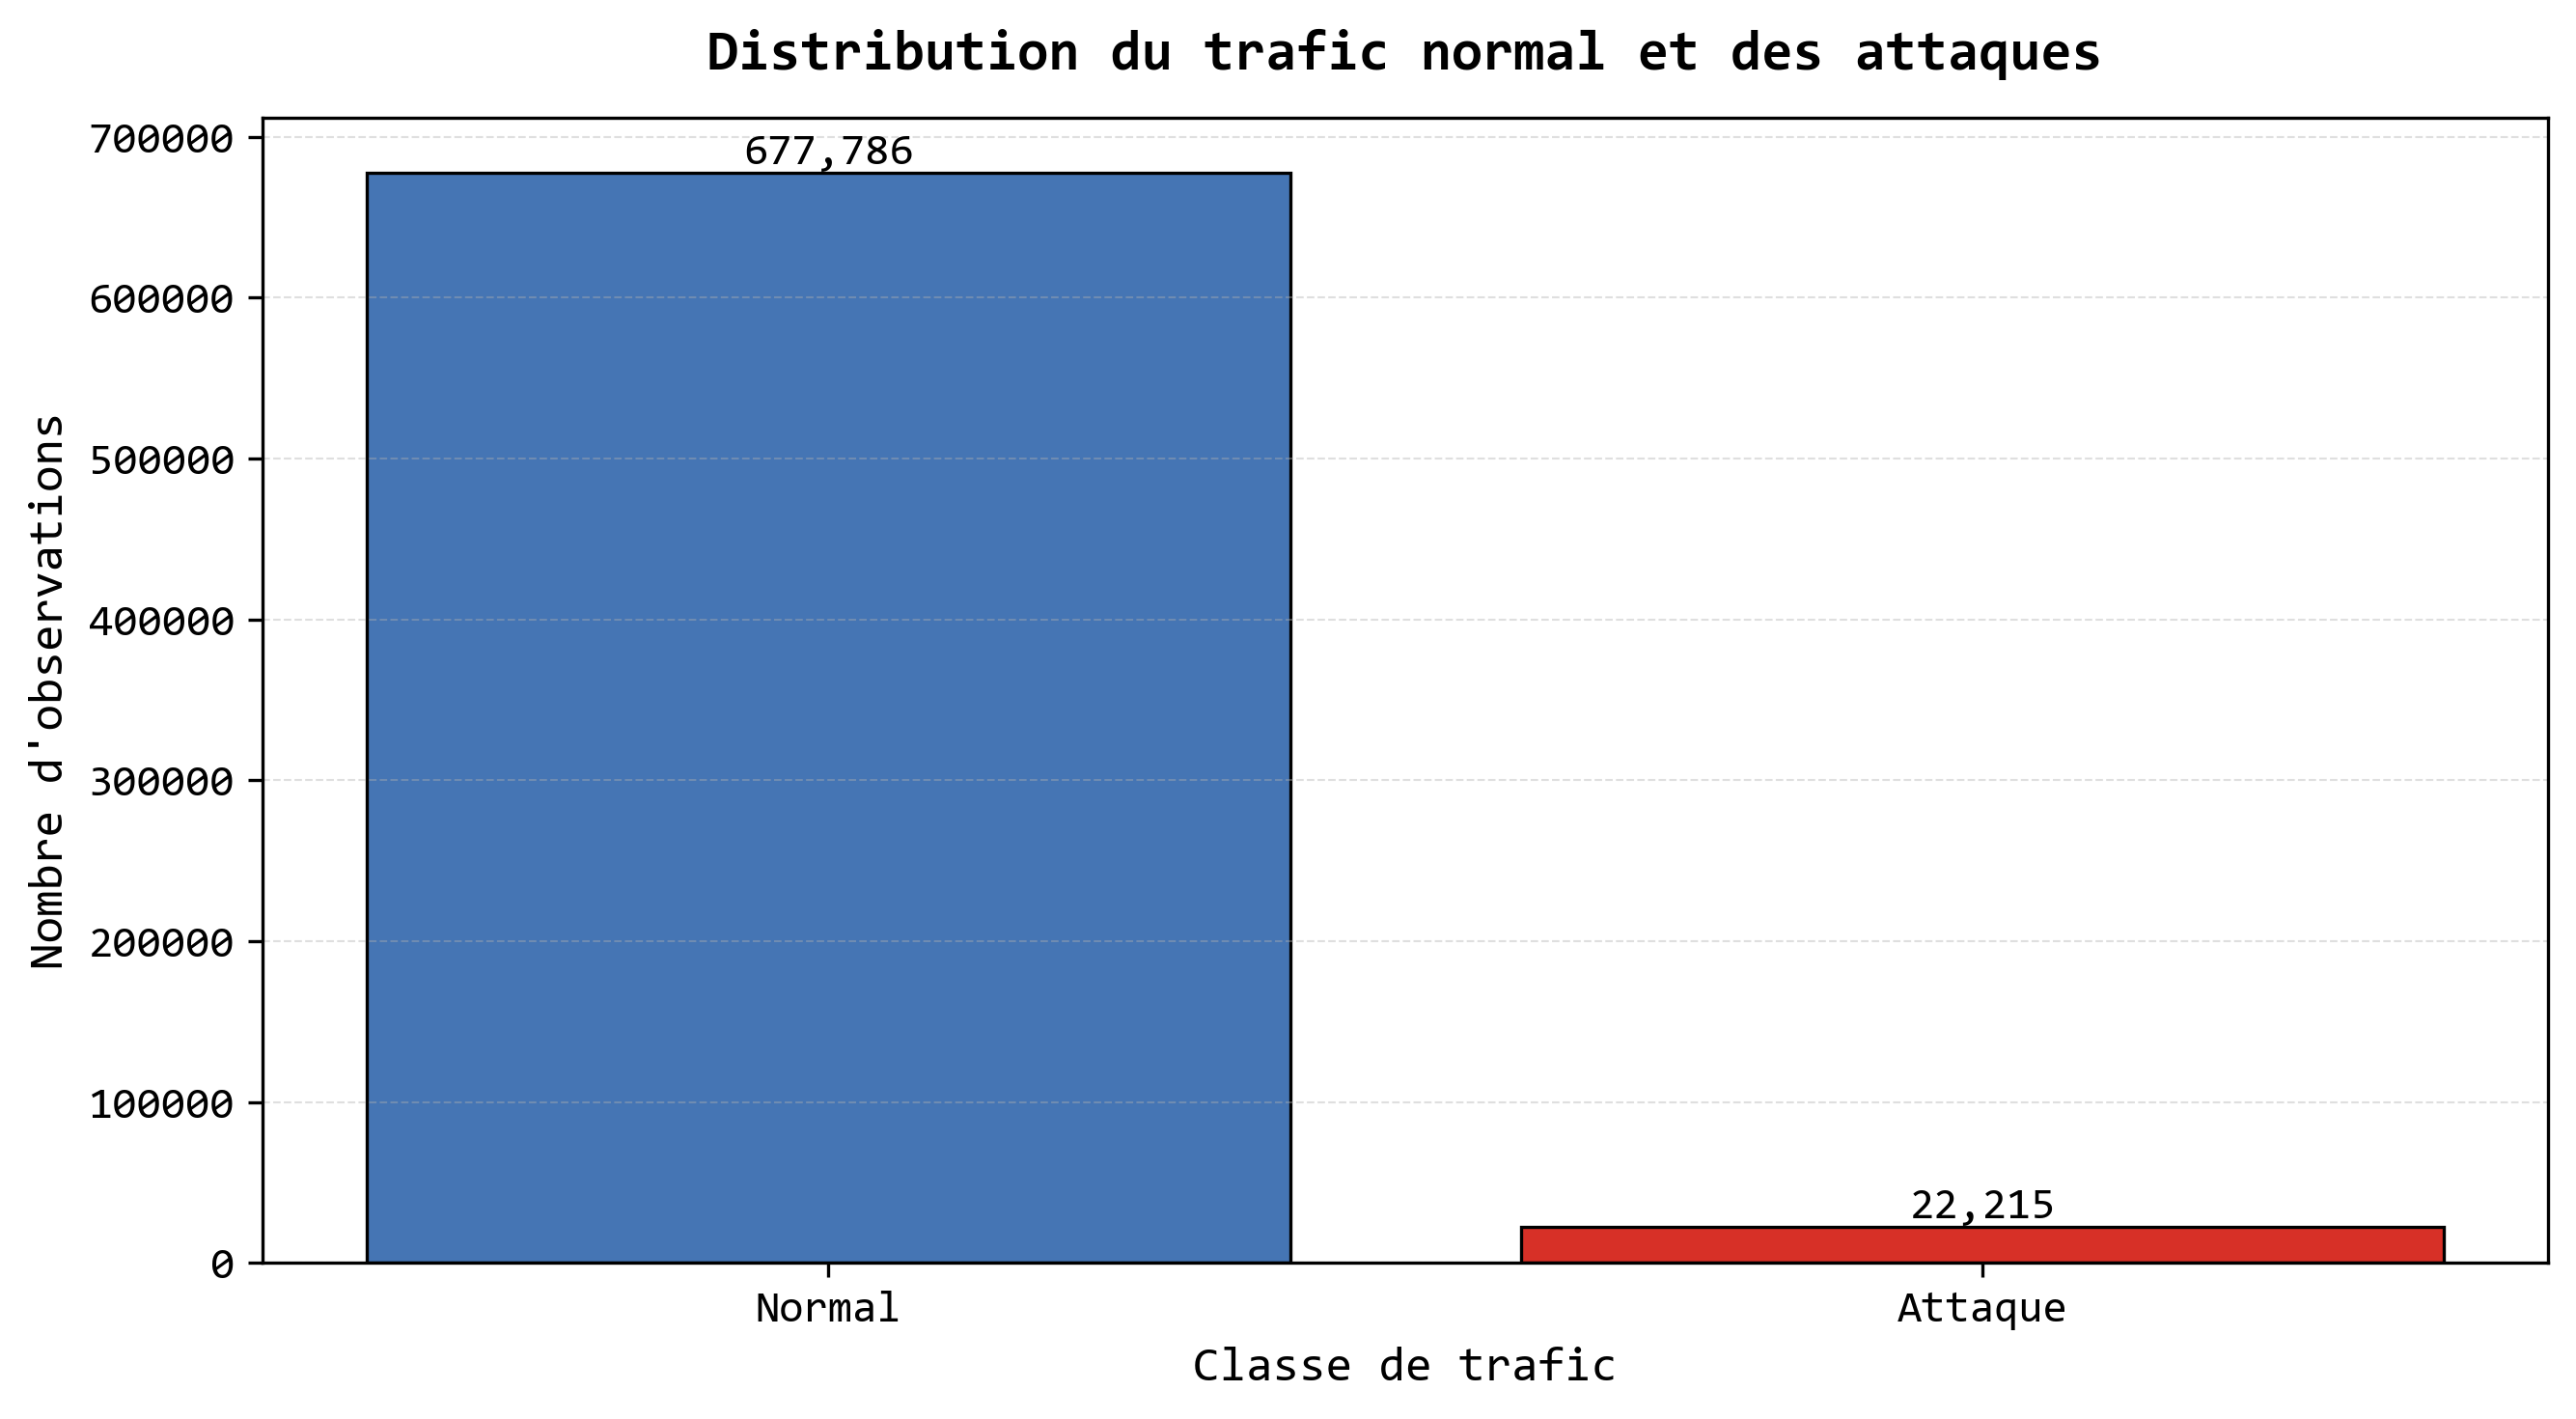

In [31]:
# ===================================
# Analyse de la variable cible
# Normal / Attaque
# ===================================

# ===================================
# Définition de la variable cible
# ===================================

TARGET = "label"


if TARGET not in df.columns:

    raise ValueError(
        f"La colonne cible '{TARGET}' est absente du dataset."
    )


print(
    f"\nVariable cible sélectionnée : {TARGET}"
)


# ===================================
# Valeurs uniques de la cible
# ===================================

target_values = (
    df[TARGET]
    .value_counts(
        dropna=False
    )
    .sort_index()
)


# ===================================
# Vérification des classes
# ===================================

unique_classes = (
    df[TARGET]
    .dropna()
    .unique()
)


# ===================================
# Convention expérimentale
# ===================================

NORMAL_LABEL = 0

ATTACK_LABEL = 1


# ===================================
# Comptage des observations
# ===================================

n_normal = (
    df[
        df[TARGET] == NORMAL_LABEL
    ]
    .shape[0]
)


n_attack = (
    df[
        df[TARGET] == ATTACK_LABEL
    ]
    .shape[0]
)


n_total = len(df)


# ===================================
# Calcul des pourcentages
# ===================================

normal_percent = (
    n_normal
    / n_total
    * 100
)


attack_percent = (
    n_attack
    / n_total
    * 100
)


# ===================================
# Tableau récapitulatif
# ===================================

class_distribution = pd.DataFrame({

    "Classe": [
        "Normal",
        "Attaque"
    ],

    "Label": [
        NORMAL_LABEL,
        ATTACK_LABEL
    ],

    "Nombre": [
        n_normal,
        n_attack
    ],

    "Pourcentage (%)": [
        normal_percent,
        attack_percent
    ]

})


# ===================================
# Visualisation
# ===================================

plt.rcParams[
    "font.family"
] = "Consolas"


fig, ax = plt.subplots(

    figsize=(
        9,
        5
    ),

    dpi=300

)


bars = ax.bar(

    class_distribution[
        "Classe"
    ],

    class_distribution[
        "Nombre"
    ],

    color=[
        "#4575B4",
        "#D73027"
    ],

    edgecolor="black",

    linewidth=0.8

)


# ===================================
# Valeurs au-dessus des barres
# ===================================

for bar, value in zip(

    bars,

    class_distribution[
        "Nombre"
    ]

):

    ax.text(

        bar.get_x()
        + bar.get_width() / 2,

        bar.get_height(),

        f"{value:,}",

        ha="center",

        va="bottom",

        fontsize=11,

        fontfamily="Consolas"

    )


# ===================================
# Mise en forme du graphique
# ===================================

ax.set_title(

    "Distribution du trafic normal et des attaques",

    fontsize=14,

    fontweight="bold",

    fontfamily="Consolas",

    pad=12

)


ax.set_xlabel(

    "Classe de trafic",

    fontsize=12,

    fontfamily="Consolas"

)


ax.set_ylabel(

    "Nombre d'observations",

    fontsize=12,

    fontfamily="Consolas"

)


ax.grid(

    axis="y",

    linestyle="--",

    linewidth=0.5,

    alpha=0.4

)


# ===================================
# Personnalisation des graduations
# ===================================

ax.tick_params(
    axis="both",
    labelsize=11
)


for label in ax.get_xticklabels():
    label.set_fontname("Consolas")


for label in ax.get_yticklabels():
    label.set_fontname("Consolas")


# ===================================
# Ajustement
# ===================================

plt.tight_layout()


# ===================================
# Sauvegarde de la figure
# ===================================

plt.savefig(

    "fr_distribution_classes_isolation_forest.png",

    format="png",

    dpi=300,

    bbox_inches="tight"

)


# ===================================
# Affichage
# ===================================

plt.show()

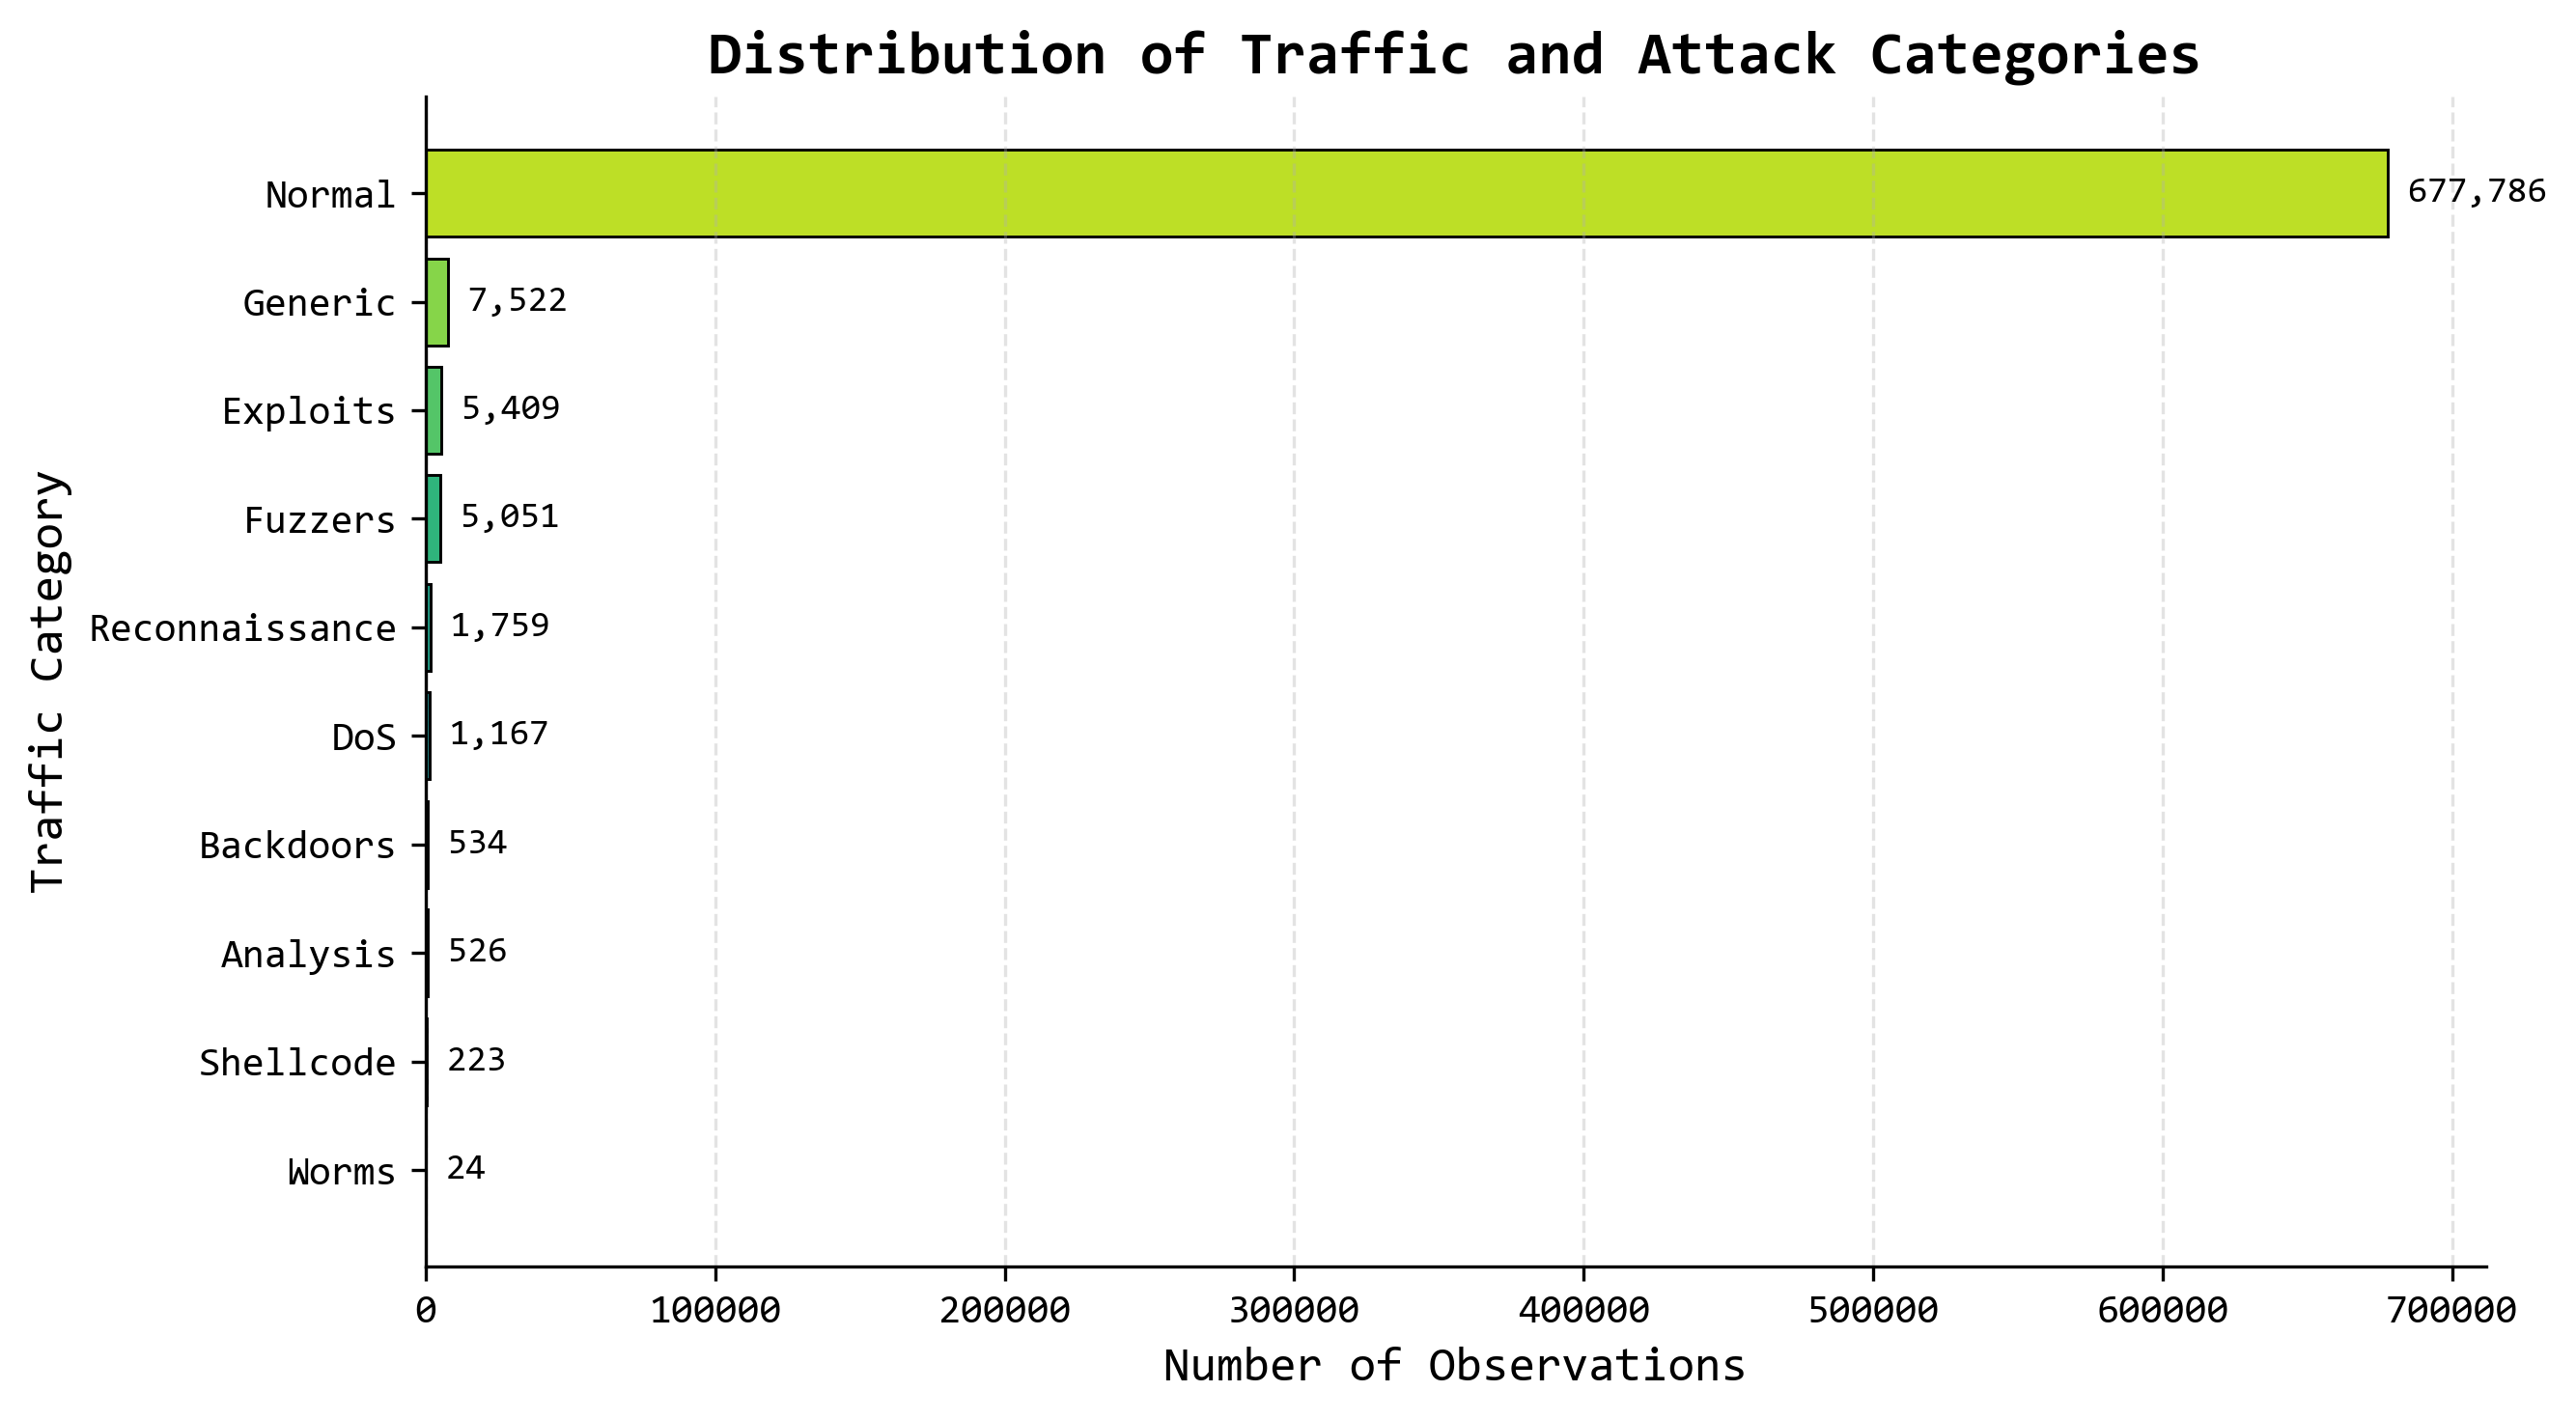

In [29]:
# ===================================
# Distribution des catégories d'attaque
# ===================================


# ===================================
# Vérification de la colonne
# ===================================

if "attack_cat" not in df.columns:

    raise ValueError(
        "La colonne 'attack_cat' est absente du dataset."
    )


# ===================================
# Copie de travail
# ===================================

attack_data = df.copy()


# ===================================
# Nettoyage de attack_cat
# ===================================

attack_data["attack_cat"] = (

    attack_data["attack_cat"]

    .astype(str)

    .str.strip()

)


# ===================================
# Trafic normal
# ===================================

attack_data.loc[
    attack_data["label"] == 0,
    "attack_cat"
] = "Normal"


# ===================================
# Gestion des valeurs vides
# ===================================

attack_data["attack_cat"] = (

    attack_data["attack_cat"]

    .replace(
        {
            "": "Unknown",
            "nan": "Unknown",
            "None": "Unknown"
        }
    )

)


# ===================================
# Comptage
# ===================================

attack_distribution = (

    attack_data["attack_cat"]

    .value_counts()

    .sort_values(
        ascending=True
    )

)



# ===================================
# Configuration graphique
# ===================================

plt.rcParams[
    "font.family"
] = "Consolas"


fig, ax = plt.subplots(

    figsize=(
        9,
        5
    ),

    dpi=300

)


# ===================================
# Palette scientifique
# ===================================

colors = plt.cm.viridis(

    np.linspace(
        0.15,
        0.90,
        len(attack_distribution)
    )

)


# ===================================
# Barres horizontales
# ===================================

bars = ax.barh(

    attack_distribution.index,

    attack_distribution.values,

    color=colors,

    edgecolor="black",

    linewidth=0.7

)


# ===================================
# Valeurs sur les barres
# ===================================

for bar in bars:

    width = bar.get_width()

    ax.text(

        width,

        bar.get_y()
        + bar.get_height() / 2,

        f" {int(width):,}",

        va="center",

        ha="left",

        fontsize=9,

        fontfamily="Consolas"

    )


# ===================================
# Mise en forme
# ===================================

ax.set_title(

    "Distribution of Traffic and Attack Categories",

    fontsize=15,

    fontweight="bold",

    fontfamily="Consolas"

)


ax.set_xlabel(

    "Number of Observations",

    fontsize=12,

    fontfamily="Consolas"

)


ax.set_ylabel(

    "Traffic Category",

    fontsize=12,

    fontfamily="Consolas"

)


ax.grid(

    axis="x",

    linestyle="--",

    alpha=0.35

)


# ===================================
# Suppression des bordures inutiles
# ===================================

ax.spines[
    "top"
].set_visible(False)

ax.spines[
    "right"
].set_visible(False)


plt.tight_layout()


# ===================================
# Sauvegarde
# ===================================

figure_name = (
    "isolation_forest_attack_category_distribution.png"
)


plt.savefig(

    figure_name,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


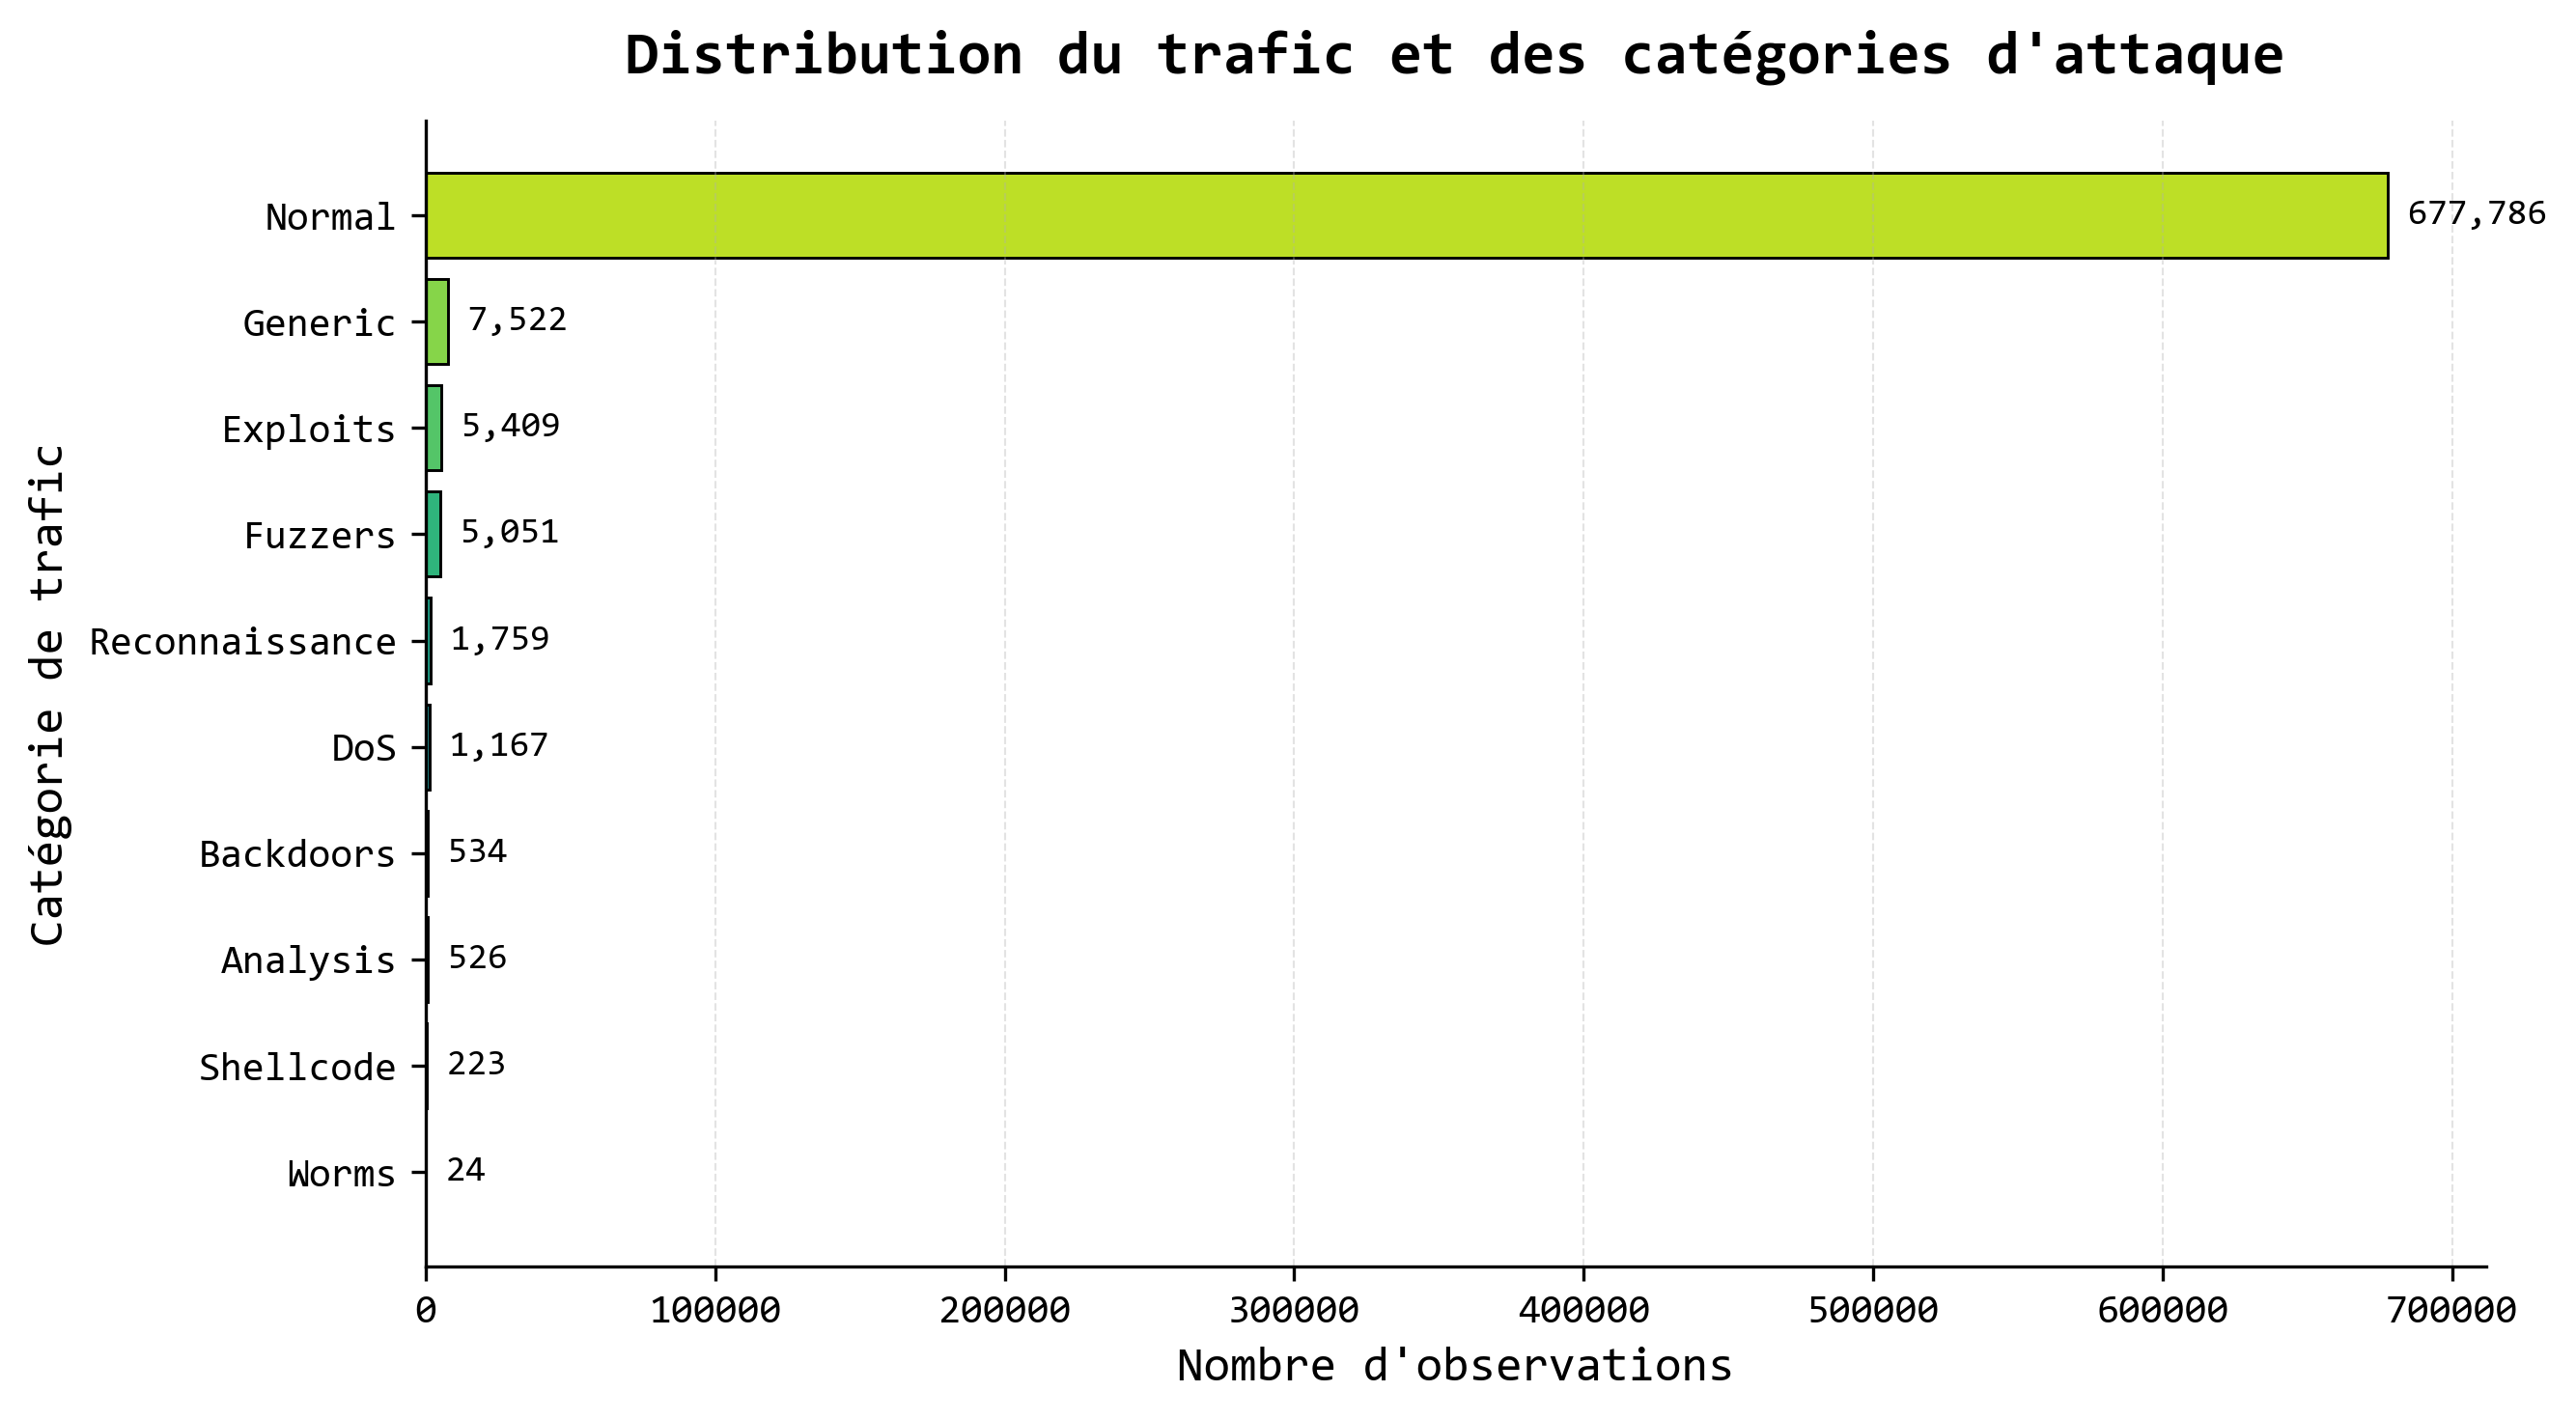

In [36]:
# ==========================================
# Distribution des catégories d'attaque
# ==========================================
# ==========================================
# Vérification de la colonne
# ==========================================

if "attack_cat" not in df.columns:

    raise ValueError(
        "La colonne 'attack_cat' est absente du dataset."
    )


# ==========================================
# Création du dossier de sauvegarde
# ==========================================

os.makedirs(
    "figures/evaluation",
    exist_ok=True
)


# ==========================================
# Copie de travail
# ==========================================

attack_data = df.copy()


# ==========================================
# Nettoyage de la variable attack_cat
# ==========================================

attack_data["attack_cat"] = (
    attack_data["attack_cat"]
    .astype(str)
    .str.strip()
)


# ==========================================
# Identification du trafic normal
# ==========================================

attack_data.loc[
    attack_data["label"] == 0,
    "attack_cat"
] = "Normal"


# ==========================================
# Gestion des valeurs vides
# ==========================================

attack_data["attack_cat"] = (
    attack_data["attack_cat"]
    .replace(
        {
            "": "Inconnu",
            "nan": "Inconnu",
            "None": "Inconnu"
        }
    )
)


# ==========================================
# Comptage des catégories
# ==========================================

attack_distribution = (
    attack_data["attack_cat"]
    .value_counts()
    .sort_values(ascending=True)
)



# ==========================================
# Configuration graphique
# ==========================================

plt.rcParams["font.family"] = "Consolas"


fig, ax = plt.subplots(
    figsize=(9,5),
    dpi=300
)


# ==========================================
# Palette scientifique
# ==========================================

colors = plt.cm.viridis(
    np.linspace(
        0.15,
        0.90,
        len(attack_distribution)
    )
)


# ==========================================
# Barres horizontales
# ==========================================

bars = ax.barh(
    attack_distribution.index,
    attack_distribution.values,
    color=colors,
    edgecolor="black",
    linewidth=0.7
)


# ==========================================
# Valeurs sur les barres
# ==========================================

for bar in bars:

    width = bar.get_width()

    ax.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f" {int(width):,}",
        va="center",
        ha="left",
        fontsize=9,
        fontfamily="Consolas"
    )


# ==========================================
# Mise en forme
# ==========================================

ax.set_title(
    "Distribution du trafic et des catégories d'attaque",
    fontsize=15,
    fontweight="bold",
    fontfamily="Consolas",
    pad=12
)


ax.set_xlabel(
    "Nombre d'observations",
    fontsize=12,
    fontfamily="Consolas"
)


ax.set_ylabel(
    "Catégorie de trafic",
    fontsize=12,
    fontfamily="Consolas"
)


# ==========================================
# Grille
# ==========================================

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.5,
    alpha=0.35
)


# ==========================================
# Suppression des bordures inutiles
# ==========================================

ax.spines["top"].set_visible(False)

ax.spines["right"].set_visible(False)


# ==========================================
# Personnalisation des graduations
# ==========================================

ax.tick_params(
    axis="both",
    labelsize=10
)


for label in ax.get_xticklabels():
    label.set_fontname("Consolas")


for label in ax.get_yticklabels():
    label.set_fontname("Consolas")


# ==========================================
# Ajustement
# ==========================================

plt.tight_layout()


# ==========================================
# Sauvegarde PNG haute résolution
# ==========================================

figure_name = (
    "fr_isolation_forest_attack_category_distribution.png"
)


plt.savefig(
    figure_name,
    format="png",
    dpi=300,
    bbox_inches="tight"
)


# ==========================================
# Affichage
# ==========================================

plt.show()

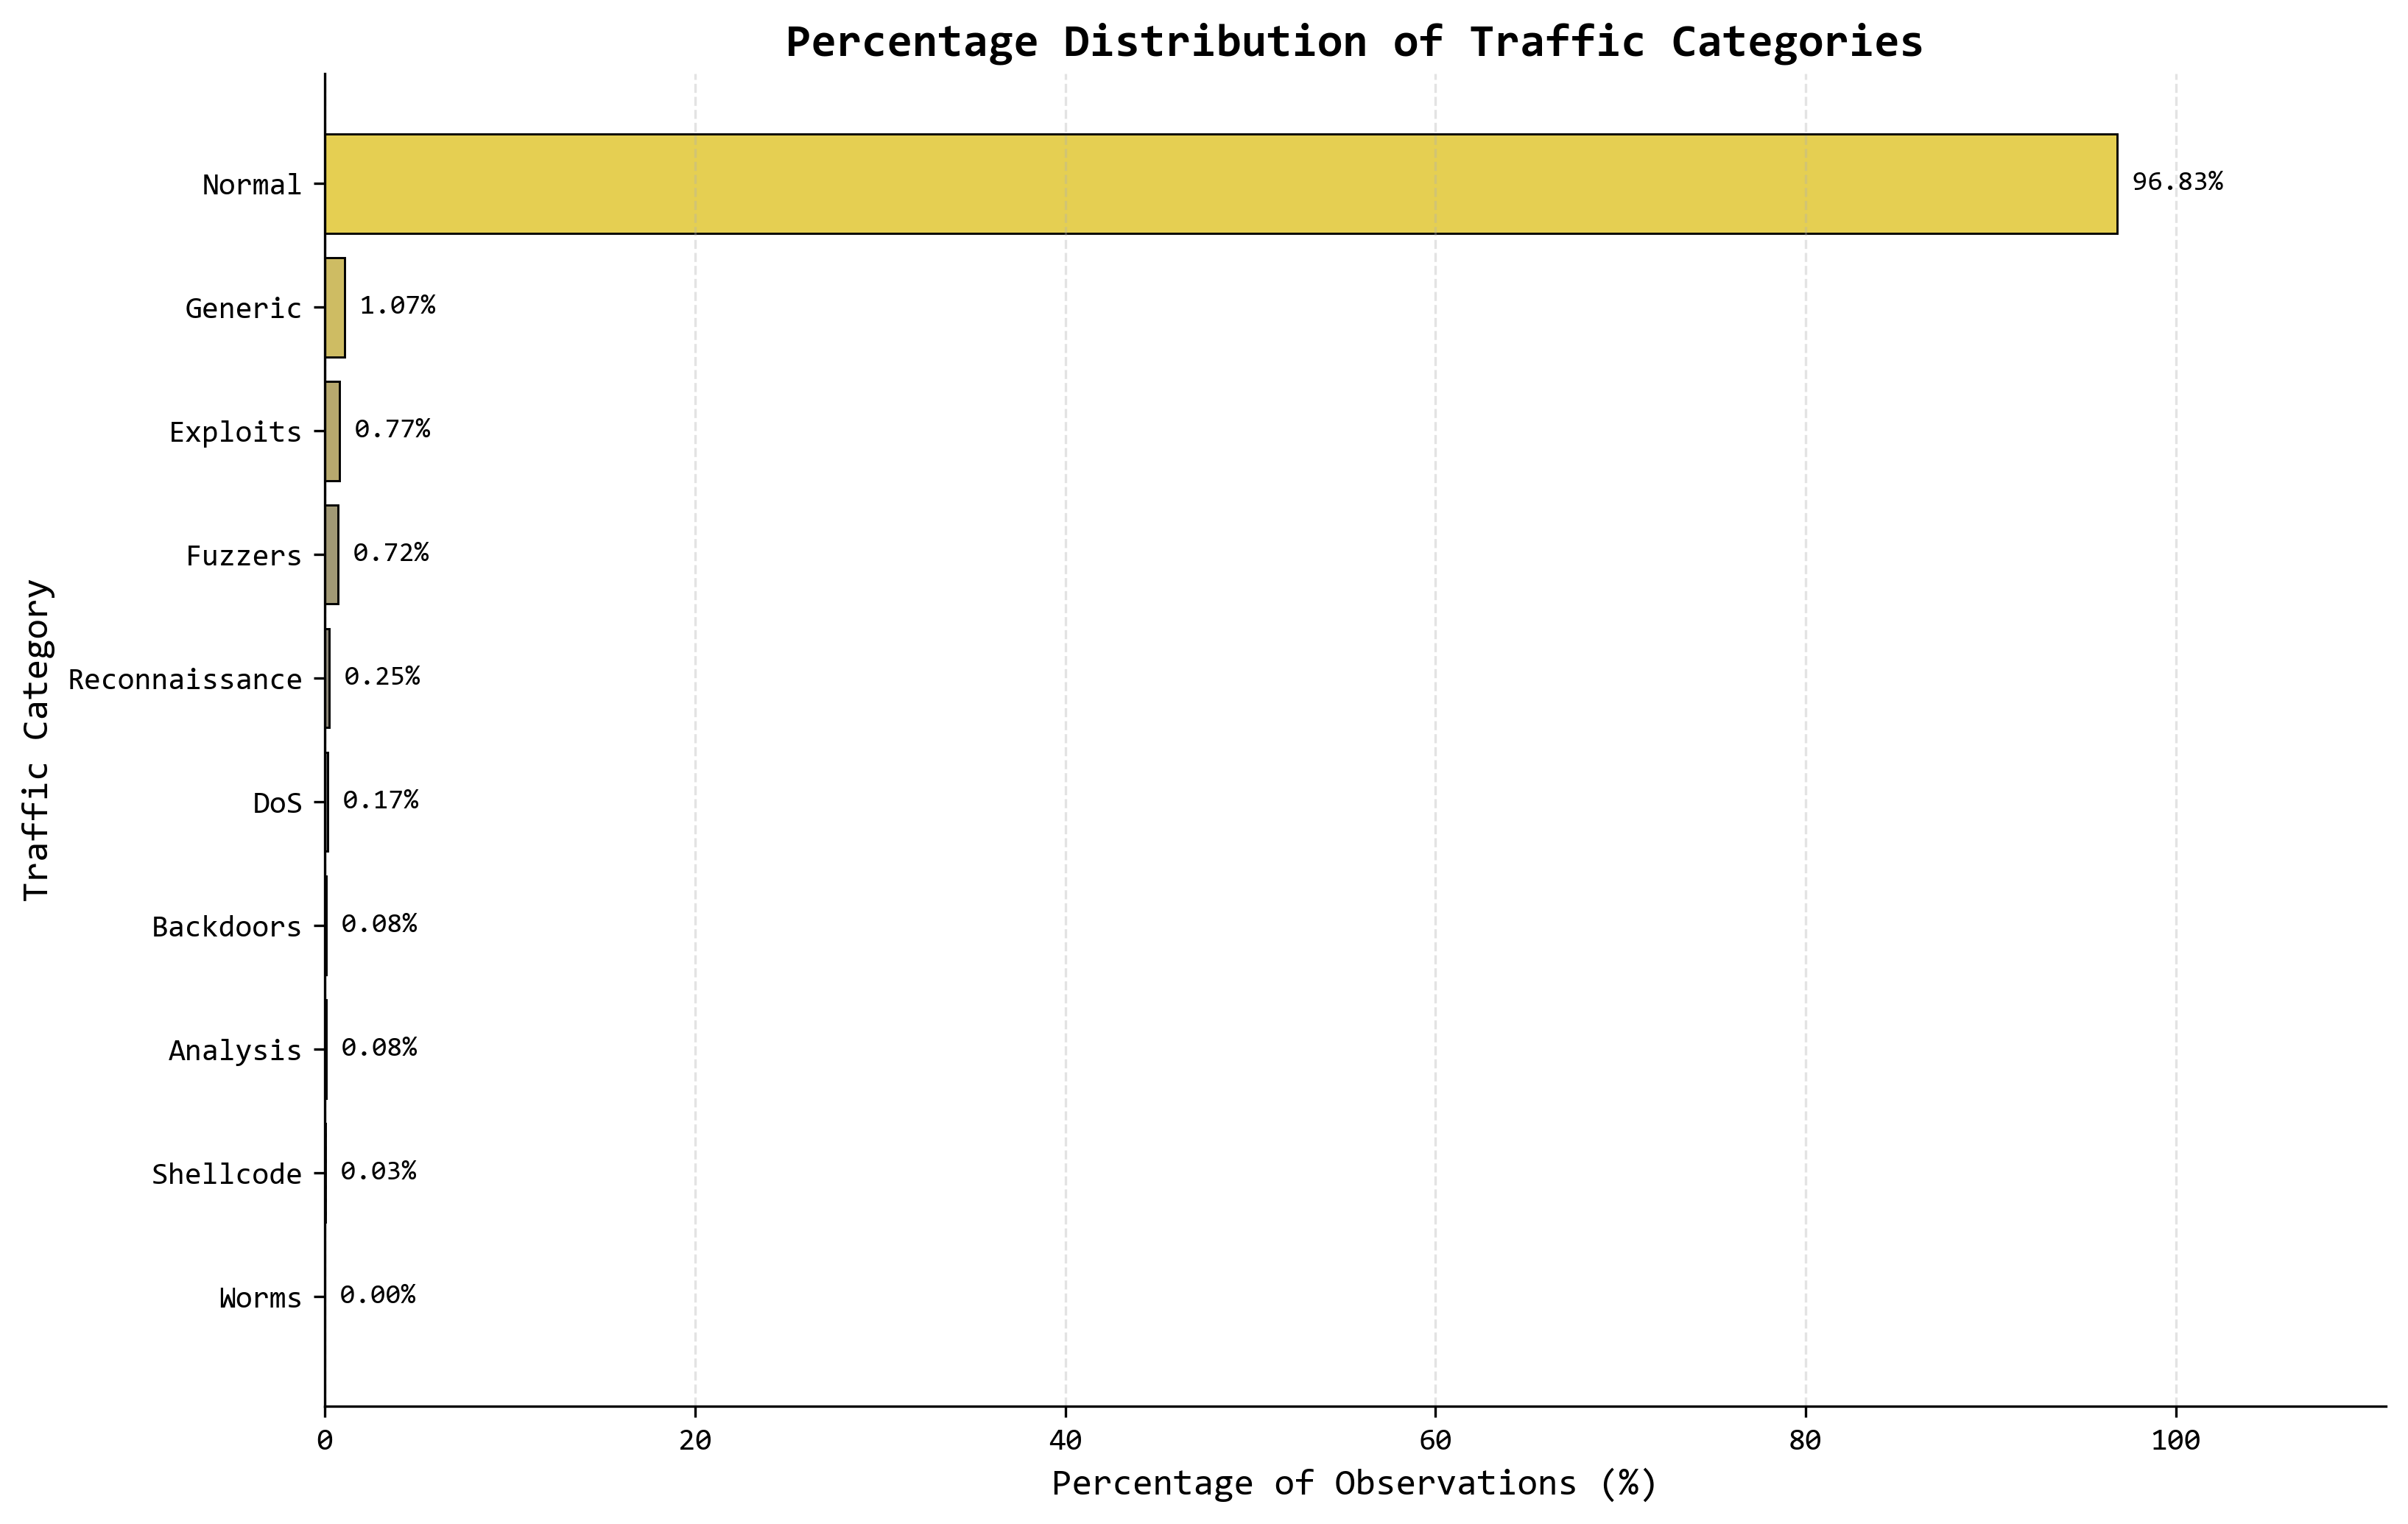

In [37]:
# ===================================
# Répartition en pourcentage
# des catégories de trafic
# ===================================


# ===================================
# Calcul des pourcentages
# ===================================

attack_percentage = (

    attack_data["attack_cat"]

    .value_counts(
        normalize=True
    )

    .mul(100)

    .sort_values(
        ascending=True
    )

)



# ===================================
# Configuration graphique
# ===================================

plt.rcParams[
    "font.family"
] = "Consolas"


fig, ax = plt.subplots(

    figsize=(
        11,
        7
    ),

    dpi=300

)


# ===================================
# Palette scientifique
# ===================================

colors = plt.cm.cividis(

    np.linspace(
        0.15,
        0.90,
        len(attack_percentage)
    )

)


# ===================================
# Graphique horizontal
# ===================================

bars = ax.barh(

    attack_percentage.index,

    attack_percentage.values,

    color=colors,

    edgecolor="black",

    linewidth=0.7

)


# ===================================
# Affichage des pourcentages
# ===================================

for bar in bars:

    width = bar.get_width()

    ax.text(

        width,

        bar.get_y()
        + bar.get_height() / 2,

        f" {width:.2f}%",

        va="center",

        ha="left",

        fontsize=9,

        fontfamily="Consolas"

    )


# ===================================
# Titre et axes
# ===================================

ax.set_title(

    "Percentage Distribution of Traffic Categories",

    fontsize=15,

    fontweight="bold",

    fontfamily="Consolas"

)


ax.set_xlabel(

    "Percentage of Observations (%)",

    fontsize=12,

    fontfamily="Consolas"

)


ax.set_ylabel(

    "Traffic Category",

    fontsize=12,

    fontfamily="Consolas"

)


# ===================================
# Grille
# ===================================

ax.grid(

    axis="x",

    linestyle="--",

    alpha=0.35

)


# ===================================
# Suppression des bordures
# ===================================

ax.spines[
    "top"
].set_visible(False)


ax.spines[
    "right"
].set_visible(False)


# ===================================
# Marge pour les valeurs
# ===================================

ax.set_xlim(

    0,

    attack_percentage.max()
    * 1.15

)


plt.tight_layout()


# ===================================
# Sauvegarde
# ===================================

figure_name = (
    "isolation_forest_attack_category_percentage.png"
)


plt.savefig(

    figure_name,

    dpi=300,

    bbox_inches="tight"

)


plt.show()

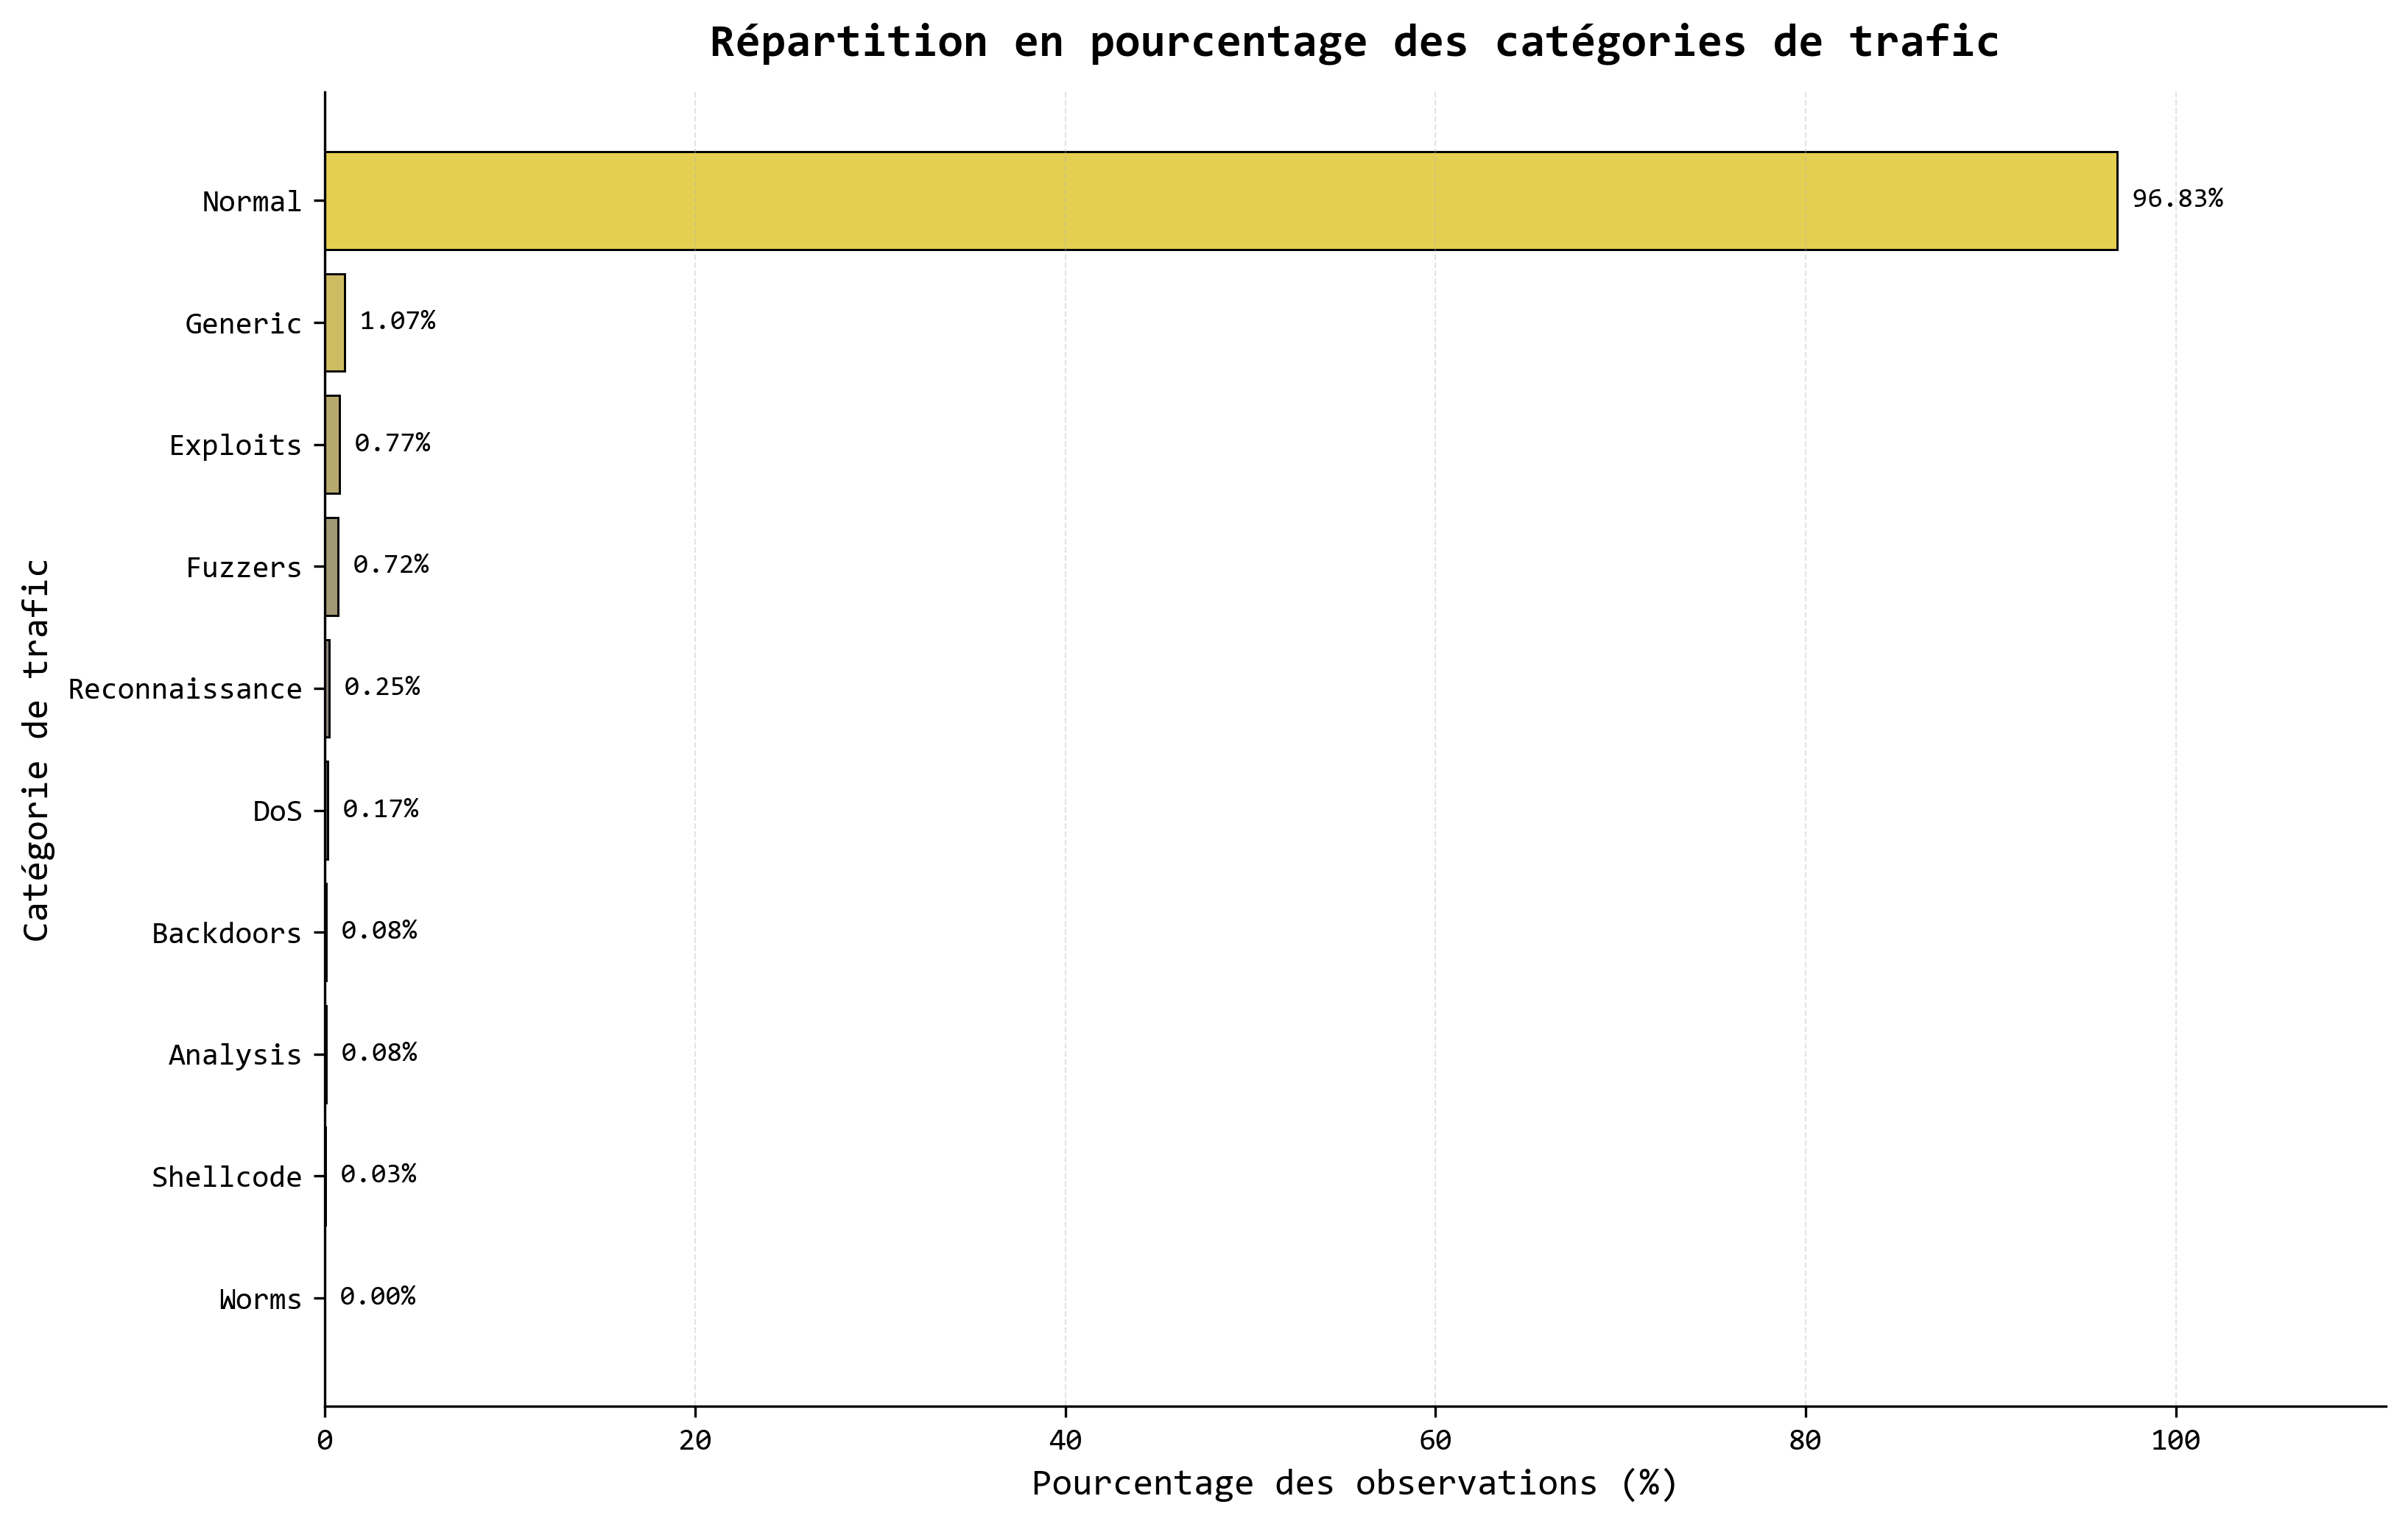

In [39]:
# ==========================================
# Création du dossier de sauvegarde
# ==========================================

os.makedirs(
    "figures/evaluation",
    exist_ok=True
)


# ==========================================
# Calcul des pourcentages
# ==========================================

attack_percentage = (
    attack_data["attack_cat"]
    .value_counts(normalize=True)
    .mul(100)
    .sort_values(ascending=True)
)



# ==========================================
# Configuration graphique
# ==========================================

plt.rcParams["font.family"] = "Consolas"


fig, ax = plt.subplots(
    figsize=(11,7),
    dpi=300
)


# ==========================================
# Palette scientifique
# ==========================================

colors = plt.cm.cividis(
    np.linspace(
        0.15,
        0.90,
        len(attack_percentage)
    )
)


# ==========================================
# Graphique horizontal
# ==========================================

bars = ax.barh(
    attack_percentage.index,
    attack_percentage.values,
    color=colors,
    edgecolor="black",
    linewidth=0.7
)


# ==========================================
# Affichage des pourcentages
# ==========================================

for bar in bars:

    width = bar.get_width()

    ax.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f" {width:.2f}%",
        va="center",
        ha="left",
        fontsize=9,
        fontfamily="Consolas"
    )


# ==========================================
# Titre
# ==========================================

ax.set_title(
    "Répartition en pourcentage des catégories de trafic",
    fontsize=15,
    fontweight="bold",
    fontfamily="Consolas",
    pad=12
)


# ==========================================
# Labels des axes
# ==========================================

ax.set_xlabel(
    "Pourcentage des observations (%)",
    fontsize=12,
    fontfamily="Consolas"
)


ax.set_ylabel(
    "Catégorie de trafic",
    fontsize=12,
    fontfamily="Consolas"
)


# ==========================================
# Grille
# ==========================================

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.5,
    alpha=0.35
)


# ==========================================
# Suppression des bordures inutiles
# ==========================================

ax.spines["top"].set_visible(False)

ax.spines["right"].set_visible(False)


# ==========================================
# Personnalisation des graduations
# ==========================================

ax.tick_params(
    axis="both",
    labelsize=10
)


for label in ax.get_xticklabels():
    label.set_fontname("Consolas")


for label in ax.get_yticklabels():
    label.set_fontname("Consolas")


# ==========================================
# Marge pour les valeurs
# ==========================================

ax.set_xlim(
    0,
    attack_percentage.max() * 1.15
)


# ==========================================
# Ajustement
# ==========================================

plt.tight_layout()


# ==========================================
# Sauvegarde PNG haute résolution
# ==========================================

figure_name = (
    "figures/evaluation/"
    "fr_isolation_forest_attack_category_percentage.png"
)


plt.savefig(
    figure_name,
    format="png",
    dpi=300,
    bbox_inches="tight"
)


# ==========================================
# Affichage
# ==========================================

plt.show()


In [48]:
# ==========================================
# Préparation de X et y
# ==========================================
# Vérification de la colonne cible
if "label" not in df.columns:
    raise ValueError(
        "La colonne 'label' est absente du dataset."
    )


# Conversion du label en numérique
df["label"] = pd.to_numeric(
    df["label"],
    errors="coerce"
)


# Suppression des lignes avec un label invalide
df = df.dropna(
    subset=["label"]
).reset_index(drop=True)


# Conversion en entier
df["label"] = df["label"].astype(np.int8)


# Variable cible
y = df["label"].copy()


# Variables explicatives
X = df.drop(
    columns=["label", "attack_cat"],
    errors="ignore"
).copy()


# Identification des variables
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

In [54]:
# ===================================
# Nettoyage des données
# Analyse de la cardinalité
# ===================================

# ===================================
# Copie de travail
# ===================================

X_clean = X.copy()


# ===================================
# Remplacement des infinis
# ===================================

X_clean = X_clean.replace(

    [
        np.inf,
        -np.inf
    ],

    np.nan

)


# ===================================
# Valeurs manquantes
# ===================================

missing_before = (

    X_clean

    .isna()

    .sum()

    .sort_values(
        ascending=False
    )

)


missing_before = missing_before[
    missing_before > 0
]


if len(missing_before) == 0:

    print()

else:

    display(

        missing_before.to_frame(
            name="Valeurs manquantes"
        )

    )


# ===================================
# Traitement des variables numériques
# Médiane
# ===================================

numeric_features = (

    X_clean

    .select_dtypes(
        include=[
            np.number
        ]
    )

    .columns

    .tolist()

)


for column in numeric_features:

    median_value = (

        X_clean[column]

        .median()

    )

    X_clean[column] = (

        X_clean[column]

        .fillna(
            median_value
        )

    )


# ===================================
# Traitement des variables catégorielles
# Valeur la plus fréquente
# ===================================

categorical_features = (

    X_clean

    .select_dtypes(
        exclude=[
            np.number
        ]
    )

    .columns

    .tolist()

)


for column in categorical_features:

    X_clean[column] = (

        X_clean[column]

        .astype(str)

        .str.strip()

    )


    X_clean[column] = (

        X_clean[column]

        .replace(
            {
                "": np.nan,
                "nan": np.nan,
                "None": np.nan
            }
        )

    )


    mode_values = (

        X_clean[column]

        .mode()

    )


    if len(mode_values) > 0:

        most_frequent = (
            mode_values.iloc[0]
        )

    else:

        most_frequent = "Unknown"


    X_clean[column] = (

        X_clean[column]

        .fillna(
            most_frequent
        )

    )


# ===================================
# Vérification après nettoyage
# ===================================

remaining_missing = (

    X_clean

    .isna()

    .sum()

    .sum()

)


cardinality_table = pd.DataFrame({

    "Variable":
        categorical_features,

    "Nombre de modalités":
        [
            X_clean[column].nunique()
            for column in categorical_features
        ]

})


cardinality_table = (

    cardinality_table

    .sort_values(
        by="Nombre de modalités",
        ascending=False
    )

    .reset_index(
        drop=True
    )

)


# ===================================
# Identification des variables
# à forte cardinalité
# ===================================

HIGH_CARDINALITY_THRESHOLD = 100


high_cardinality_features = (

    cardinality_table[

        cardinality_table[
            "Nombre de modalités"
        ]
        >
        HIGH_CARDINALITY_THRESHOLD

    ]

    ["Variable"]

    .tolist()

)


low_cardinality_features = (

    cardinality_table[

        cardinality_table[
            "Nombre de modalités"
        ]
        <=
        HIGH_CARDINALITY_THRESHOLD

    ]

    ["Variable"]

    .tolist()

)



if len(high_cardinality_features) == 0:

    print(
        "\nAucune variable à forte cardinalité."
    )

else:

    for column in high_cardinality_features:

        print()




In [61]:
# ==========================================
# Préparation de X et y
# ==========================================

# Vérification de la colonne cible
if "label" not in df.columns:
    raise ValueError(
        "La colonne 'label' est absente du dataset."
    )


# Conversion du label en numérique
df["label"] = pd.to_numeric(
    df["label"],
    errors="coerce"
)


# Suppression des lignes avec un label invalide
df = df.dropna(
    subset=["label"]
).reset_index(drop=True)


# Conversion en entier
df["label"] = df["label"].astype(np.int8)


# Variable cible
y = df["label"].copy()


# Variables explicatives
X = df.drop(
    columns=["label", "attack_cat"],
    errors="ignore"
).copy()


# Identification des variables
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()


In [62]:
# ==========================================
# Prétraitement des données
# ==========================================

# ==========================================
# Encodage des variables catégorielles
# ==========================================

for column in categorical_features:

    encoder = LabelEncoder()

    X[column] = encoder.fit_transform(
        X[column].astype(str)
    )


# ==========================================
# Conversion en numérique
# ==========================================

X = X.apply(
    pd.to_numeric,
    errors="coerce"
)


# ==========================================
# Gestion des valeurs infinies
# ==========================================

X = X.replace(
    [np.inf, -np.inf],
    np.nan
)


# ==========================================
# Gestion des valeurs manquantes
# ==========================================

X = X.fillna(
    X.median()
)


# ==========================================
# Standardisation
# ==========================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


# ==========================================
# Conversion en DataFrame
# ==========================================

X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns
)


print(
    "Dimensions après prétraitement :",
    X_scaled.shape
)

Dimensions après prétraitement : (700001, 47)


In [64]:
# ==========================================
# Données normales
# ==========================================

X_normal = X_scaled[
    y == 0
].copy()


# ==========================================
# Séparation entraînement / validation
# ==========================================

X_train, X_val = train_test_split(
    X_normal,
    test_size=0.20,
    random_state=42
)


# ==========================================
# Jeu de test complet
# Normal + Attaque
# ==========================================

X_test = X_scaled.copy()

y_test = y.copy()

In [66]:
# ===================================
# Séparation des données
# Cadre One-Class
# ===================================


# ===================================
# Vérification de cohérence
# ===================================

if len(X_clean) != len(y):

    raise ValueError(
        "X_clean et y n'ont pas le même nombre d'observations."
    )


# ===================================
# Réinitialisation des index
# ===================================

X_clean = (

    X_clean

    .reset_index(
        drop=True
    )

)


y = (

    y

    .reset_index(
        drop=True
    )

)


# ===================================
# Séparation trafic normal / attaques
# ===================================

X_normal = (

    X_clean[
        y == NORMAL_LABEL
    ]

    .copy()

)


X_attack = (

    X_clean[
        y == ATTACK_LABEL
    ]

    .copy()

)


# ===================================
# Première séparation
#
# 70 % du trafic normal :
# entraînement
#
# 30 % :
# normal temporaire
# ===================================

X_train_normal, X_normal_temp = train_test_split(

    X_normal,

    test_size=0.30,

    random_state=RANDOM_STATE,

    shuffle=True

)


# ===================================
# Séparation du bloc temporaire
#
# 15 % validation
# 15 % test normal
# ===================================

X_val_normal, X_test_normal = train_test_split(

    X_normal_temp,

    test_size=0.50,

    random_state=RANDOM_STATE,

    shuffle=True

)


# ===================================
# Création du jeu de test final
#
# Normal + Attaques
# ===================================

X_test = pd.concat(

    [
        X_test_normal,
        X_attack
    ],

    axis=0

)


# ===================================
# Création des vraies étiquettes
# du test
#
# 0 = normal
# 1 = attaque
# ===================================

y_test = np.concatenate(

    [

        np.zeros(
            len(X_test_normal),
            dtype=np.int8
        ),

        np.ones(
            len(X_attack),
            dtype=np.int8
        )

    ]

)


# ===================================
# Mélange du jeu de test
# ===================================

rng = np.random.RandomState(
    RANDOM_STATE
)


test_indices = rng.permutation(
    len(X_test)
)


X_test = (

    X_test

    .iloc[
        test_indices
    ]

    .reset_index(
        drop=True
    )

)


y_test = (

    y_test[
        test_indices
    ]

)


# ===================================
# Réinitialisation des index
# ===================================

X_train_normal = (

    X_train_normal

    .reset_index(
        drop=True
    )

)


X_val_normal = (

    X_val_normal

    .reset_index(
        drop=True
    )

)


X_test_normal = (

    X_test_normal

    .reset_index(
        drop=True ))

# ===================================
# Distribution du jeu de test
# ===================================

test_distribution = pd.Series(

    y_test

).value_counts().sort_index()

In [74]:
# ===================================
# Cellule 10
# Encodage des variables
# Faible / Forte cardinalité
# ===================================
# ===================================
# Copies de travail
# ===================================

X_train_encoded = X_train_normal.copy()

X_val_encoded = X_val_normal.copy()

X_test_encoded = X_test.copy()


# ===================================
# Identification des variables
# à partir du TRAIN uniquement
# ===================================

train_numeric_features = (

    X_train_normal

    .select_dtypes(
        include=[np.number]
    )

    .columns

    .tolist()

)


train_categorical_features = (

    X_train_normal

    .select_dtypes(
        exclude=[np.number]
    )

    .columns

    .tolist()

)


# ===================================
# Séparation faible / forte
# cardinalité
# ===================================

HIGH_CARDINALITY_THRESHOLD = 100


low_cardinality_features = []

high_cardinality_features = []


for column in train_categorical_features:

    cardinality = (

        X_train_normal[column]

        .nunique(
            dropna=False
        )

    )


    if cardinality > HIGH_CARDINALITY_THRESHOLD:

        high_cardinality_features.append(
            column
        )

    else:

        low_cardinality_features.append(
            column
        )


# ===================================
# Encodage fréquentiel
# des variables à forte cardinalité
#
# IMPORTANT :
# les fréquences sont calculées
# uniquement sur TRAIN NORMAL
# ===================================

frequency_mappings = {}


for column in high_cardinality_features:

    frequency_map = (

        X_train_normal[column]

        .value_counts(
            normalize=True
        )

        .to_dict()

    )


    frequency_mappings[column] = frequency_map


    # TRAIN

    X_train_encoded[column] = (

        X_train_normal[column]

        .map(
            frequency_map
        )

        .fillna(0.0)

        .astype(
            np.float32
        )

    )


    # VALIDATION

    X_val_encoded[column] = (

        X_val_normal[column]

        .map(
            frequency_map
        )

        .fillna(0.0)

        .astype(
            np.float32
        )

    )


    # TEST

    X_test_encoded[column] = (

        X_test[column]

        .map(
            frequency_map
        )

        .fillna(0.0)

        .astype(
            np.float32
        )

    )


# ===================================
# One-Hot Encoding
# variables faible cardinalité
# ===================================

if len(low_cardinality_features) > 0:

    # -----------------------------------
    # TRAIN
    # -----------------------------------

    X_train_encoded = pd.get_dummies(

        X_train_encoded,

        columns=low_cardinality_features,

        drop_first=False,

        dtype=np.float32

    )


    # -----------------------------------
    # VALIDATION
    # -----------------------------------

    X_val_encoded = pd.get_dummies(

        X_val_encoded,

        columns=low_cardinality_features,

        drop_first=False,

        dtype=np.float32

    )


    # -----------------------------------
    # TEST
    # -----------------------------------

    X_test_encoded = pd.get_dummies(

        X_test_encoded,

        columns=low_cardinality_features,

        drop_first=False,

        dtype=np.float32

    )


# ===================================
# Alignement des colonnes
#
# TRAIN définit les variables
# autorisées
# ===================================

X_val_encoded = (

    X_val_encoded

    .reindex(

        columns=X_train_encoded.columns,

        fill_value=0

    )

)


X_test_encoded = (

    X_test_encoded

    .reindex(

        columns=X_train_encoded.columns,

        fill_value=0

    )

)


# ===================================
# Conversion générale en numérique
# ===================================

for column in X_train_encoded.columns:

    X_train_encoded[column] = pd.to_numeric(

        X_train_encoded[column],

        errors="coerce"

    )


    X_val_encoded[column] = pd.to_numeric(

        X_val_encoded[column],

        errors="coerce"

    )


    X_test_encoded[column] = pd.to_numeric(

        X_test_encoded[column],

        errors="coerce"

    )


# ===================================
# Remplacement des valeurs invalides
# ===================================

X_train_encoded = (

    X_train_encoded

    .replace(
        [np.inf, -np.inf],
        np.nan
    )

    .fillna(0)

)


X_val_encoded = (

    X_val_encoded

    .replace(
        [np.inf, -np.inf],
        np.nan
    )

    .fillna(0)

)


X_test_encoded = (

    X_test_encoded

    .replace(
        [np.inf, -np.inf],
        np.nan
    )

    .fillna(0)

)


# ===================================
# Conversion en float32
# Réduction de la mémoire
# ===================================

X_train_encoded = (

    X_train_encoded

    .astype(
        np.float32
    )

)


X_val_encoded = (

    X_val_encoded

    .astype(
        np.float32
    )

)


X_test_encoded = (

    X_test_encoded

    .astype(
        np.float32
    )

)

# ===================================
# Vérification de l'alignement
# ===================================

same_columns = (

    list(X_train_encoded.columns)
    ==
    list(X_val_encoded.columns)
    ==
    list(X_test_encoded.columns)

)
# ===================================
# Mémoire utilisée
# ===================================

train_memory_mb = (

    X_train_encoded

    .memory_usage(
        deep=True
    )

    .sum()

    / 1024**2

)


val_memory_mb = (

    X_val_encoded

    .memory_usage(
        deep=True
    )

    .sum()

    / 1024**2

)


test_memory_mb = (

    X_test_encoded

    .memory_usage(
        deep=True
    )

    .sum()

    / 1024**2

)
print(
    "Encodage terminé avec succès."
)

Encodage terminé avec succès.


In [76]:
# ===================================
# Préparation finale des matrices
# pour Isolation Forest
# ===================================

# ===================================
# Recherche des variables constantes
#
# Une variable constante ne fournit
# aucune information à Isolation Forest
# ===================================

constant_features = [

    column

    for column in X_train_encoded.columns

    if X_train_encoded[column].nunique(
        dropna=False
    ) <= 1

]


if len(constant_features) > 0:

    print(
        "\nVariables constantes supprimées :"
    )


    for column in constant_features:

        print(
            f" - {column}"
        )


# ===================================
# Suppression des variables constantes
# selon TRAIN uniquement
# ===================================

if len(constant_features) > 0:

    X_train_final = (

        X_train_encoded

        .drop(
            columns=constant_features
        )

        .copy()

    )


    X_val_final = (

        X_val_encoded

        .drop(
            columns=constant_features
        )

        .copy()

    )


    X_test_final = (

        X_test_encoded

        .drop(
            columns=constant_features
        )

        .copy()

    )

else:

    X_train_final = (
        X_train_encoded.copy()
    )


    X_val_final = (
        X_val_encoded.copy()
    )


    X_test_final = (
        X_test_encoded.copy()
    )


# ===================================
# Sauvegarde des noms de variables
# ===================================

feature_names = (

    X_train_final

    .columns

    .tolist()

)

# ===================================
# Conversion en tableaux NumPy
# ===================================

X_train_if = (

    X_train_final

    .to_numpy(
        dtype=np.float32
    )

)


X_val_if = (

    X_val_final

    .to_numpy(
        dtype=np.float32
    )

)


X_test_if = (

    X_test_final

    .to_numpy(
        dtype=np.float32
    )

)


# ===================================
# Conversion de y_test
# ===================================

y_test_if = np.asarray(

    y_test,

    dtype=np.int8

)


# ===================================
# Vérification des valeurs infinies
# ===================================

train_finite = np.isfinite(
    X_train_if
).all()


val_finite = np.isfinite(
    X_val_if
).all()


test_finite = np.isfinite(
    X_test_if
).all()

# ===================================
# Distribution du test
# ===================================

unique_labels, counts = np.unique(

    y_test_if,

    return_counts=True

)



for label, count in zip(
    unique_labels,
    counts
):

    class_name = (

        "Normal"
        if label == 0
        else "Attaque"

    )


    print(

        f" - {class_name} ({label}) : "
        f"{count:,}"

    )


# ===================================
# Mémoire utilisée par les matrices
# ===================================

train_memory = (
    X_train_if.nbytes
    / 1024**2
)


val_memory = (
    X_val_if.nbytes
    / 1024**2
)


test_memory = (
    X_test_if.nbytes
    / 1024**2
)

# ===================================
# Vérification finale
# ===================================

if not (
    train_finite
    and val_finite
    and test_finite
):

    raise ValueError(
        "Des NaN ou valeurs infinies sont encore présentes."
    )


if X_train_if.shape[1] != X_test_if.shape[1]:

    raise ValueError(
        "TRAIN et TEST n'ont pas le même nombre de variables."
    )


print(
    "\n✓ Données prêtes pour Isolation Forest."
)

 - Normal (0) : 101,668
 - Attaque (1) : 22,215

✓ Données prêtes pour Isolation Forest.


In [79]:
# ===================================
# Construction et entraînement
# Isolation Forest
# ===================================


# ===================================
# Paramètres du modèle
# ===================================

N_ESTIMATORS = 300

MAX_SAMPLES = "auto"

CONTAMINATION = "auto"


# ===================================
# Construction du modèle
# ===================================

isolation_forest = IsolationForest(

    n_estimators=N_ESTIMATORS,

    max_samples=MAX_SAMPLES,

    contamination=CONTAMINATION,

    max_features=1.0,

    bootstrap=False,

    n_jobs=-1,

    random_state=RANDOM_STATE,

    verbose=0

)


# ===================================
# Entraînement
#
# IMPORTANT :
# uniquement trafic normal
# ===================================

isolation_forest.fit(
    X_train_if
)


# ===================================
# Vérification de cohérence
# ===================================

if (
    isolation_forest.n_features_in_
    !=
    X_train_if.shape[1]
):

    raise ValueError(
        "Le nombre de variables du modèle est incohérent."
    )

In [82]:
# ===================================
# Calcul des scores d'anomalie
# TRAIN et VALIDATION
# ===================================


# ===================================
# Score brut Isolation Forest
#
# score_samples :
# score élevé  = plus normal
# score faible = plus anormal
# ===================================

train_raw_scores = (

    isolation_forest

    .score_samples(
        X_train_if
    )

)


val_raw_scores = (

    isolation_forest

    .score_samples(
        X_val_if
    )

)


# ===================================
# Conversion en score d'anomalie
#
# Nous inversons le signe :
#
# score élevé = plus anormal
# ===================================

train_anomaly_scores = (

    -train_raw_scores

)


val_anomaly_scores = (

    -val_raw_scores

)


# ===================================
# Quantiles
# ===================================

quantiles = [

    0.90,
    0.95,
    0.97,
    0.99

]


# ===================================
# Tableau récapitulatif
# ===================================

score_summary = pd.DataFrame({

    "Jeu": [
        "Train normal",
        "Validation normale"
    ],

    "Minimum": [
        train_anomaly_scores.min(),
        val_anomaly_scores.min()
    ],

    "Moyenne": [
        train_anomaly_scores.mean(),
        val_anomaly_scores.mean()
    ],

    "Médiane": [
        np.median(train_anomaly_scores),
        np.median(val_anomaly_scores)
    ],

    "Écart-type": [
        train_anomaly_scores.std(),
        val_anomaly_scores.std()
    ],

    "Maximum": [
        train_anomaly_scores.max(),
        val_anomaly_scores.max()
    ]

})


display(
    score_summary
)

,Jeu,Minimum,Moyenne,Médiane,Écart-type,Maximum
0,Train normal,0.33907,0.397152,0.395407,0.033086,0.619955
1,Validation normale,0.34042,0.397310,0.395653,0.033079,0.619926


In [83]:
# ===================================
# Détermination du seuil d'anomalie
# à partir de la validation normale
# ===================================

# ===================================
# Taux de faux positifs cible
#
# 1 % des observations normales
# peuvent dépasser le seuil
# ===================================

TARGET_FPR = 0.01


# ===================================
# Quantile correspondant
# ===================================

threshold_quantile = (

    1
    -
    TARGET_FPR

)


# ===================================
# Calcul du seuil
#
# IMPORTANT :
# uniquement sur la validation normale
# ===================================

anomaly_threshold = np.quantile(

    val_anomaly_scores,

    threshold_quantile

)


# ===================================
# Classification de la validation
#
# 0 = normal
# 1 = anomalie
# ===================================

val_predictions = (

    val_anomaly_scores
    >
    anomaly_threshold

).astype(
    np.int8
)


# ===================================
# Nombre de faux positifs
# sur validation normale
# ===================================

n_val_anomalies = (

    val_predictions

    .sum()

)


val_false_positive_rate = (

    n_val_anomalies

    /
    len(val_predictions)

)


# ===================================
# Vérification sur TRAIN
# ===================================

train_predictions = (

    train_anomaly_scores
    >
    anomaly_threshold

).astype(
    np.int8
)


train_anomaly_rate = (

    train_predictions

    .mean()

)

# ===================================
# Résumé
# ===================================

threshold_summary = pd.DataFrame({

    "Paramètre": [

        "Taux de faux positifs cible",

        "Quantile",

        "Seuil d'anomalie",

        "FPR validation observé",

        "Taux anomalies train"

    ],

    "Valeur": [

        f"{TARGET_FPR * 100:.2f} %",

        f"{threshold_quantile * 100:.2f} %",

        f"{anomaly_threshold:.6f}",

        f"{val_false_positive_rate * 100:.4f} %",

        f"{train_anomaly_rate * 100:.4f} %"

    ]

})

display(
    threshold_summary
)

,Paramètre,Valeur
0,Taux de faux positifs cible,1.00 %
1,Quantile,99.00 %
2,Seuil d'anomalie,0.516526
3,FPR validation observé,0.9983 %
4,Taux anomalies train,1.0058 %


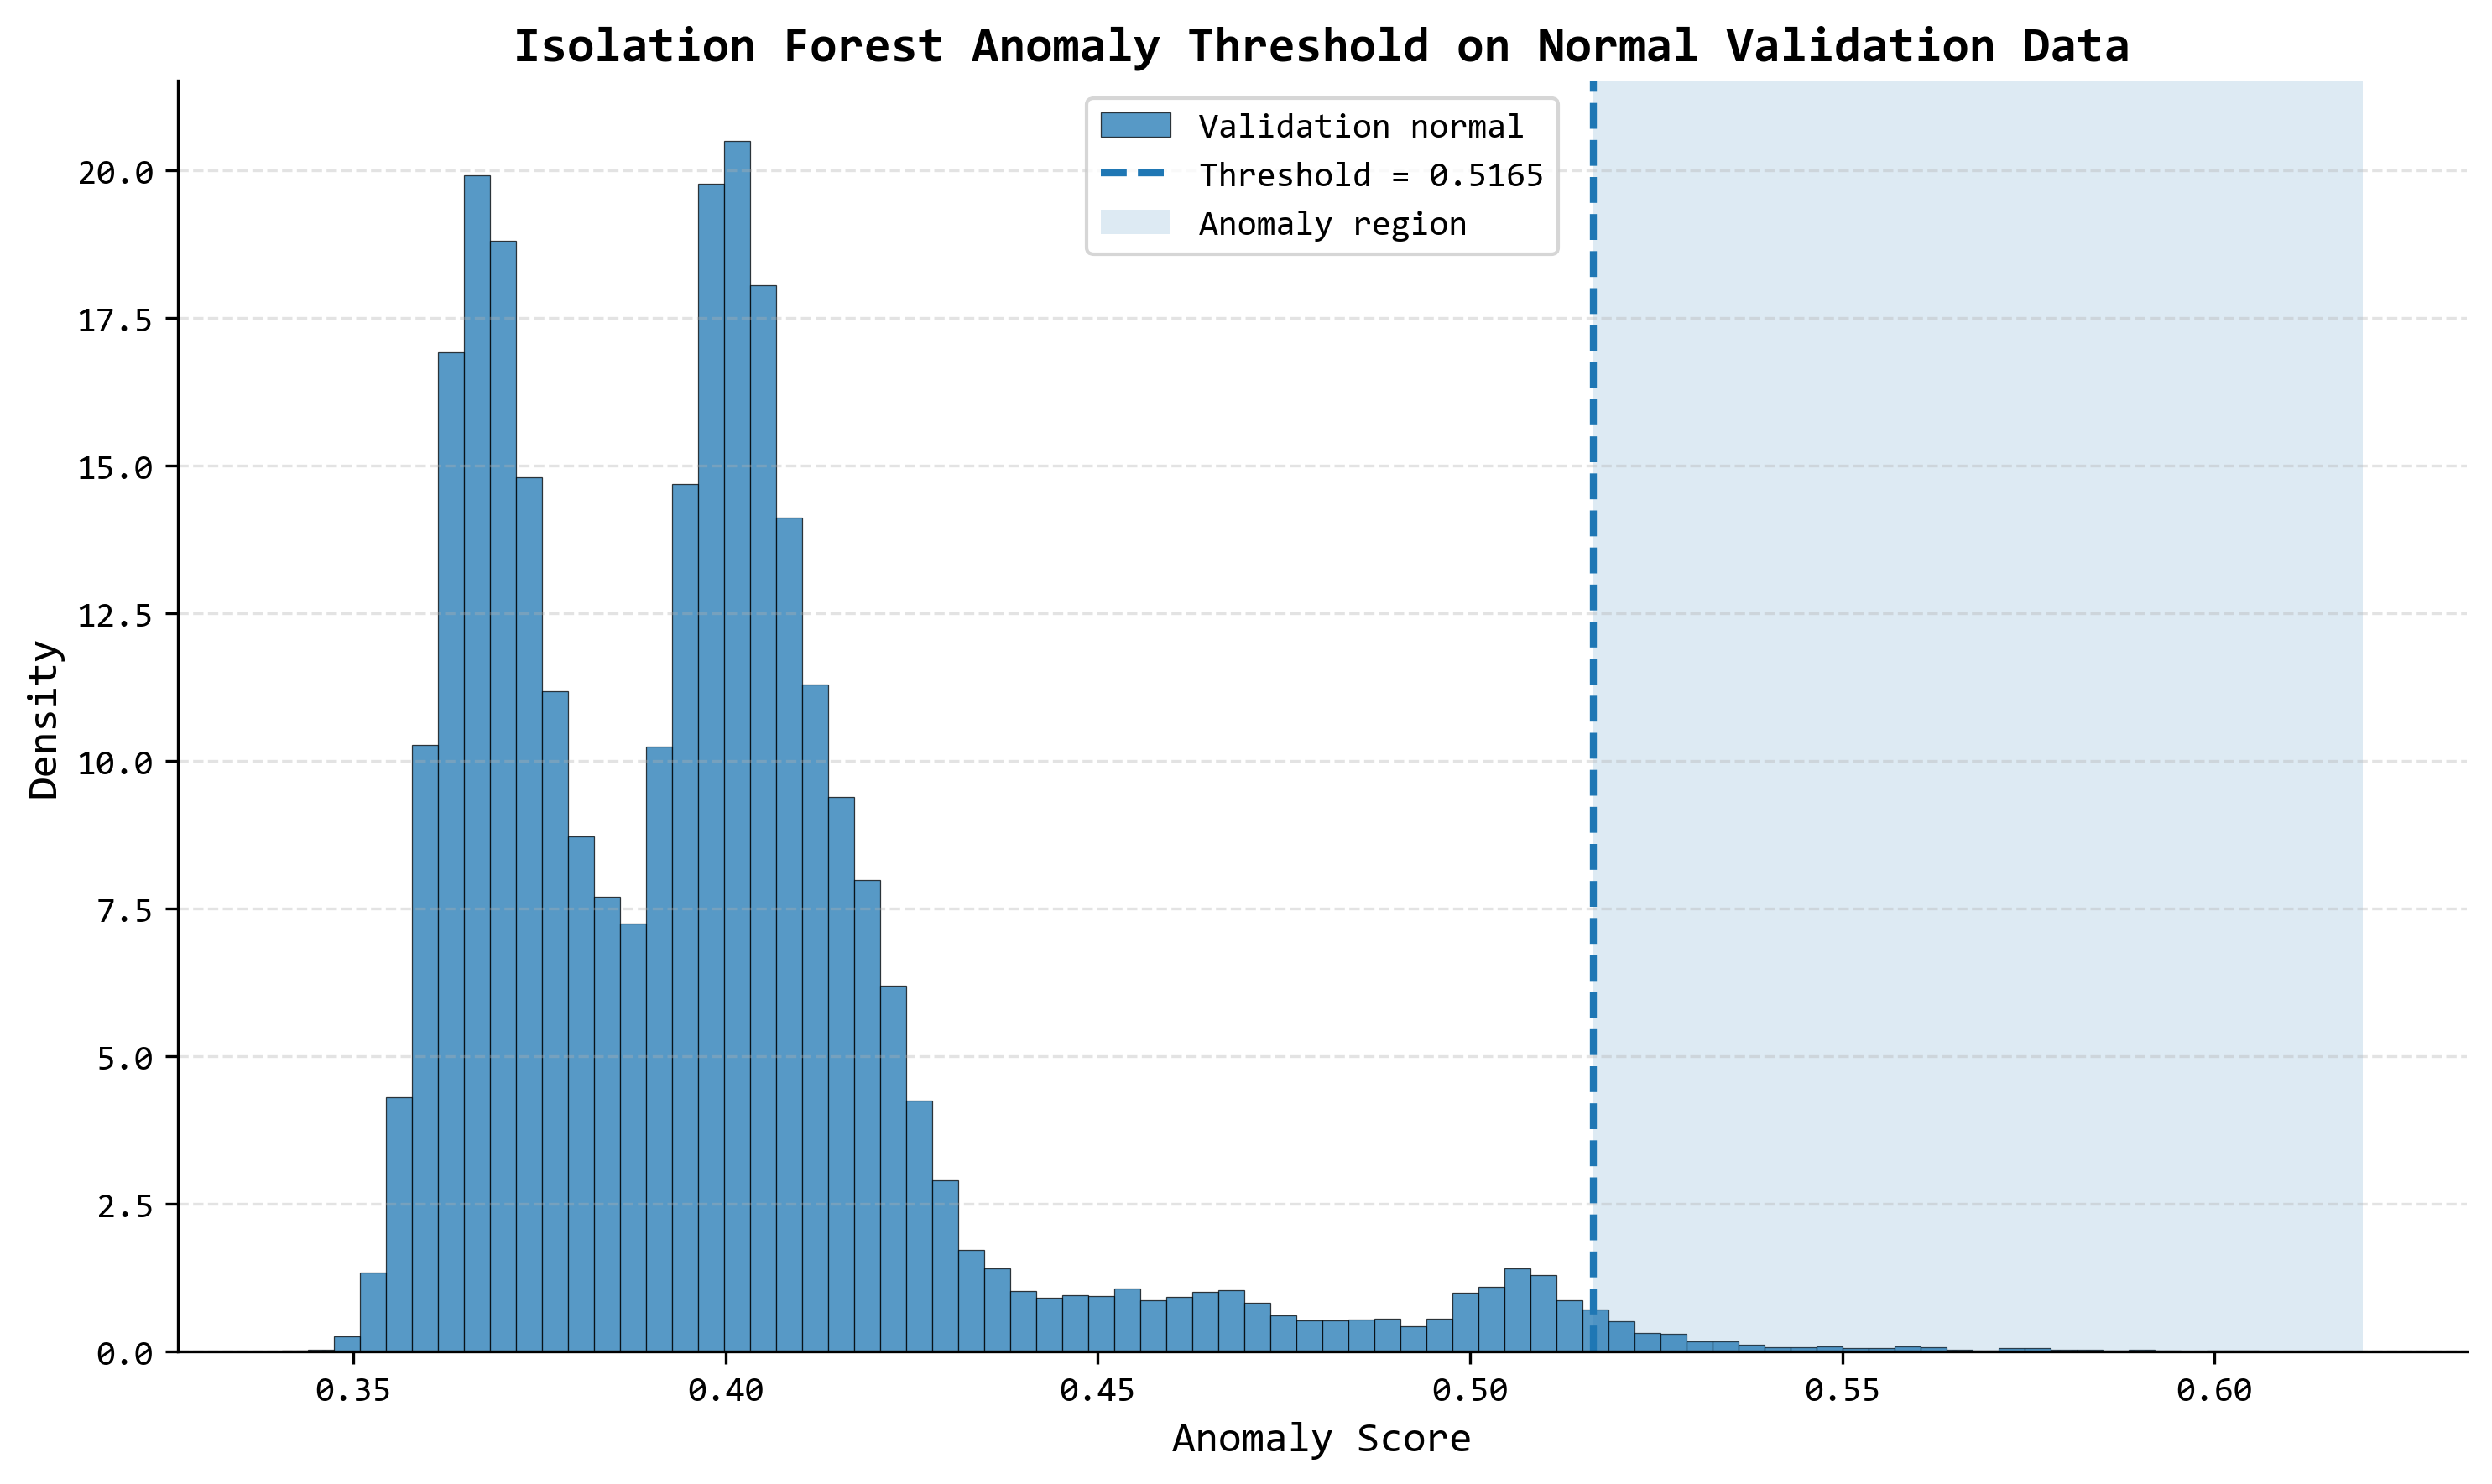

In [85]:
# ===================================
# Figure 14
# Visualisation du seuil d'anomalie
# ===================================


plt.rcParams[
    "font.family"
] = "Consolas"


fig, ax = plt.subplots(

    figsize=(
        10,
        6
    ),

    dpi=300

)


# ===================================
# Distribution des scores
# ===================================

ax.hist(

    val_anomaly_scores,

    bins=80,

    density=True,

    alpha=0.75,

    edgecolor="black",

    linewidth=0.3,

    label="Validation normal"

)


# ===================================
# Ligne du seuil
# ===================================

ax.axvline(

    anomaly_threshold,

    linestyle="--",

    linewidth=2.0,

    label=(
        f"Threshold = "
        f"{anomaly_threshold:.4f}"
    )

)


# ===================================
# Zone considérée anomalie
# ===================================

ax.axvspan(

    anomaly_threshold,

    val_anomaly_scores.max(),

    alpha=0.15,

    label="Anomaly region"

)


# ===================================
# Titre
# ===================================

ax.set_title(

    "Isolation Forest Anomaly Threshold on Normal Validation Data",

    fontsize=14,

    fontweight="bold",

    fontfamily="Consolas"

)


# ===================================
# Axes
# ===================================

ax.set_xlabel(

    "Anomaly Score",

    fontsize=12,

    fontfamily="Consolas"

)


ax.set_ylabel(

    "Density",

    fontsize=12,

    fontfamily="Consolas"

)


# ===================================
# Légende
# ===================================

ax.legend(

    fontsize=10,

    frameon=True

)


# ===================================
# Grille
# ===================================

ax.grid(

    axis="y",

    linestyle="--",

    alpha=0.35

)


# ===================================
# Bordures
# ===================================

ax.spines[
    "top"
].set_visible(False)


ax.spines[
    "right"
].set_visible(False)


plt.tight_layout()


# ===================================
# Sauvegarde
# ===================================

figure_name = (

    "isolation_forest_anomaly_threshold.png"

)


plt.savefig(

    figure_name,

    dpi=300,

    bbox_inches="tight"

)


plt.show()

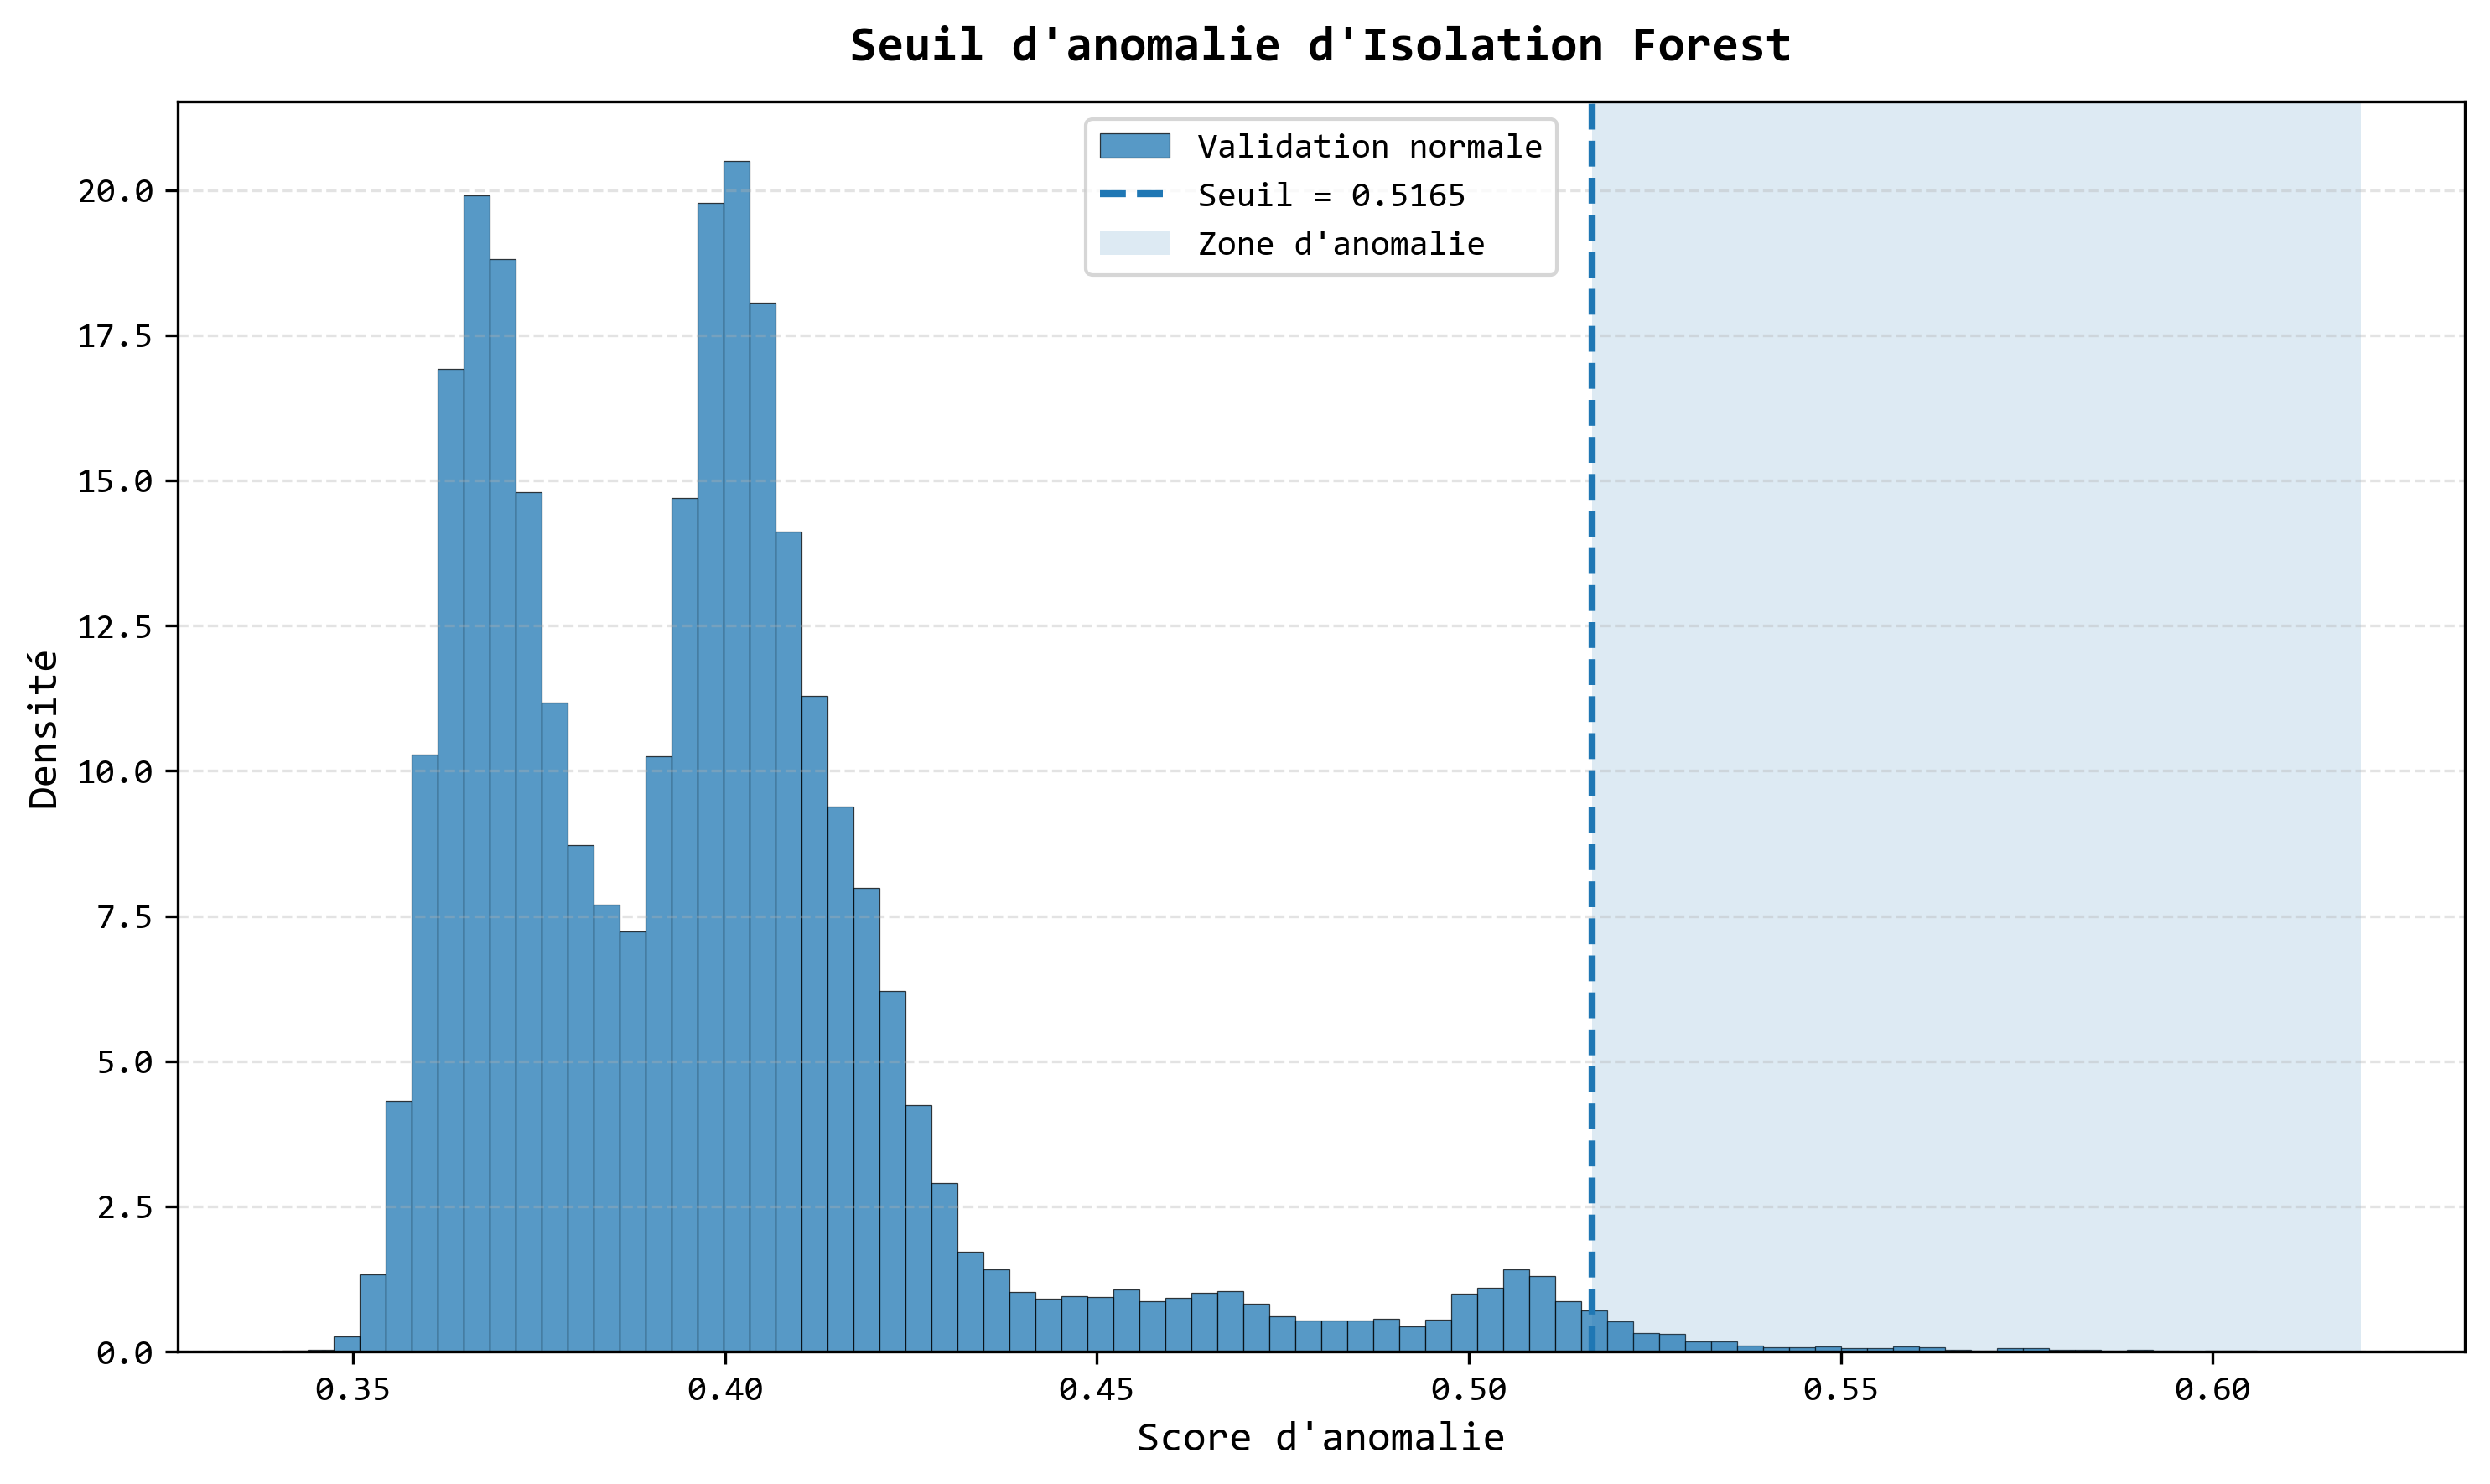

In [86]:
# ==========================================
# Visualisation du seuil d'anomalie
# ==========================================

# Police Consolas
plt.rcParams["font.family"] = "Consolas"


# Création du dossier
os.makedirs(
    "figures/evaluation",
    exist_ok=True
)


# ==========================================
# Création de la figure
# ==========================================

fig, ax = plt.subplots(
    figsize=(10,6),
    dpi=300
)


# ==========================================
# Distribution des scores d'anomalie
# ==========================================

ax.hist(
    val_anomaly_scores,
    bins=80,
    density=True,
    alpha=0.75,
    edgecolor="black",
    linewidth=0.3,
    label="Validation normale"
)


# ==========================================
# Seuil d'anomalie
# ==========================================

ax.axvline(
    anomaly_threshold,
    linestyle="--",
    linewidth=2,
    label=f"Seuil = {anomaly_threshold:.4f}"
)


# ==========================================
# Zone des anomalies
# ==========================================

ax.axvspan(
    anomaly_threshold,
    val_anomaly_scores.max(),
    alpha=0.15,
    label="Zone d'anomalie"
)


# ==========================================
# Titre
# ==========================================

ax.set_title(
    "Seuil d'anomalie d'Isolation Forest",
    fontsize=14,
    fontweight="bold",
    fontfamily="Consolas",
    pad=12
)


# ==========================================
# Axes
# ==========================================

ax.set_xlabel(
    "Score d'anomalie",
    fontsize=12,
    fontfamily="Consolas"
)

ax.set_ylabel(
    "Densité",
    fontsize=12,
    fontfamily="Consolas"
)


# ==========================================
# Légende et grille
# ==========================================

ax.legend(
    fontsize=10
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)


# ==========================================
# Mise en page
# ==========================================

plt.tight_layout()


# ==========================================
# Sauvegarde
# ==========================================

plt.savefig(
    "figures/evaluation/fr_isolation_forest_anomaly_threshold.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

In [94]:
# ===================================
# Détection finale sur le jeu de test
# ===================================

# ===================================
# Calcul des scores sur TEST
# ===================================

test_raw_scores = (

    isolation_forest

    .score_samples(
        X_test_if
    )

)


# ===================================
# Conversion en scores d'anomalie
#
# score élevé = plus anormal
# ===================================

test_anomaly_scores = (

    -test_raw_scores

)


# ===================================
# Prédictions finales
#
# 0 = Normal
# 1 = Attaque
# ===================================

y_pred_if = (

    test_anomaly_scores
    >
    anomaly_threshold

).astype(
    np.int8
)



# ===================================
# Distribution des prédictions
# ===================================

pred_unique, pred_counts = np.unique(

    y_pred_if,

    return_counts=True

)

# ===================================
# Matrice de confusion
# ===================================

cm = confusion_matrix(

    y_test_if,

    y_pred_if,

    labels=[
        0,
        1
    ]

)


tn, fp, fn, tp = cm.ravel()

# ===================================
# Métriques principales
# ===================================

accuracy = accuracy_score(

    y_test_if,

    y_pred_if

)


precision = precision_score(

    y_test_if,

    y_pred_if,

    zero_division=0

)


recall = recall_score(

    y_test_if,

    y_pred_if,

    zero_division=0

)


f1 = f1_score(

    y_test_if,

    y_pred_if,

    zero_division=0

)


# ===================================
# Spécificité
# ===================================

specificity = (

    tn
    /
    (tn + fp)

    if (tn + fp) > 0

    else 0

)


# ===================================
# Taux de faux positifs
# ===================================

false_positive_rate = (

    fp
    /
    (fp + tn)

    if (fp + tn) > 0

    else 0

)


# ===================================
# Taux de faux négatifs
# ===================================

false_negative_rate = (

    fn
    /
    (fn + tp)

    if (fn + tp) > 0

    else 0

)


# ===================================
# ROC-AUC
#
# On utilise les scores continus
# ===================================

roc_auc = roc_auc_score(

    y_test_if,

    test_anomaly_scores

)


# ===================================
# Average Precision
# ===================================

average_precision = average_precision_score(

    y_test_if,

    test_anomaly_scores

)


# ===================================
# Tableau récapitulatif
# ===================================

metrics_table = pd.DataFrame({

    "Metric": [

        "Accuracy",

        "Precision",

        "Recall",

        "F1-score",

        "Specificity",

        "ROC-AUC",

        "Average Precision",

        "False Positive Rate",

        "False Negative Rate"

    ],

    "Value": [

        accuracy,

        precision,

        recall,

        f1,

        specificity,

        roc_auc,

        average_precision,

        false_positive_rate,

        false_negative_rate

    ]

})

display(
    metrics_table
)

,Metric,Value
0,Accuracy,0.819814
1,Precision,0.471857
2,Recall,0.040378
3,F1-score,0.074390
4,Specificity,0.990125
5,ROC-AUC,0.957377
6,Average Precision,0.680438
7,False Positive Rate,0.009875
8,False Negative Rate,0.959622


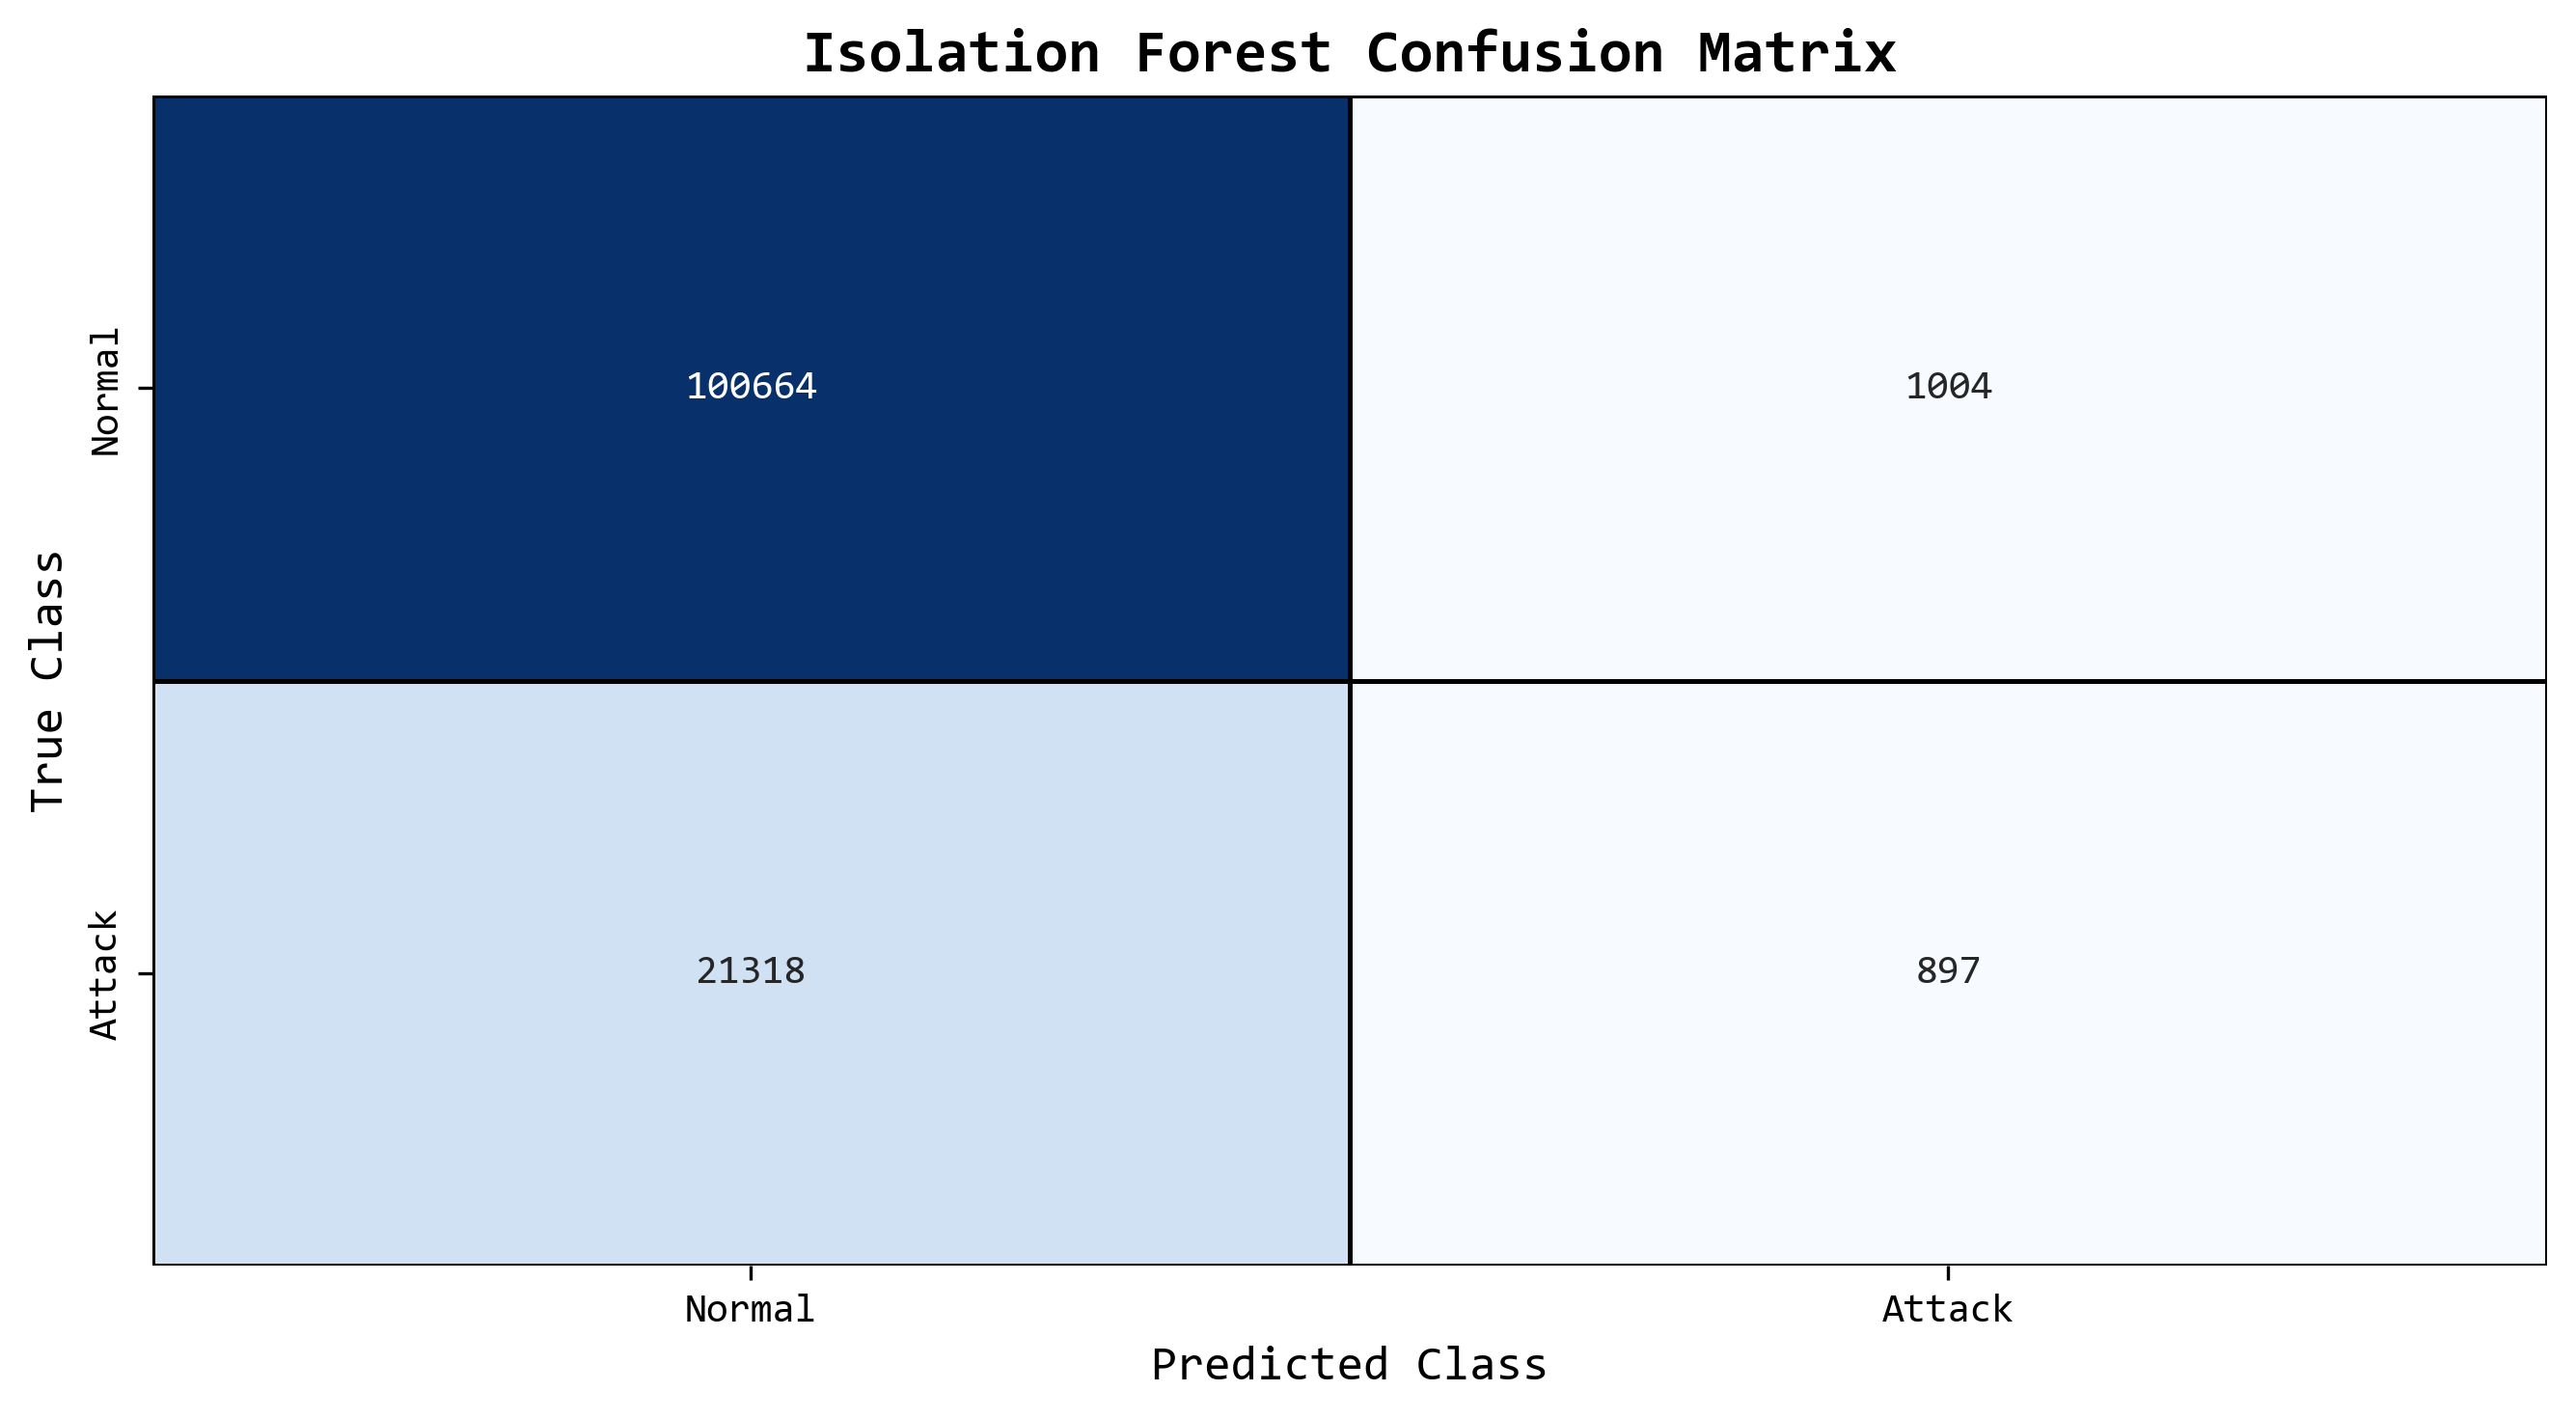

In [96]:
# ===================================
# Matrice de confusion
# Isolation Forest
# ===================================


plt.rcParams[
    "font.family"
] = "Consolas"


fig, ax = plt.subplots(

    figsize=(
        9,
        5
    ),

    dpi=300

)


# ===================================
# Heatmap
# ===================================

sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues",

    cbar=False,

    linewidths=0.8,

    linecolor="black",

    xticklabels=[
        "Normal",
        "Attack"
    ],

    yticklabels=[
        "Normal",
        "Attack"
    ],

    ax=ax

)


# ===================================
# Mise en forme
# ===================================

ax.set_title(

    "Isolation Forest Confusion Matrix",

    fontsize=15,

    fontweight="bold",

    fontfamily="Consolas"

)


ax.set_xlabel(

    "Predicted Class",

    fontsize=12,

    fontfamily="Consolas"

)


ax.set_ylabel(

    "True Class",

    fontsize=12,

    fontfamily="Consolas"

)


plt.tight_layout()


# ===================================
# Sauvegarde
# ===================================

figure_name = (

    "isolation_forest_confusion_matrix.png"

)


plt.savefig(

    figure_name,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


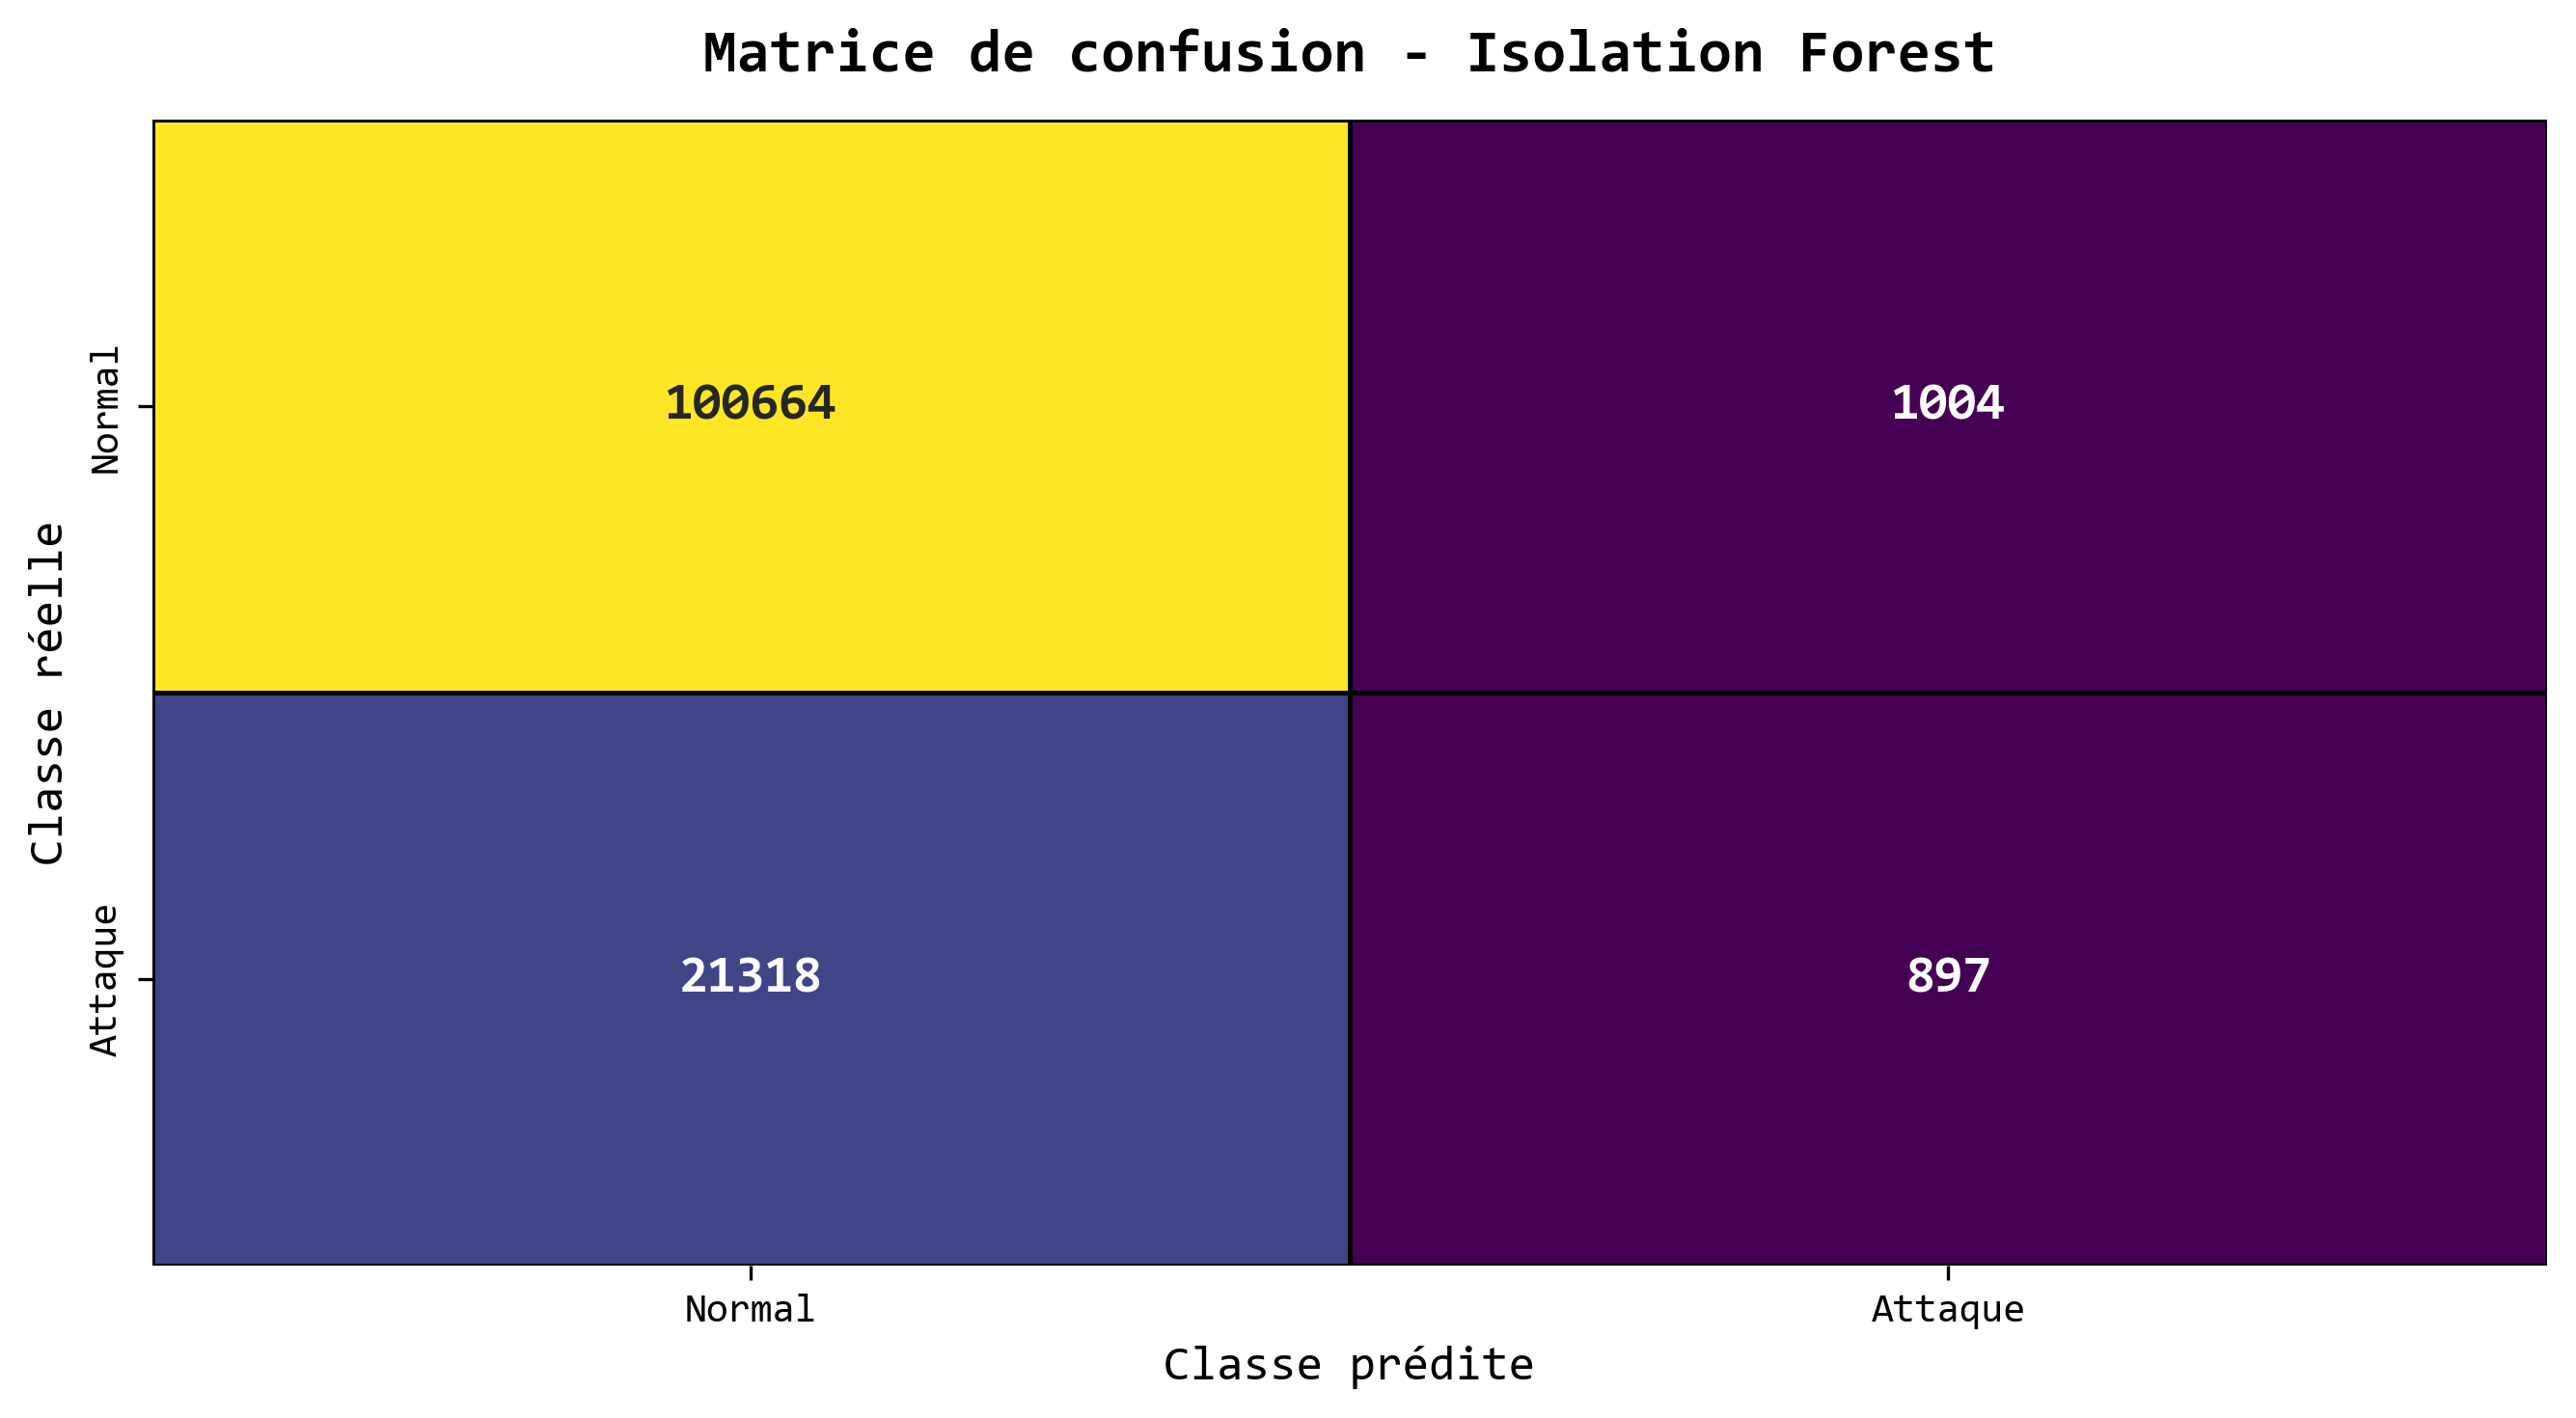

In [97]:
# ==========================================
# Matrice de confusion
# Isolation Forest
# ==========================================
# ==========================================
# Police Consolas
# ==========================================

plt.rcParams["font.family"] = "Consolas"


# ==========================================
# Création du dossier
# ==========================================

os.makedirs(
    "figures/evaluation",
    exist_ok=True
)


# ==========================================
# Création de la figure
# ==========================================

fig, ax = plt.subplots(
    figsize=(9,5),
    dpi=300
)


# ==========================================
# Matrice de confusion
# ==========================================

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="viridis",
    cbar=False,
    linewidths=0.8,
    linecolor="black",
    xticklabels=[
        "Normal",
        "Attaque"
    ],
    yticklabels=[
        "Normal",
        "Attaque"
    ],
    annot_kws={
        "fontsize":13,
        "fontfamily":"Consolas",
        "fontweight":"bold"
    },
    ax=ax
)


# ==========================================
# Mise en forme
# ==========================================

ax.set_title(
    "Matrice de confusion - Isolation Forest",
    fontsize=15,
    fontweight="bold",
    fontfamily="Consolas",
    pad=12
)


ax.set_xlabel(
    "Classe prédite",
    fontsize=12,
    fontfamily="Consolas"
)


ax.set_ylabel(
    "Classe réelle",
    fontsize=12,
    fontfamily="Consolas"
)


# ==========================================
# Ajustement
# ==========================================

plt.tight_layout()


# ==========================================
# Sauvegarde
# ==========================================

plt.savefig(
    "figures/evaluation/fr_isolation_forest_confusion_matrix.png",
    format="png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

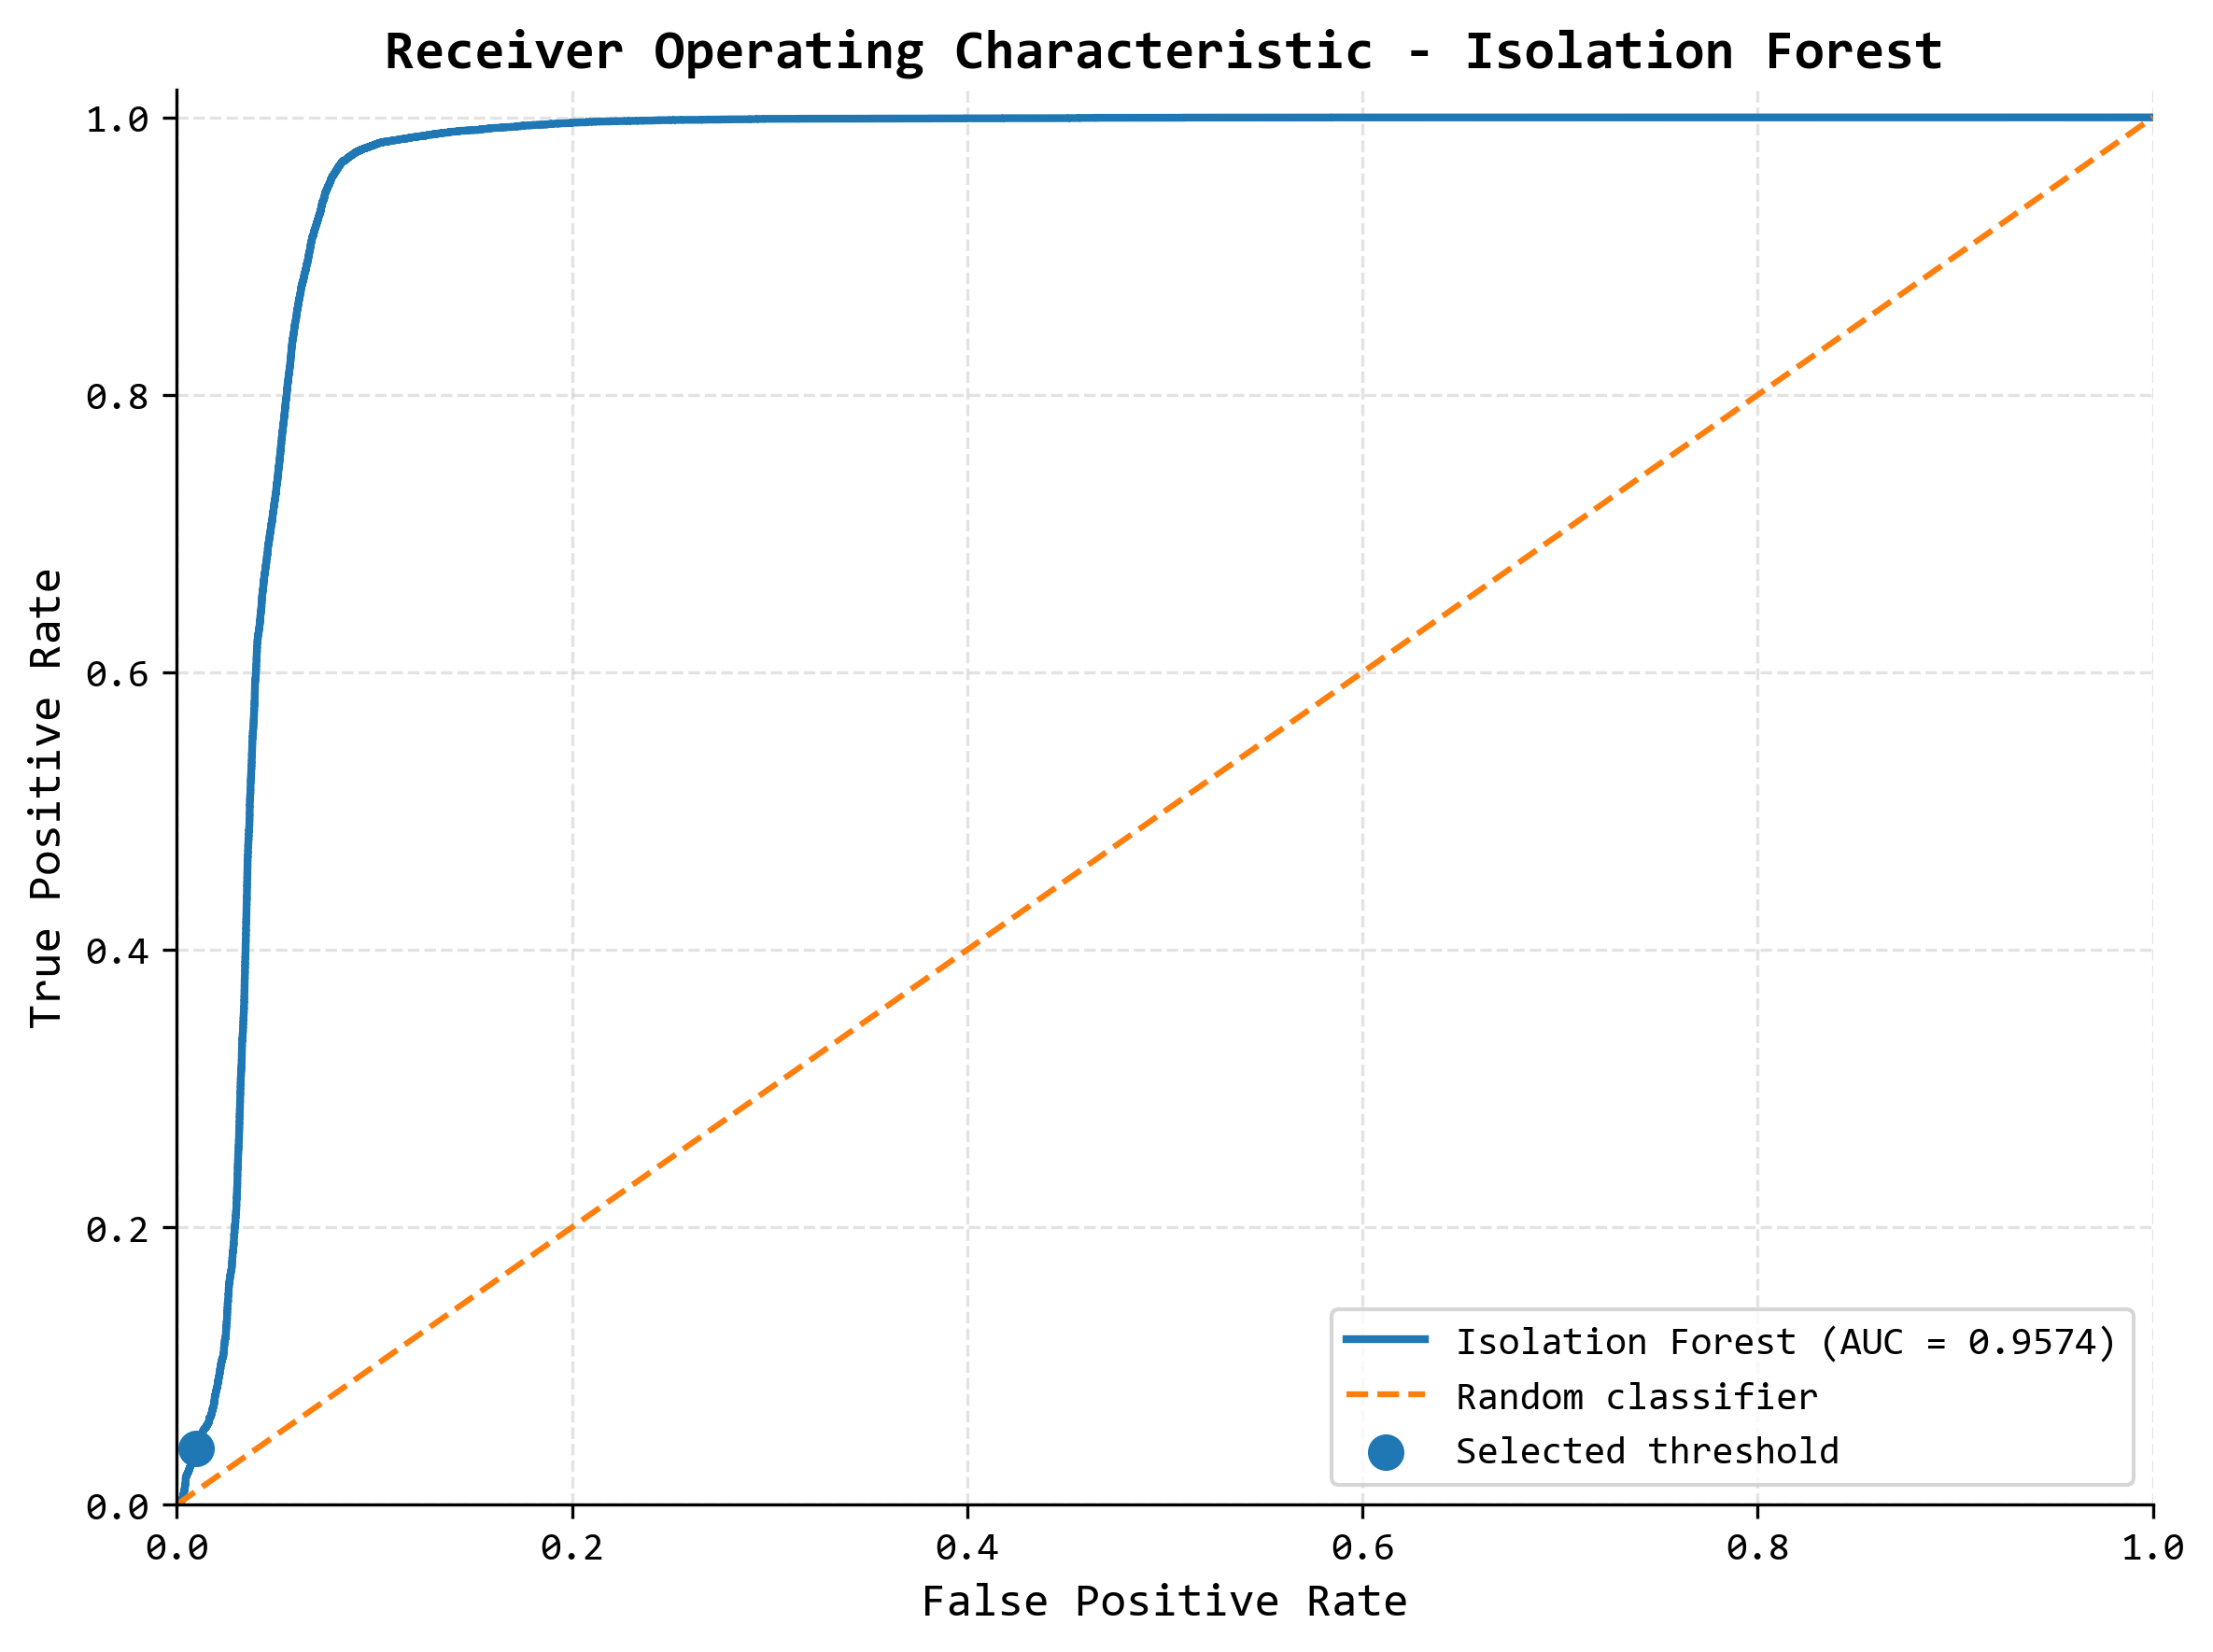

In [100]:
# ===================================
# Courbe ROC
# Isolation Forest
# ===================================

# ===================================
# Calcul de la courbe ROC
# ===================================

fpr, tpr, roc_thresholds = roc_curve(

    y_test_if,

    test_anomaly_scores

)


# ===================================
# Calcul de l'AUC
# ===================================

roc_auc_value = roc_auc_score(

    y_test_if,

    test_anomaly_scores

)



# ===================================
# Configuration graphique
# ===================================

plt.rcParams[
    "font.family"
] = "Consolas"


fig, ax = plt.subplots(

    figsize=(
        8,
        6
    ),

    dpi=300

)


# ===================================
# Courbe ROC
# ===================================

ax.plot(

    fpr,

    tpr,

    linewidth=2.0,

    label=(
        f"Isolation Forest "
        f"(AUC = {roc_auc_value:.4f})"
    )

)


# ===================================
# Ligne aléatoire
# ===================================

ax.plot(

    [0, 1],

    [0, 1],

    linestyle="--",

    linewidth=1.5,

    label="Random classifier"

)


# ===================================
# Point correspondant
# au seuil choisi
# ===================================

threshold_predictions = (

    test_anomaly_scores
    >
    anomaly_threshold

).astype(
    np.int8
)


threshold_cm = confusion_matrix(

    y_test_if,

    threshold_predictions,

    labels=[
        0,
        1
    ]

)


tn_t, fp_t, fn_t, tp_t = (

    threshold_cm.ravel()

)


threshold_fpr = (

    fp_t
    /
    (fp_t + tn_t)

    if (fp_t + tn_t) > 0

    else 0

)


threshold_tpr = (

    tp_t
    /
    (tp_t + fn_t)

    if (tp_t + fn_t) > 0

    else 0

)


ax.scatter(

    threshold_fpr,

    threshold_tpr,

    s=70,

    zorder=5,

    label=(
        "Selected threshold"
    )

)


# ===================================
# Mise en forme
# ===================================

ax.set_title(

    "Receiver Operating Characteristic - Isolation Forest",

    fontsize=14,

    fontweight="bold",

    fontfamily="Consolas"

)


ax.set_xlabel(

    "False Positive Rate",

    fontsize=12,

    fontfamily="Consolas"

)


ax.set_ylabel(

    "True Positive Rate",

    fontsize=12,

    fontfamily="Consolas"

)


ax.set_xlim(
    0,
    1
)


ax.set_ylim(
    0,
    1.02
)


ax.grid(

    linestyle="--",

    alpha=0.35

)


ax.legend(

    loc="lower right",

    fontsize=10,

    frameon=True

)


ax.spines[
    "top"
].set_visible(False)


ax.spines[
    "right"
].set_visible(False)


plt.tight_layout()


# ===================================
# Sauvegarde
# ===================================

figure_name = (

    "isolation_forest_roc_curve.png"

)


plt.savefig(

    figure_name,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


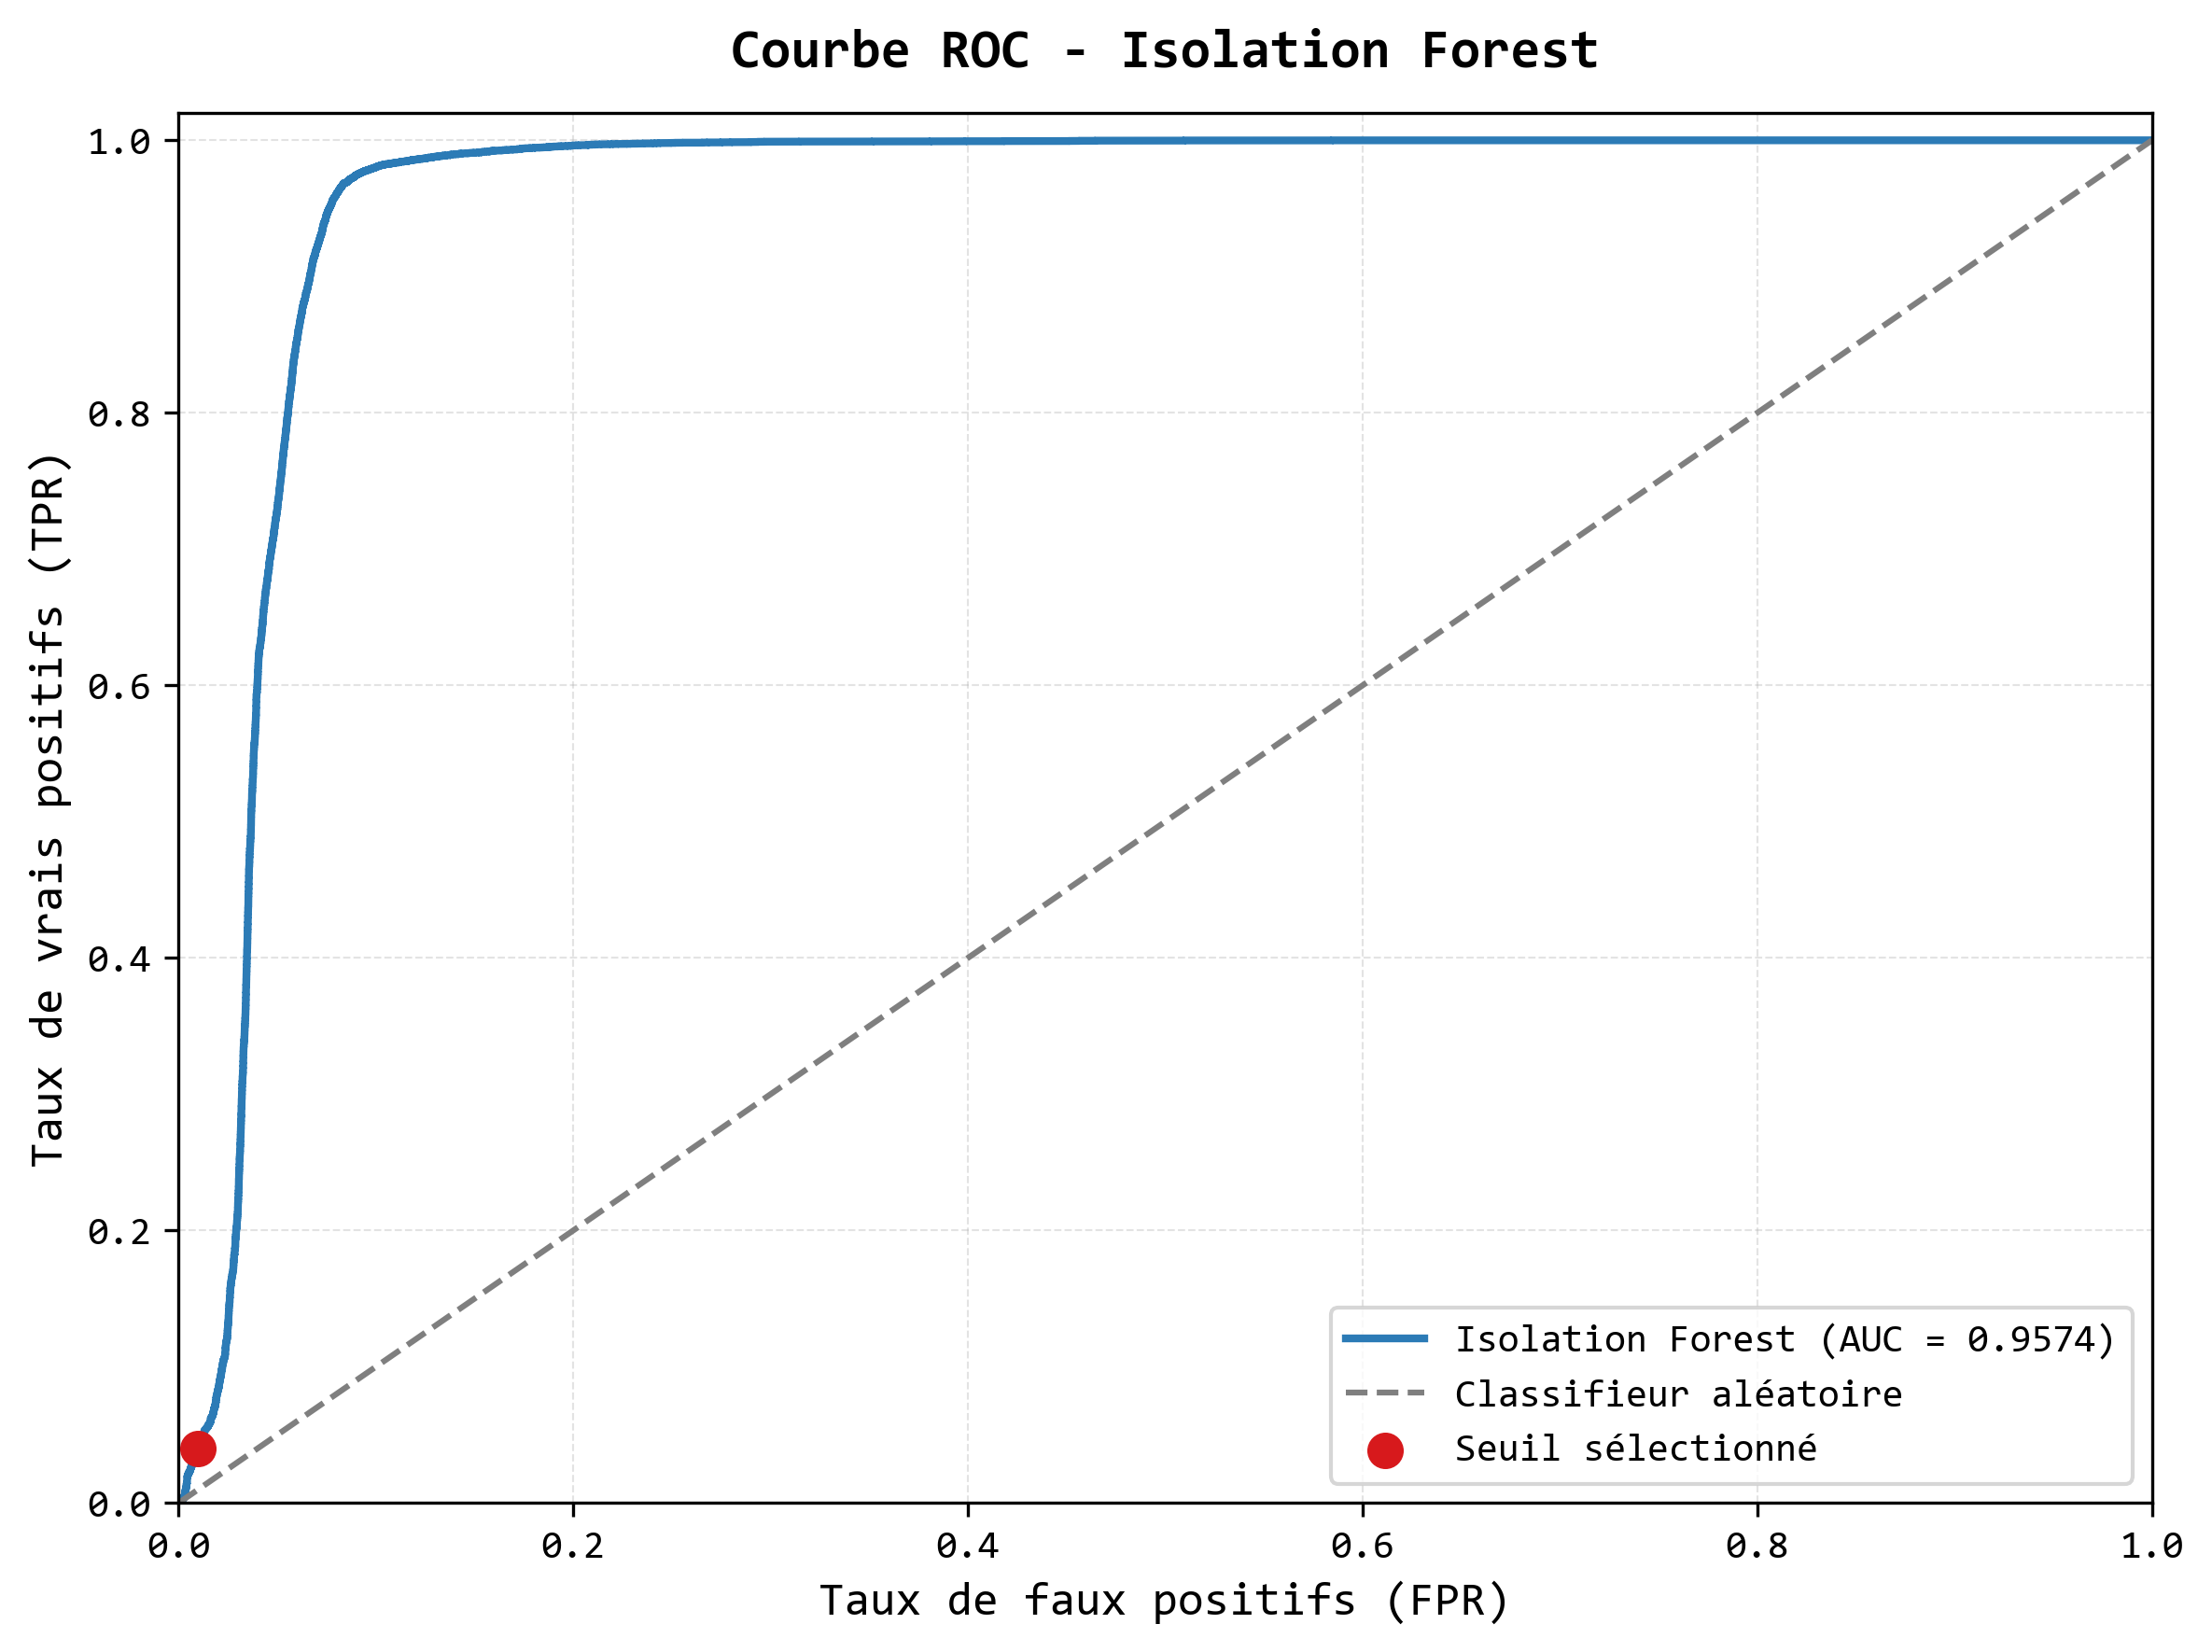

In [101]:
# ==========================================
# Courbe ROC - Isolation Forest
# ==========================================

# ==========================================
# Création du dossier
# ==========================================

os.makedirs(
    "figures/evaluation",
    exist_ok=True
)


# ==========================================
# Calcul de la courbe ROC
# ==========================================

fpr, tpr, roc_thresholds = roc_curve(
    y_test_if,
    test_anomaly_scores
)


# ==========================================
# Calcul de l'AUC
# ==========================================

roc_auc_value = roc_auc_score(
    y_test_if,
    test_anomaly_scores
)




# ==========================================
# Configuration graphique
# ==========================================

plt.rcParams["font.family"] = "Consolas"


fig, ax = plt.subplots(
    figsize=(8,6),
    dpi=300
)


# ==========================================
# Courbe ROC
# ==========================================

ax.plot(
    fpr,
    tpr,
    linewidth=2,
    color="#2C7BB6",
    label=f"Isolation Forest (AUC = {roc_auc_value:.4f})"
)


# ==========================================
# Classifieur aléatoire
# ==========================================

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    color="#7F7F7F",
    label="Classifieur aléatoire"
)


# ==========================================
# Performance au seuil sélectionné
# ==========================================

threshold_predictions = (
    test_anomaly_scores > anomaly_threshold
).astype(np.int8)


threshold_cm = confusion_matrix(
    y_test_if,
    threshold_predictions,
    labels=[0, 1]
)


tn, fp, fn, tp = threshold_cm.ravel()


threshold_fpr = (
    fp / (fp + tn)
    if (fp + tn) > 0
    else 0
)


threshold_tpr = (
    tp / (tp + fn)
    if (tp + fn) > 0
    else 0
)


ax.scatter(
    threshold_fpr,
    threshold_tpr,
    s=70,
    color="#D7191C",
    zorder=5,
    label="Seuil sélectionné"
)


# ==========================================
# Mise en forme
# ==========================================

ax.set_title(
    "Courbe ROC - Isolation Forest",
    fontsize=14,
    fontweight="bold",
    fontfamily="Consolas",
    pad=12
)


ax.set_xlabel(
    "Taux de faux positifs (FPR)",
    fontsize=12,
    fontfamily="Consolas"
)


ax.set_ylabel(
    "Taux de vrais positifs (TPR)",
    fontsize=12,
    fontfamily="Consolas"
)


ax.set_xlim(
    0,
    1
)

ax.set_ylim(
    0,
    1.02
)


ax.grid(
    linestyle="--",
    linewidth=0.5,
    alpha=0.35
)


ax.legend(
    loc="lower right",
    fontsize=10
)


# ==========================================
# Ajustement
# ==========================================

plt.tight_layout()


# ==========================================
# Sauvegarde
# ==========================================

plt.savefig(
    "figures/evaluation/fr_isolation_forest_roc_curve.png",
    format="png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()


Average Precision : 0.6804


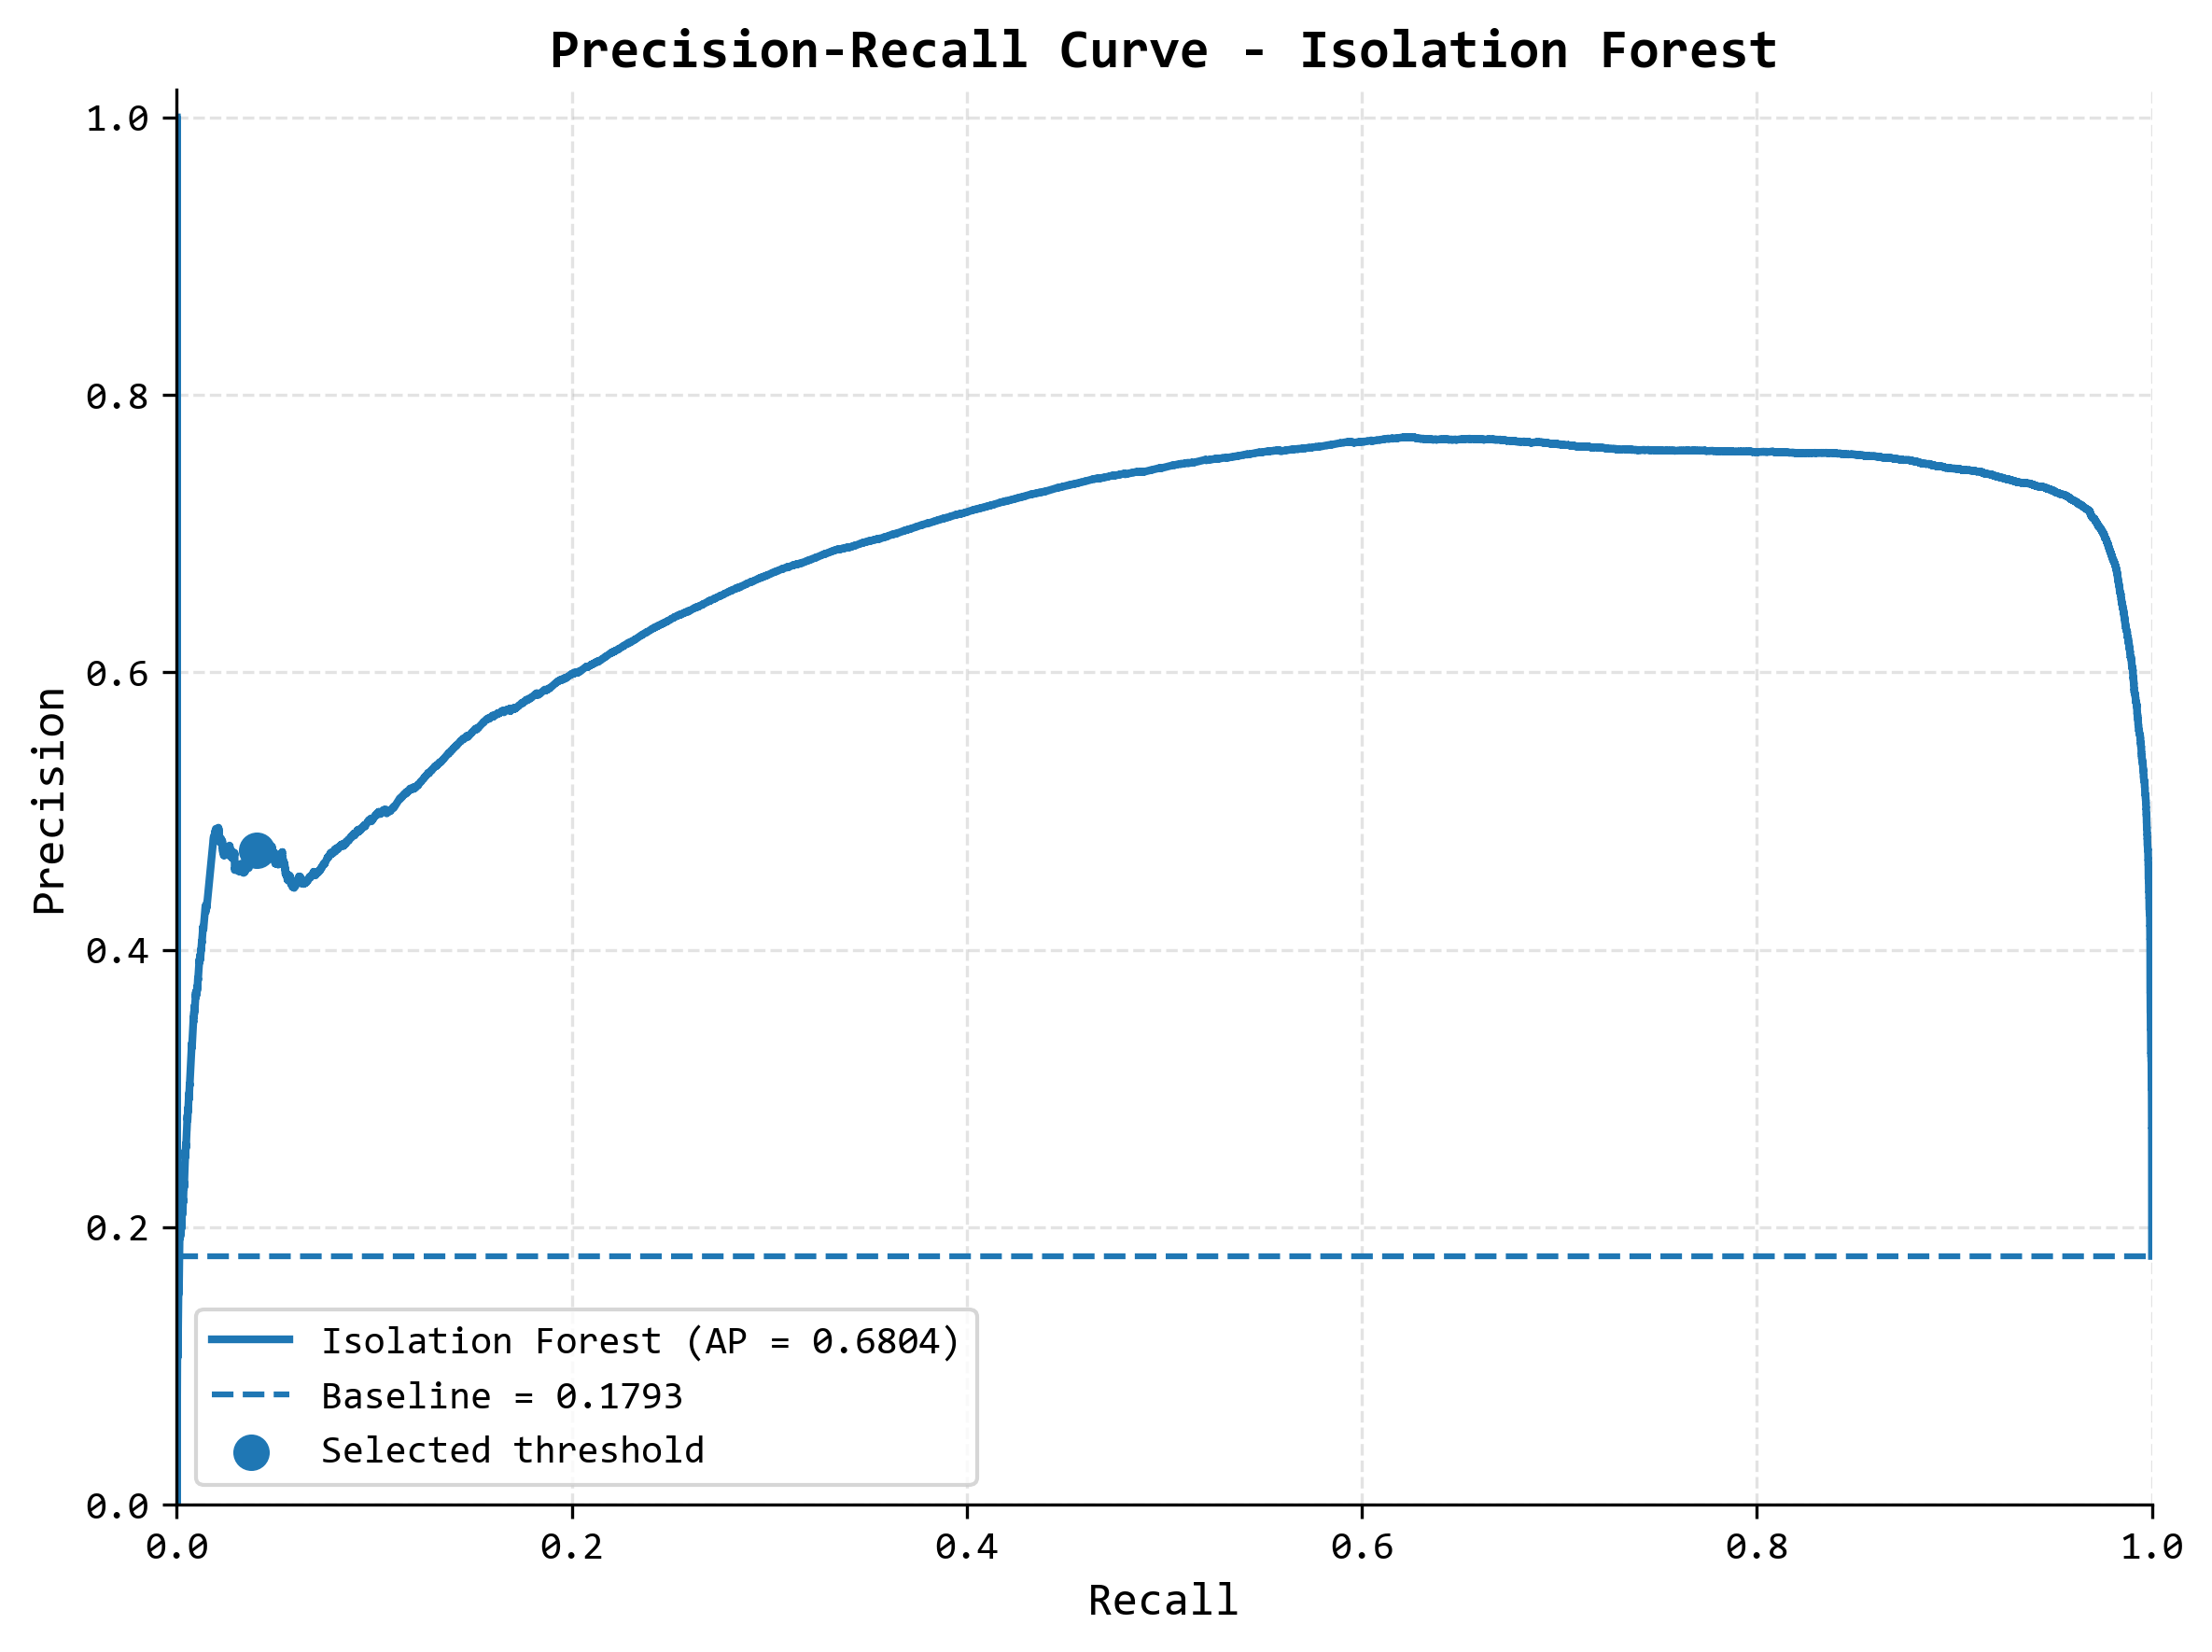

In [103]:
# ===================================
# Courbe Precision-Recall
# Isolation Forest
# ===================================

# ==================================
# Calcul de la courbe
# ===================================

precision_curve, recall_curve, pr_thresholds = (

    precision_recall_curve(

        y_test_if,

        test_anomaly_scores

    )

)


# ===================================
# Average Precision
# ===================================

average_precision_value = (

    average_precision_score(

        y_test_if,

        test_anomaly_scores

    )

)


print(
    "\nAverage Precision :",
    f"{average_precision_value:.4f}"
)


# ===================================
# Configuration graphique
# ===================================

plt.rcParams[
    "font.family"
] = "Consolas"


fig, ax = plt.subplots(

    figsize=(
        8,
        6
    ),

    dpi=300

)


# ===================================
# Courbe Precision-Recall
# ===================================

ax.plot(

    recall_curve,

    precision_curve,

    linewidth=2.0,

    label=(
        f"Isolation Forest "
        f"(AP = {average_precision_value:.4f})"
    )

)


# ===================================
# Baseline
#
# proportion d'attaques
# dans le jeu de test
# ===================================

positive_ratio = (

    np.mean(
        y_test_if
    )

)


ax.axhline(

    positive_ratio,

    linestyle="--",

    linewidth=1.5,

    label=(
        f"Baseline = {positive_ratio:.4f}"
    )

)


# ===================================
# Point associé au seuil retenu
# ===================================

selected_precision = precision_score(

    y_test_if,

    y_pred_if,

    zero_division=0

)


selected_recall = recall_score(

    y_test_if,

    y_pred_if,

    zero_division=0

)


ax.scatter(

    selected_recall,

    selected_precision,

    s=70,

    zorder=5,

    label="Selected threshold"

)


# ===================================
# Mise en forme
# ===================================

ax.set_title(

    "Precision-Recall Curve - Isolation Forest",

    fontsize=14,

    fontweight="bold",

    fontfamily="Consolas"

)


ax.set_xlabel(

    "Recall",

    fontsize=12,

    fontfamily="Consolas"

)


ax.set_ylabel(

    "Precision",

    fontsize=12,

    fontfamily="Consolas"

)


ax.set_xlim(
    0,
    1
)


ax.set_ylim(
    0,
    1.02
)


ax.grid(

    linestyle="--",

    alpha=0.35

)


ax.legend(

    loc="lower left",

    fontsize=10,

    frameon=True

)


ax.spines[
    "top"
].set_visible(False)


ax.spines[
    "right"
].set_visible(False)


plt.tight_layout()


# ===================================
# Sauvegarde
# ===================================

figure_name = (

    "isolation_forest_precision_recall_curve.png"

)


plt.savefig(

    figure_name,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


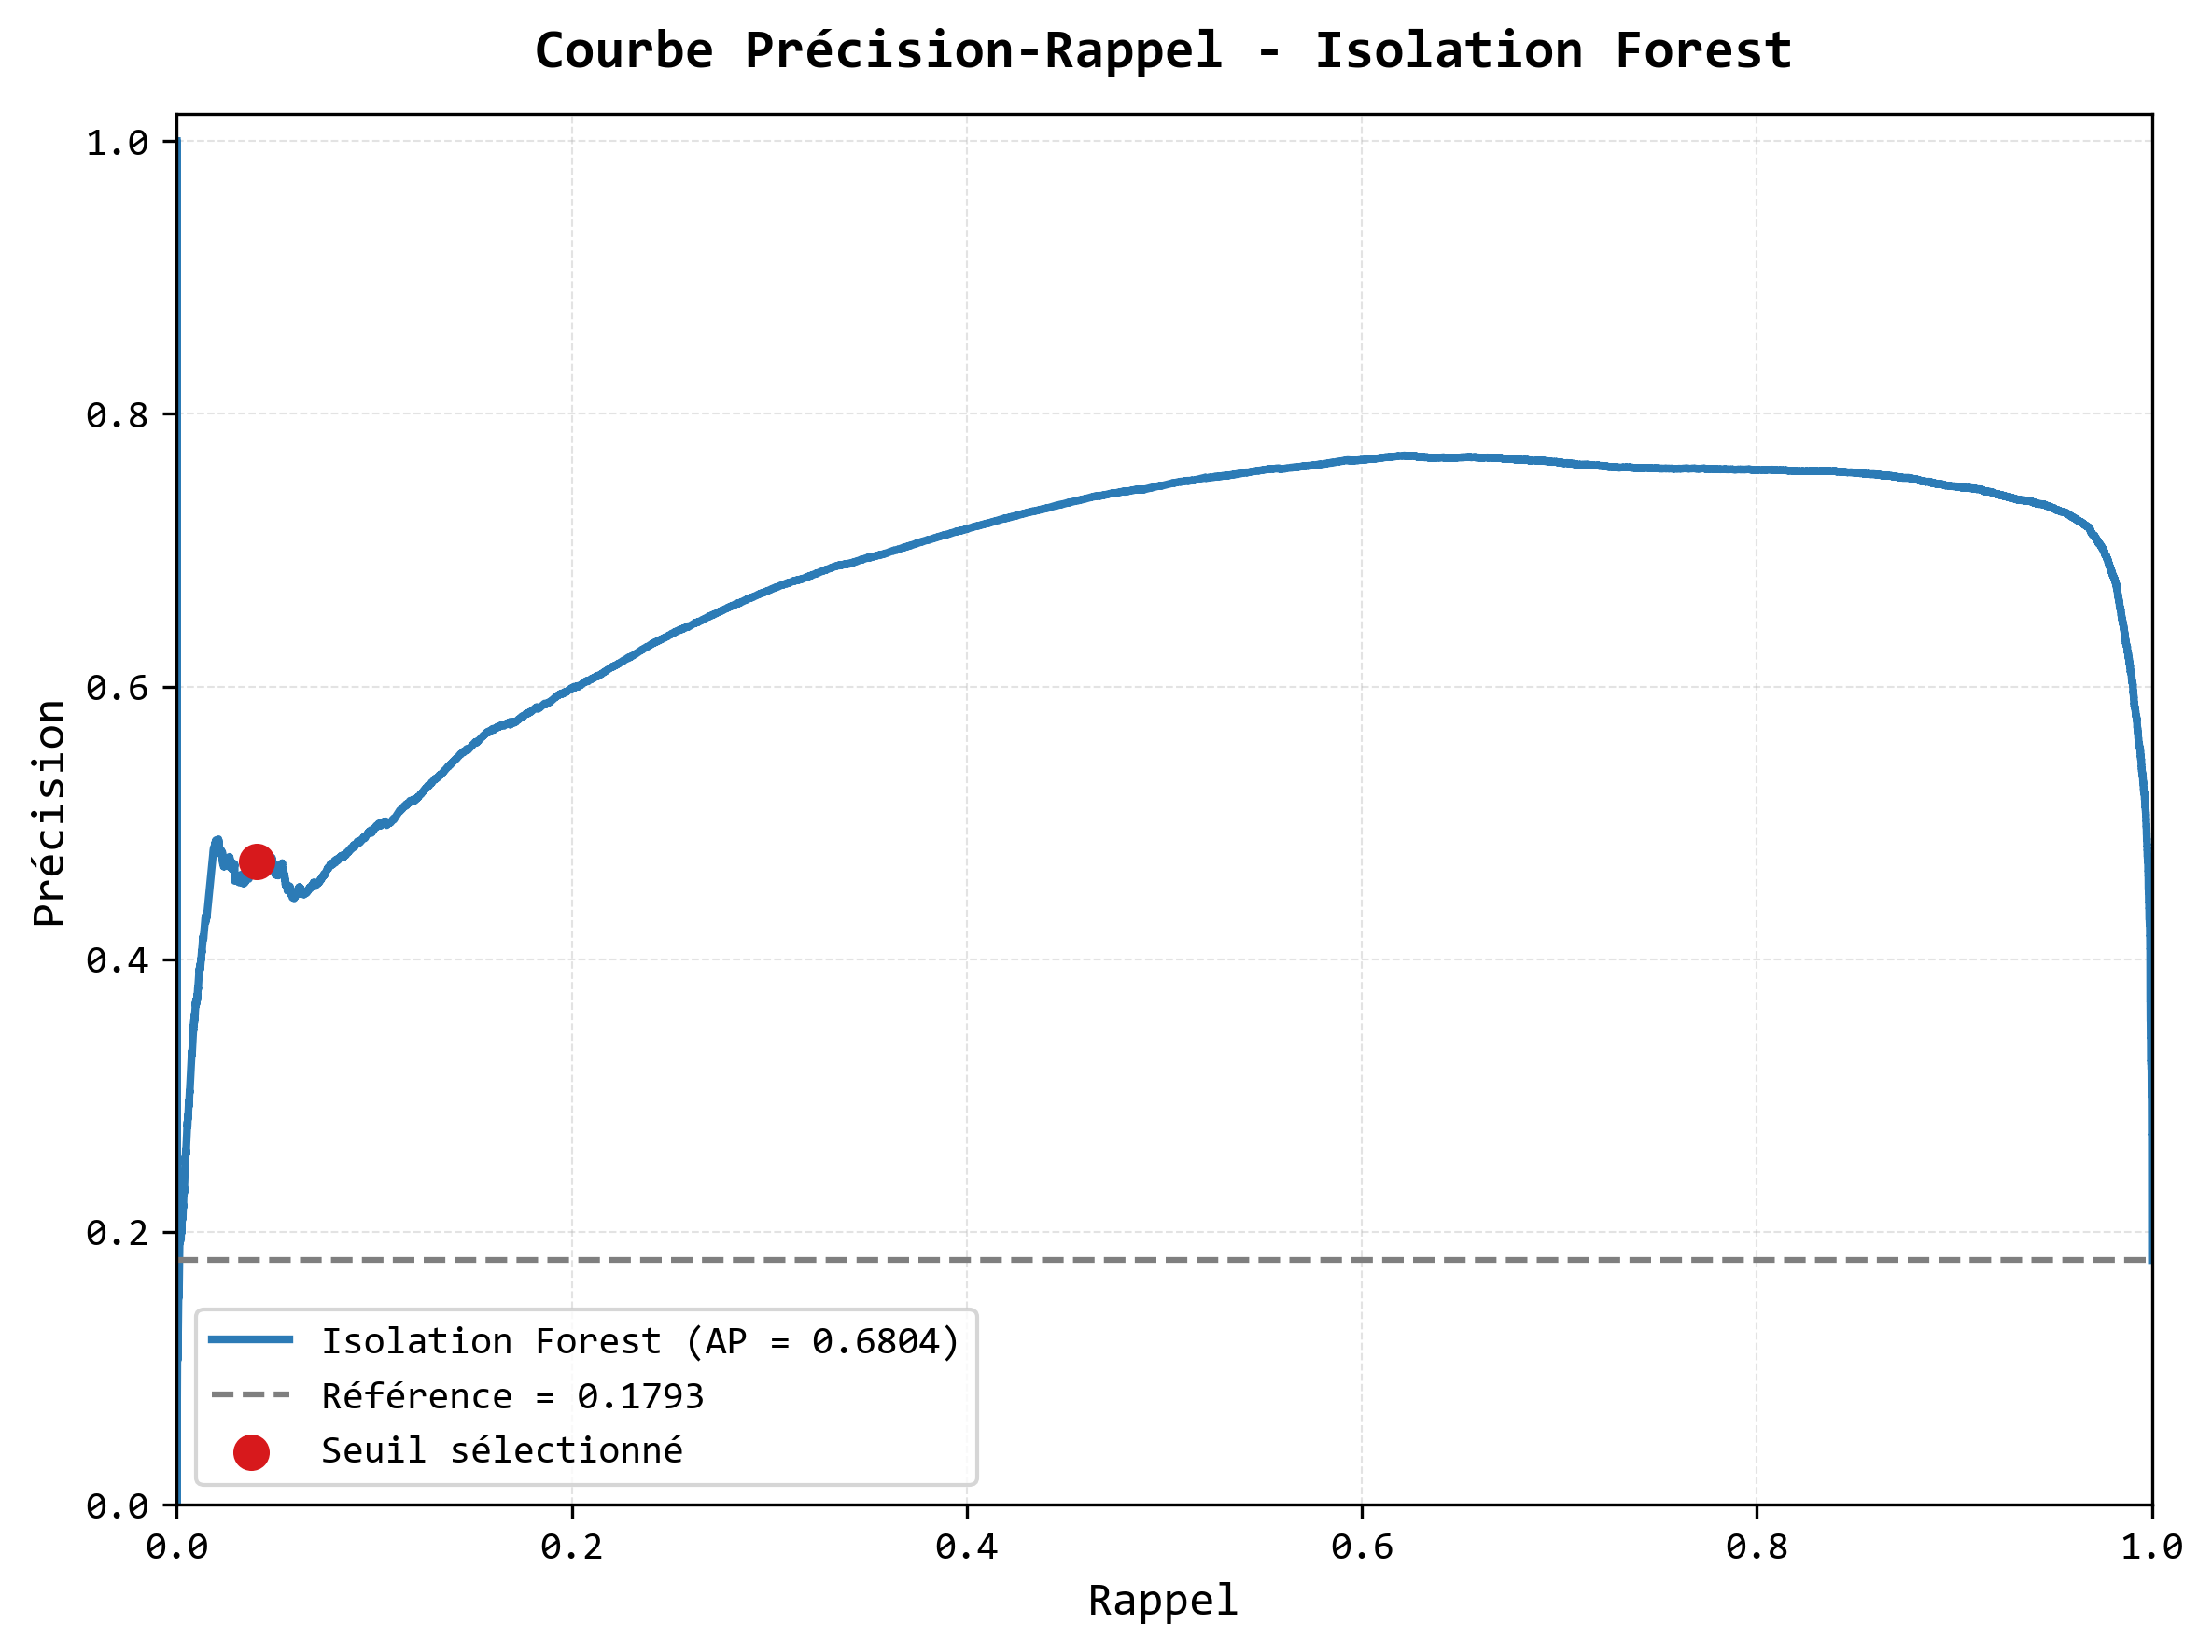

In [104]:
# ==========================================
# Courbe Précision-Rappel
# Isolation Forest
# ==========================================


# ==========================================
# Création du dossier
# ==========================================

os.makedirs(
    "figures/evaluation",
    exist_ok=True
)


# ==========================================
# Calcul de la courbe
# ==========================================

precision_curve, recall_curve, pr_thresholds = (
    precision_recall_curve(
        y_test_if,
        test_anomaly_scores
    )
)


# ==========================================
# Average Precision
# ==========================================

average_precision_value = average_precision_score(
    y_test_if,
    test_anomaly_scores
)



# ==========================================
# Configuration graphique
# ==========================================

plt.rcParams["font.family"] = "Consolas"


fig, ax = plt.subplots(
    figsize=(8,6),
    dpi=300
)


# ==========================================
# Courbe Précision-Rappel
# ==========================================

ax.plot(
    recall_curve,
    precision_curve,
    linewidth=2,
    color="#2C7BB6",
    label=(
        f"Isolation Forest "
        f"(AP = {average_precision_value:.4f})"
    )
)


# ==========================================
# Ligne de référence
# ==========================================

positive_ratio = np.mean(
    y_test_if
)


ax.axhline(
    positive_ratio,
    linestyle="--",
    linewidth=1.5,
    color="#7F7F7F",
    label=f"Référence = {positive_ratio:.4f}"
)


# ==========================================
# Point correspondant au seuil retenu
# ==========================================

selected_precision = precision_score(
    y_test_if,
    y_pred_if,
    zero_division=0
)


selected_recall = recall_score(
    y_test_if,
    y_pred_if,
    zero_division=0
)


ax.scatter(
    selected_recall,
    selected_precision,
    s=70,
    color="#D7191C",
    zorder=5,
    label="Seuil sélectionné"
)


# ==========================================
# Mise en forme
# ==========================================

ax.set_title(
    "Courbe Précision-Rappel - Isolation Forest",
    fontsize=14,
    fontweight="bold",
    fontfamily="Consolas",
    pad=12
)


ax.set_xlabel(
    "Rappel",
    fontsize=12,
    fontfamily="Consolas"
)


ax.set_ylabel(
    "Précision",
    fontsize=12,
    fontfamily="Consolas"
)


ax.set_xlim(
    0,
    1
)

ax.set_ylim(
    0,
    1.02
)


ax.grid(
    linestyle="--",
    linewidth=0.5,
    alpha=0.35
)


ax.legend(
    loc="lower left",
    fontsize=10
)


# ==========================================
# Ajustement
# ==========================================

plt.tight_layout()


# ==========================================
# Sauvegarde
# ==========================================

plt.savefig(
    "figures/evaluation/fr_isolation_forest_precision_recall_curve.png",
    format="png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

In [107]:
# ===================================
# Cellule 18
# Distribution des scores d'anomalie
# Normal vs Attaque
# ===================================

# ===================================
# Séparation des scores
# selon la vraie classe
# ===================================

normal_test_scores = (

    test_anomaly_scores[
        y_test_if == 0
    ]

)


attack_test_scores = (

    test_anomaly_scores[
        y_test_if == 1
    ]

)


# ===================================
# Pourcentage au-dessus du seuil
# ===================================

normal_above_threshold = (

    np.mean(
        normal_test_scores
        >
        anomaly_threshold
    )

    * 100

)


attack_above_threshold = (

    np.mean(
        attack_test_scores
        >
        anomaly_threshold
    )

    * 100

)

# ===================================
# Tableau récapitulatif
# ===================================

score_class_summary = pd.DataFrame({

    "Classe": [
        "Normal",
        "Attack"
    ],

    "Nombre": [
        len(normal_test_scores),
        len(attack_test_scores)
    ],

    "Moyenne": [
        normal_test_scores.mean(),
        attack_test_scores.mean()
    ],

    "Médiane": [
        np.median(normal_test_scores),
        np.median(attack_test_scores)
    ],

    "Écart-type": [
        normal_test_scores.std(),
        attack_test_scores.std()
    ],

    "Au-dessus du seuil (%)": [
        normal_above_threshold,
        attack_above_threshold
    ]

})


display(
    score_class_summary
)

,Classe,Nombre,Moyenne,Médiane,Écart-type,Au-dessus du seuil (%)
0,Normal,101668,0.397273,0.395598,0.033002,0.987528
1,Attack,22215,0.480626,0.484883,0.022933,4.037812


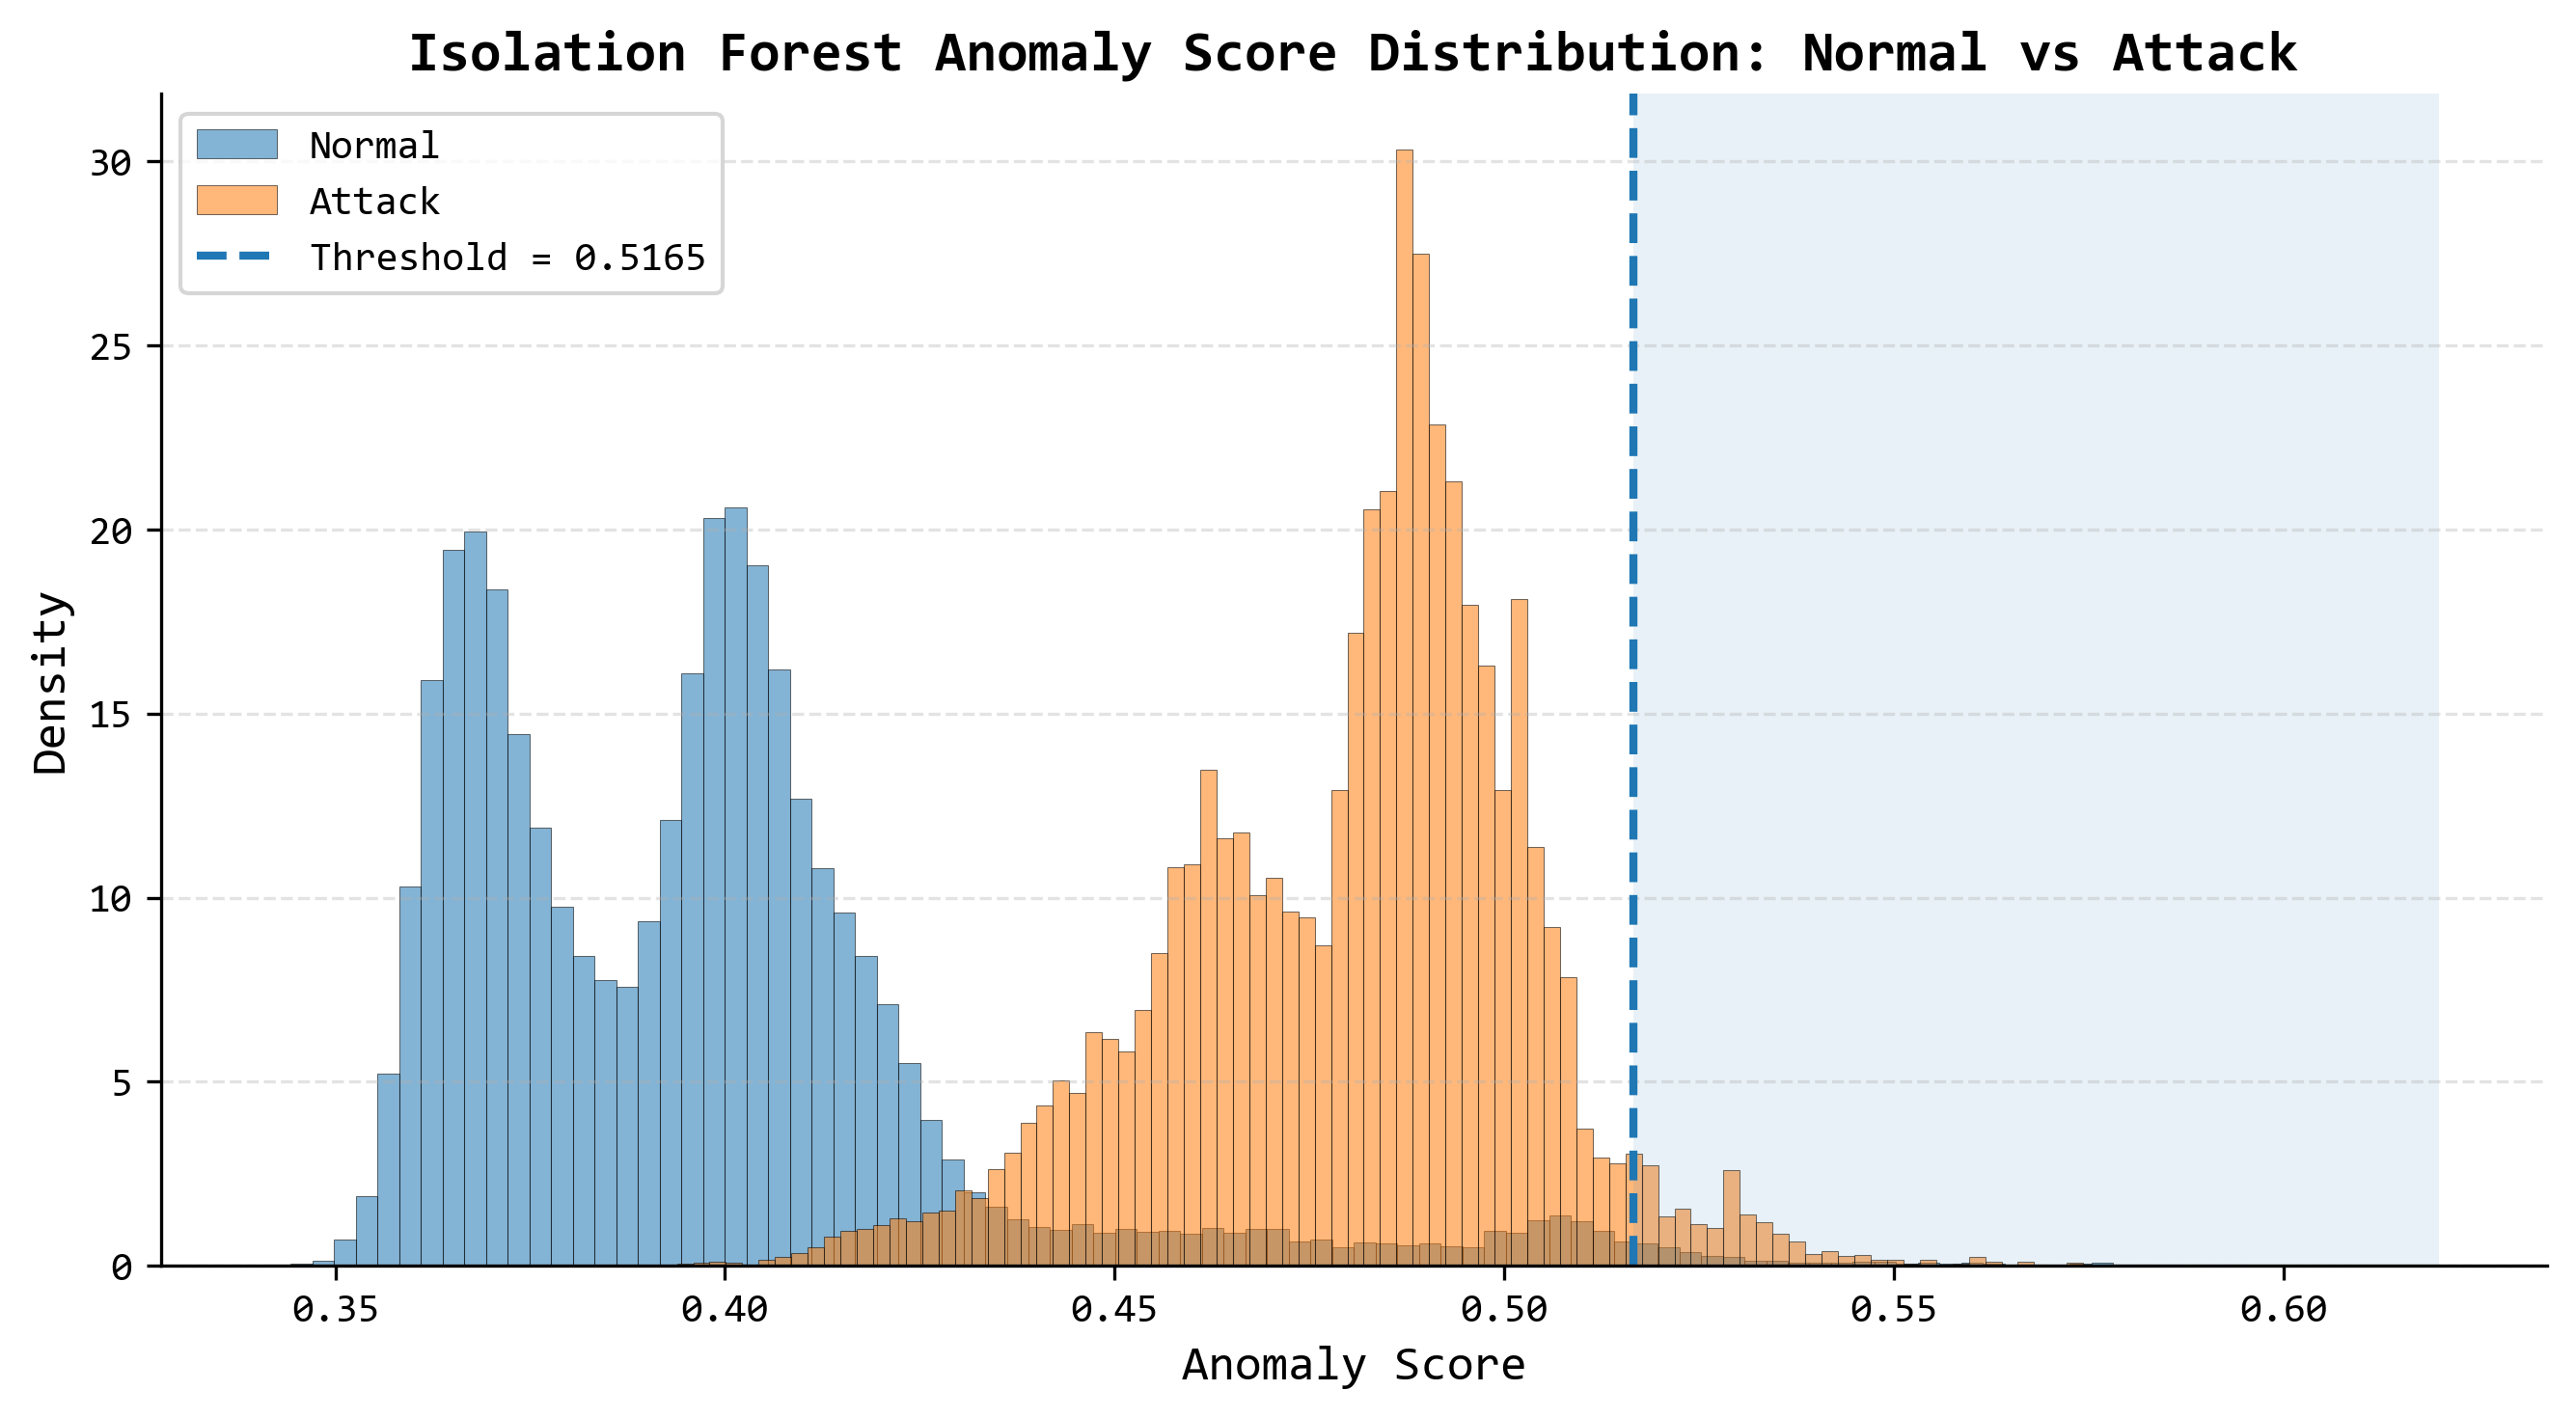

In [115]:
# ===================================
# Distribution des scores
# Normal vs Attaque
# ===================================


plt.rcParams[
    "font.family"
] = "Consolas"


fig, ax = plt.subplots(

    figsize=(
        9,
        5
    ),

    dpi=300

)


# ===================================
# Distribution du trafic normal
# ===================================

ax.hist(

    normal_test_scores,

    bins=100,

    density=True,

    alpha=0.55,

    label="Normal",

    edgecolor="black",

    linewidth=0.25

)


# ===================================
# Distribution des attaques
# ===================================

ax.hist(

    attack_test_scores,

    bins=100,

    density=True,

    alpha=0.55,

    label="Attack",

    edgecolor="black",

    linewidth=0.25

)


# ===================================
# Seuil d'anomalie
# ===================================

ax.axvline(

    anomaly_threshold,

    linestyle="--",

    linewidth=2.0,

    label=(
        f"Threshold = "
        f"{anomaly_threshold:.4f}"
    )

)


# ===================================
# Zone d'anomalie
# ===================================

global_max_score = max(

    normal_test_scores.max(),

    attack_test_scores.max()

)


ax.axvspan(

    anomaly_threshold,

    global_max_score,

    alpha=0.10

)


# ===================================
# Mise en forme
# ===================================

ax.set_title(

    "Isolation Forest Anomaly Score Distribution: Normal vs Attack",

    fontsize=14,

    fontweight="bold",

    fontfamily="Consolas"

)


ax.set_xlabel(

    "Anomaly Score",

    fontsize=12,

    fontfamily="Consolas"

)


ax.set_ylabel(

    "Density",

    fontsize=12,

    fontfamily="Consolas"

)


ax.legend(

    fontsize=10,

    frameon=True

)


ax.grid(

    axis="y",

    linestyle="--",

    alpha=0.35

)


ax.spines[
    "top"
].set_visible(False)


ax.spines[
    "right"
].set_visible(False)


plt.tight_layout()


# ===================================
# Sauvegarde
# ===================================

figure_name = (

    "isolation_forest_score_distribution_normal_attack.png"

)


plt.savefig(

    figure_name,

    dpi=300,

    bbox_inches="tight"

)


plt.show()

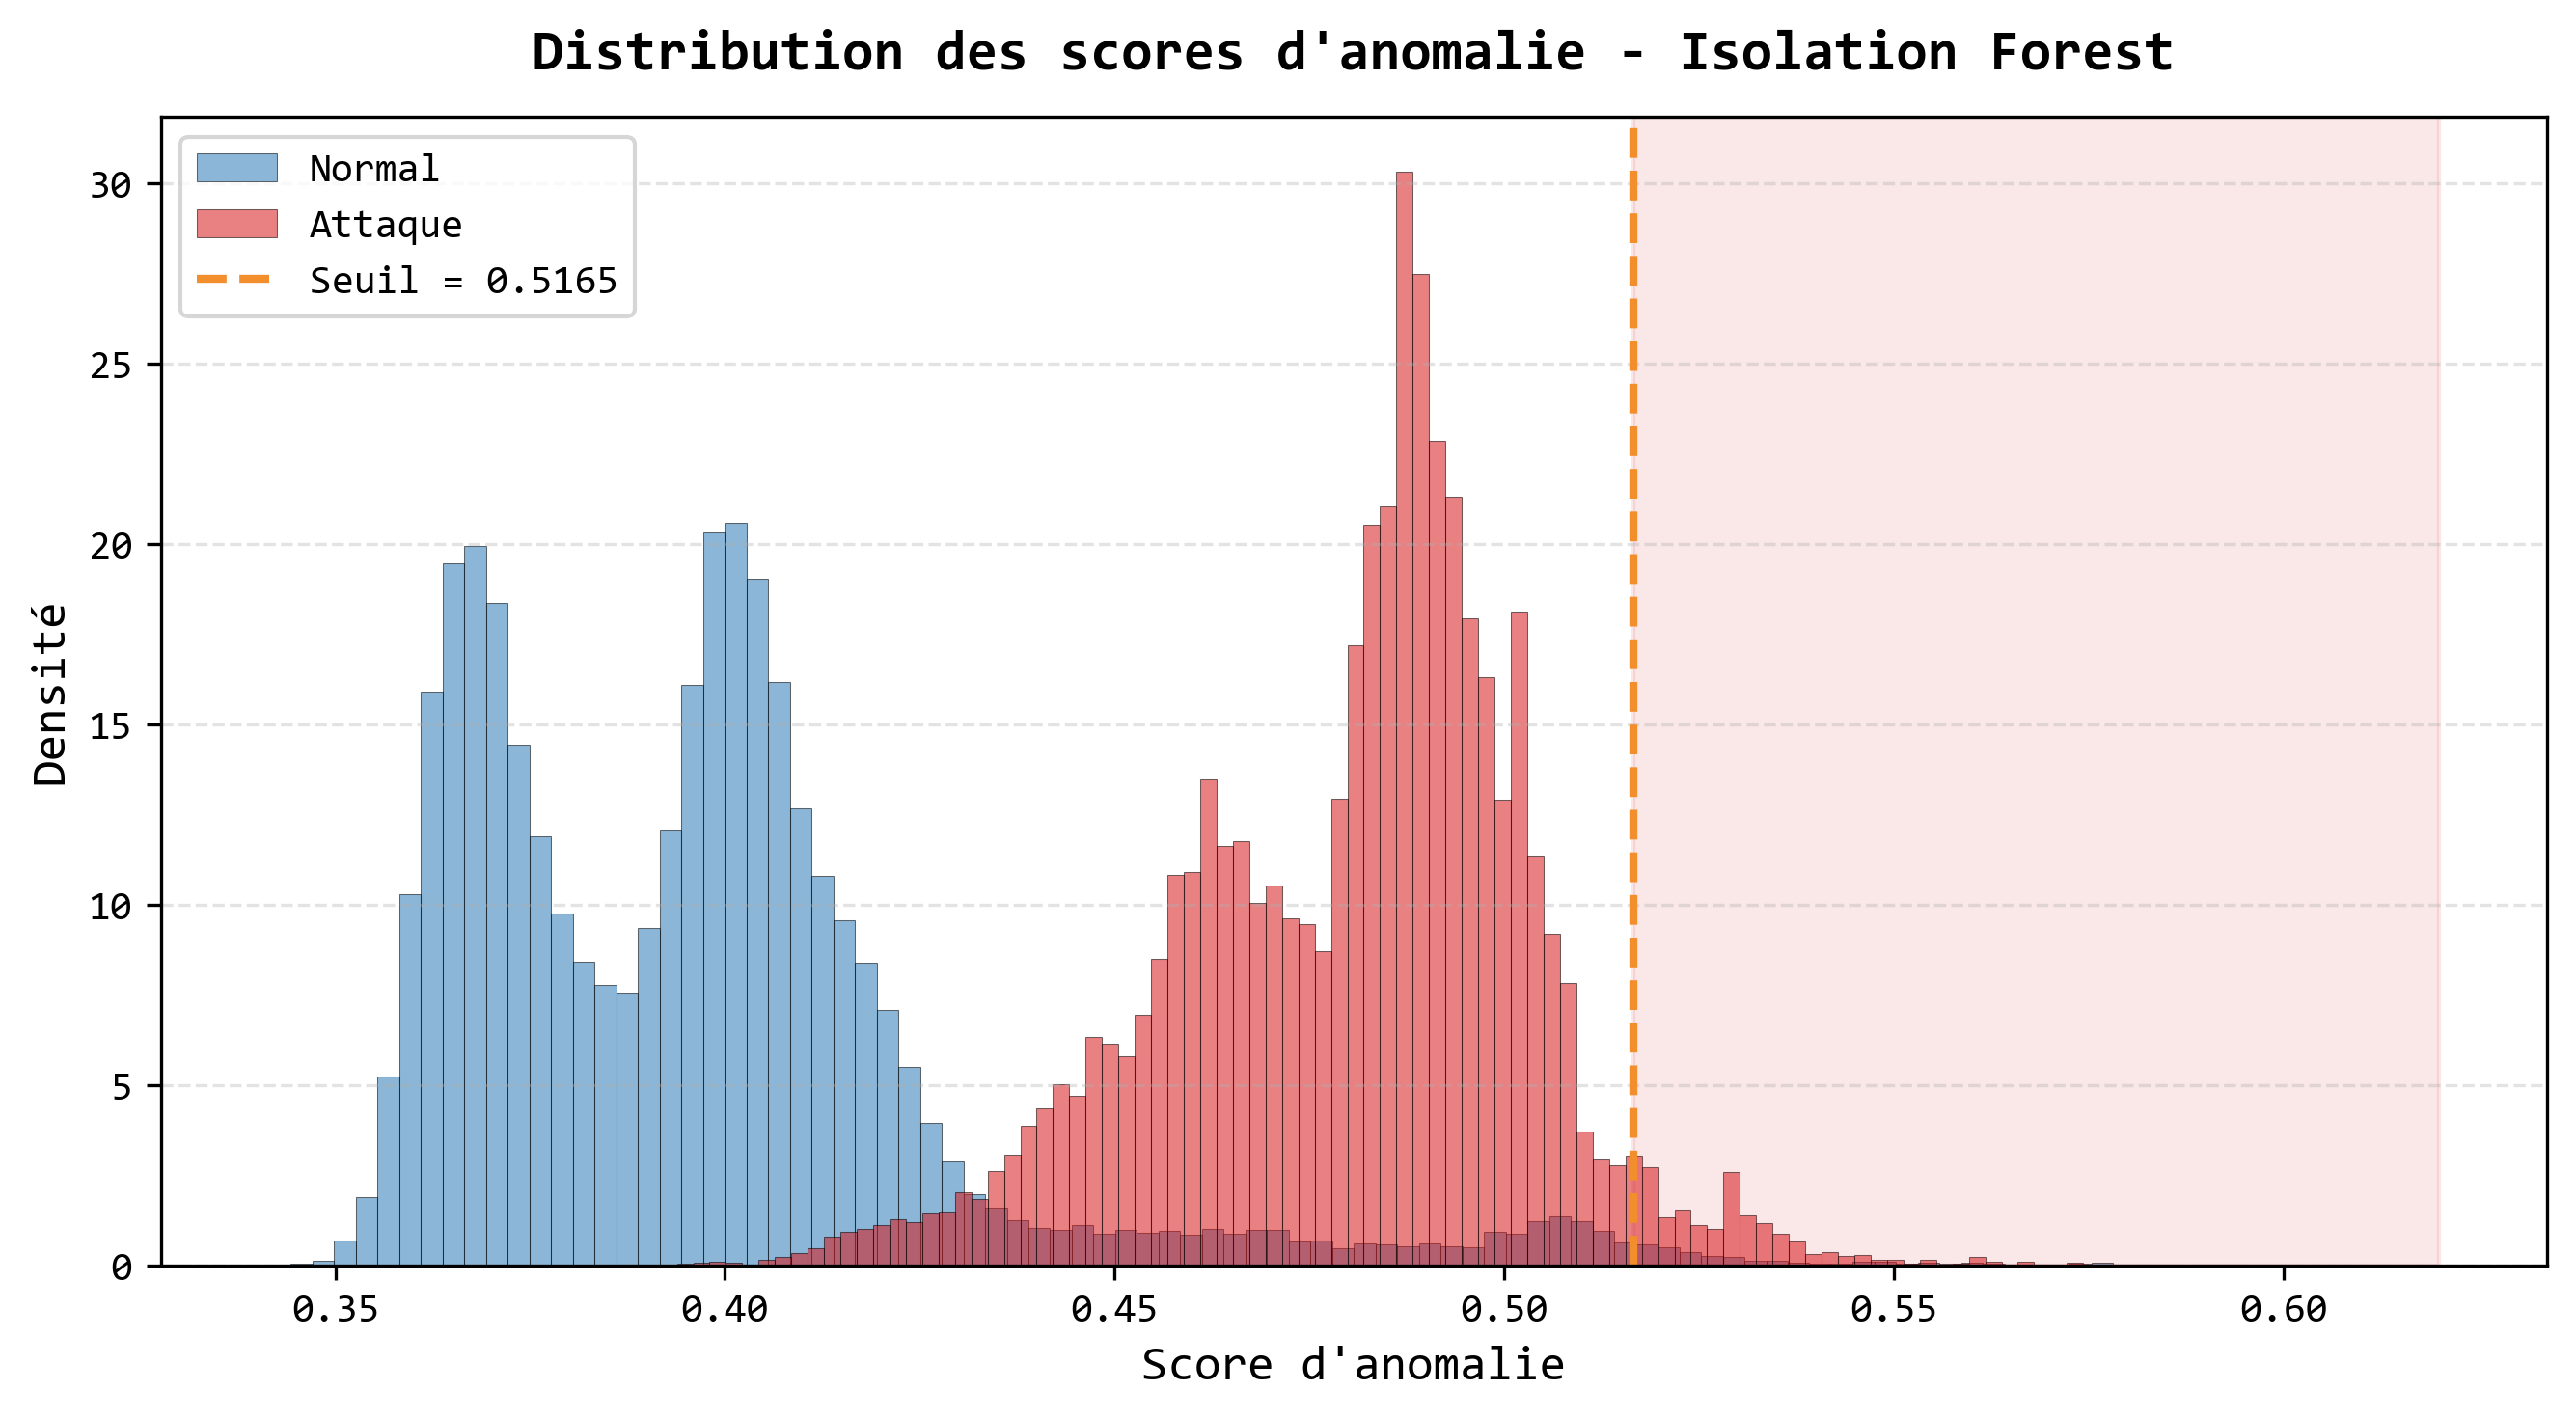

In [116]:
# ==========================================
# Distribution des scores d'anomalie
# Normal vs Attaque
# ==========================================
# Police Consolas
plt.rcParams["font.family"] = "Consolas"


# Création du dossier
os.makedirs(
    "figures/evaluation",
    exist_ok=True
)


# ==========================================
# Création de la figure
# ==========================================

fig, ax = plt.subplots(
    figsize=(9,5),
    dpi=300
)


# ==========================================
# Trafic normal
# ==========================================

ax.hist(
    normal_test_scores,
    bins=100,
    density=True,
    alpha=0.55,
    color="#2C7BB6",
    label="Normal",
    edgecolor="black",
    linewidth=0.25
)


# ==========================================
# Attaques
# ==========================================

ax.hist(
    attack_test_scores,
    bins=100,
    density=True,
    alpha=0.55,
    color="#D7191C",
    label="Attaque",
    edgecolor="black",
    linewidth=0.25
)


# ==========================================
# Seuil d'anomalie
# ==========================================

ax.axvline(
    anomaly_threshold,
    color="#F28E2B",
    linestyle="--",
    linewidth=2,
    label=f"Seuil = {anomaly_threshold:.4f}"
)


# ==========================================
# Zone d'anomalie
# ==========================================

global_max_score = max(
    normal_test_scores.max(),
    attack_test_scores.max()
)


ax.axvspan(
    anomaly_threshold,
    global_max_score,
    alpha=0.10,
    color="#D7191C"
)


# ==========================================
# Mise en forme
# ==========================================

ax.set_title(
    "Distribution des scores d'anomalie - Isolation Forest",
    fontsize=14,
    fontweight="bold",
    fontfamily="Consolas",
    pad=12
)


ax.set_xlabel(
    "Score d'anomalie",
    fontsize=12,
    fontfamily="Consolas"
)


ax.set_ylabel(
    "Densité",
    fontsize=12,
    fontfamily="Consolas"
)


ax.legend(
    fontsize=10
)


ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)


# ==========================================
# Ajustement
# ==========================================

plt.tight_layout()


# ==========================================
# Sauvegarde
# ==========================================

plt.savefig(
    "figures/evaluation/fr_isolation_forest_score_distribution_normal_attack.png",
    format="png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

In [117]:
# ===================================
# Performance par catégorie d'attaque
# Isolation Forest
# ===================================


# ===================================
# Vérification
# ===================================

if "attack_cat" not in df.columns:

    raise ValueError(
        "La colonne 'attack_cat' est absente du dataset."
    )


# ===================================
# Récupération des catégories
# dans l'ordre original
# ===================================

attack_categories_all = (

    df["attack_cat"]

    .reset_index(
        drop=True
    )

    .astype(str)

    .str.strip()

)


# ===================================
# Catégories correspondant
# uniquement aux attaques
# ===================================

attack_categories_only = (

    attack_categories_all[
        y == ATTACK_LABEL
    ]

    .reset_index(
        drop=True
    )

)


# ===================================
# Nettoyage des catégories
# ===================================

attack_categories_only = (

    attack_categories_only

    .replace(
        {
            "": "Unknown",
            "nan": "Unknown",
            "None": "Unknown"
        }
    )

)


# ===================================
# Construction des catégories du test
#
# Avant mélange :
# - X_test_normal
# - X_attack
# ===================================

test_categories_before_shuffle = np.concatenate(

    [

        np.repeat(
            "Normal",
            len(X_test_normal)
        ),

        attack_categories_only.to_numpy()

    ]

)


# ===================================
# Application du même mélange
# utilisé à la Cellule 9
# ===================================

test_attack_categories = (

    test_categories_before_shuffle[
        test_indices
    ]

)


# ===================================
# Vérification de cohérence
# ===================================

if len(test_attack_categories) != len(y_test_if):

    raise ValueError(
        "Les catégories d'attaque ne sont pas alignées avec le jeu de test."
    )


# ===================================
# Création d'un DataFrame
# d'analyse
# ===================================

attack_analysis = pd.DataFrame({

    "True_Label":
        y_test_if,

    "Predicted_Label":
        y_pred_if,

    "Attack_Category":
        test_attack_categories,

    "Anomaly_Score":
        test_anomaly_scores

})


# ===================================
# Conservation des attaques
# uniquement
# ===================================

attack_only_analysis = (

    attack_analysis[

        attack_analysis[
            "True_Label"
        ] == 1

    ]

    .copy()

)


# ===================================
# Fonction de calcul
# par catégorie
# ===================================

attack_category_results = (

    attack_only_analysis

    .groupby(
        "Attack_Category"
    )

    .agg(

        Total_Attacks=(
            "True_Label",
            "size"
        ),

        Detected_Attacks=(
            "Predicted_Label",
            "sum"
        ),

        Mean_Anomaly_Score=(
            "Anomaly_Score",
            "mean"
        ),

        Median_Anomaly_Score=(
            "Anomaly_Score",
            "median"
        )

    )

    .reset_index()

)


# ===================================
# Attaques non détectées
# ===================================

attack_category_results[
    "Missed_Attacks"
] = (

    attack_category_results[
        "Total_Attacks"
    ]

    -
    attack_category_results[
        "Detected_Attacks"
    ]

)


# ===================================
# Taux de détection
# Recall par catégorie
# ===================================

attack_category_results[
    "Detection_Rate"
] = (

    attack_category_results[
        "Detected_Attacks"
    ]

    /
    attack_category_results[
        "Total_Attacks"
    ]

)


attack_category_results[
    "Detection_Rate_Percent"
] = (

    attack_category_results[
        "Detection_Rate"
    ]

    * 100

)


# ===================================
# Tri par taux de détection
# ===================================

attack_category_results = (

    attack_category_results

    .sort_values(

        by="Detection_Rate",

        ascending=False

    )

    .reset_index(
        drop=True
    )

)


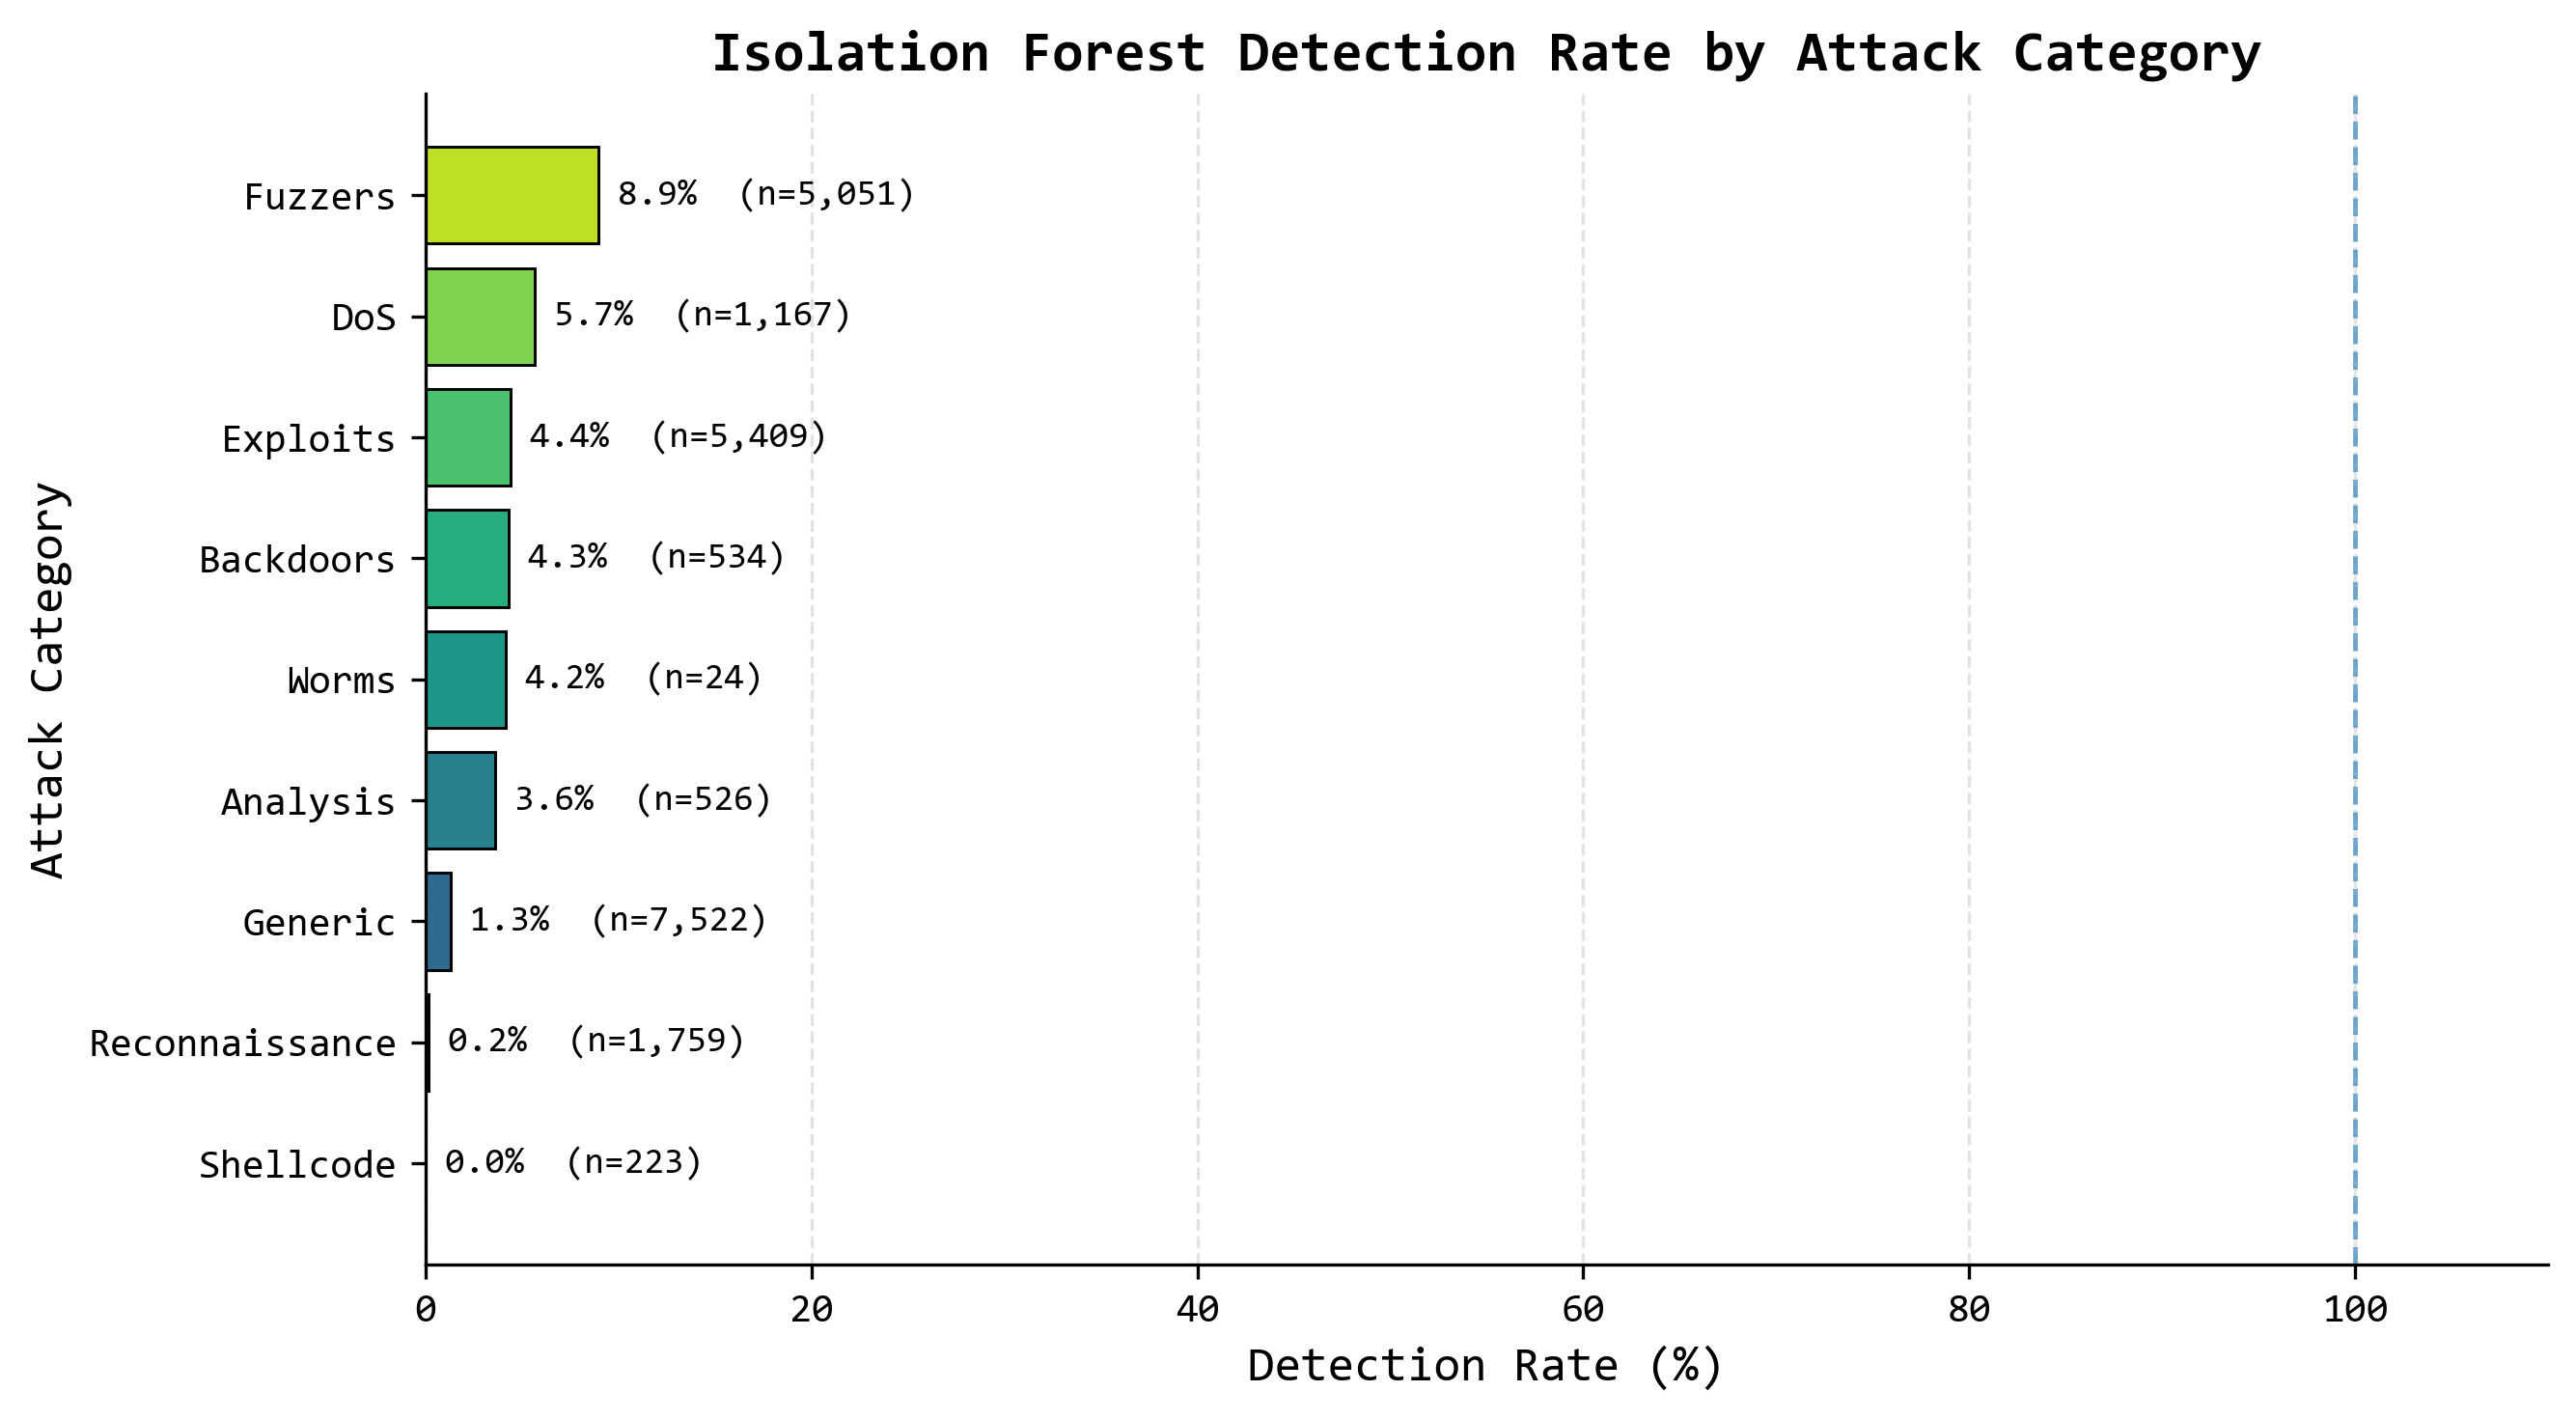

In [119]:
# ===================================
# Figure 19
# Taux de détection
# par catégorie d'attaque
# ===================================


plt.rcParams[
    "font.family"
] = "Consolas"


# ===================================
# Tri pour graphique horizontal
# ===================================

plot_data = (

    attack_category_results

    .sort_values(

        by="Detection_Rate_Percent",

        ascending=True

    )

    .copy()

)


# ===================================
# Figure
# ===================================

fig, ax = plt.subplots(

    figsize=(
        9,
        5
    ),

    dpi=300

)


# ===================================
# Palette scientifique
# ===================================

colors = plt.cm.viridis(

    np.linspace(
        0.15,
        0.90,
        len(plot_data)
    )

)


# ===================================
# Barres
# ===================================

bars = ax.barh(

    plot_data[
        "Attack_Category"
    ],

    plot_data[
        "Detection_Rate_Percent"
    ],

    color=colors,

    edgecolor="black",

    linewidth=0.7

)


# ===================================
# Valeurs au bout des barres
# ===================================

for bar, rate, total in zip(

    bars,

    plot_data[
        "Detection_Rate_Percent"
    ],

    plot_data[
        "Total_Attacks"
    ]

):

    ax.text(

        min(
            rate + 1,
            98
        ),

        bar.get_y()
        +
        bar.get_height() / 2,

        f"{rate:.1f}%  (n={total:,})",

        va="center",

        ha="left",

        fontsize=9,

        fontfamily="Consolas"

    )


# ===================================
# Axe limité à 0 - 100 %
# ===================================

ax.set_xlim(
    0,
    110
)


# ===================================
# Ligne de référence
# 100 %
# ===================================

ax.axvline(

    100,

    linestyle="--",

    linewidth=1.2,

    alpha=0.6

)


# ===================================
# Mise en forme
# ===================================

ax.set_title(

    "Isolation Forest Detection Rate by Attack Category",

    fontsize=14,

    fontweight="bold",

    fontfamily="Consolas"

)


ax.set_xlabel(

    "Detection Rate (%)",

    fontsize=12,

    fontfamily="Consolas"

)


ax.set_ylabel(

    "Attack Category",

    fontsize=12,

    fontfamily="Consolas"

)


ax.grid(

    axis="x",

    linestyle="--",

    alpha=0.35

)


ax.spines[
    "top"
].set_visible(False)


ax.spines[
    "right"
].set_visible(False)


plt.tight_layout()


# ===================================
# Sauvegarde
# ===================================

figure_name = (

    "isolation_forest_detection_rate_by_attack_category.png"

)


plt.savefig(

    figure_name,

    dpi=300,

    bbox_inches="tight"

)


plt.show()

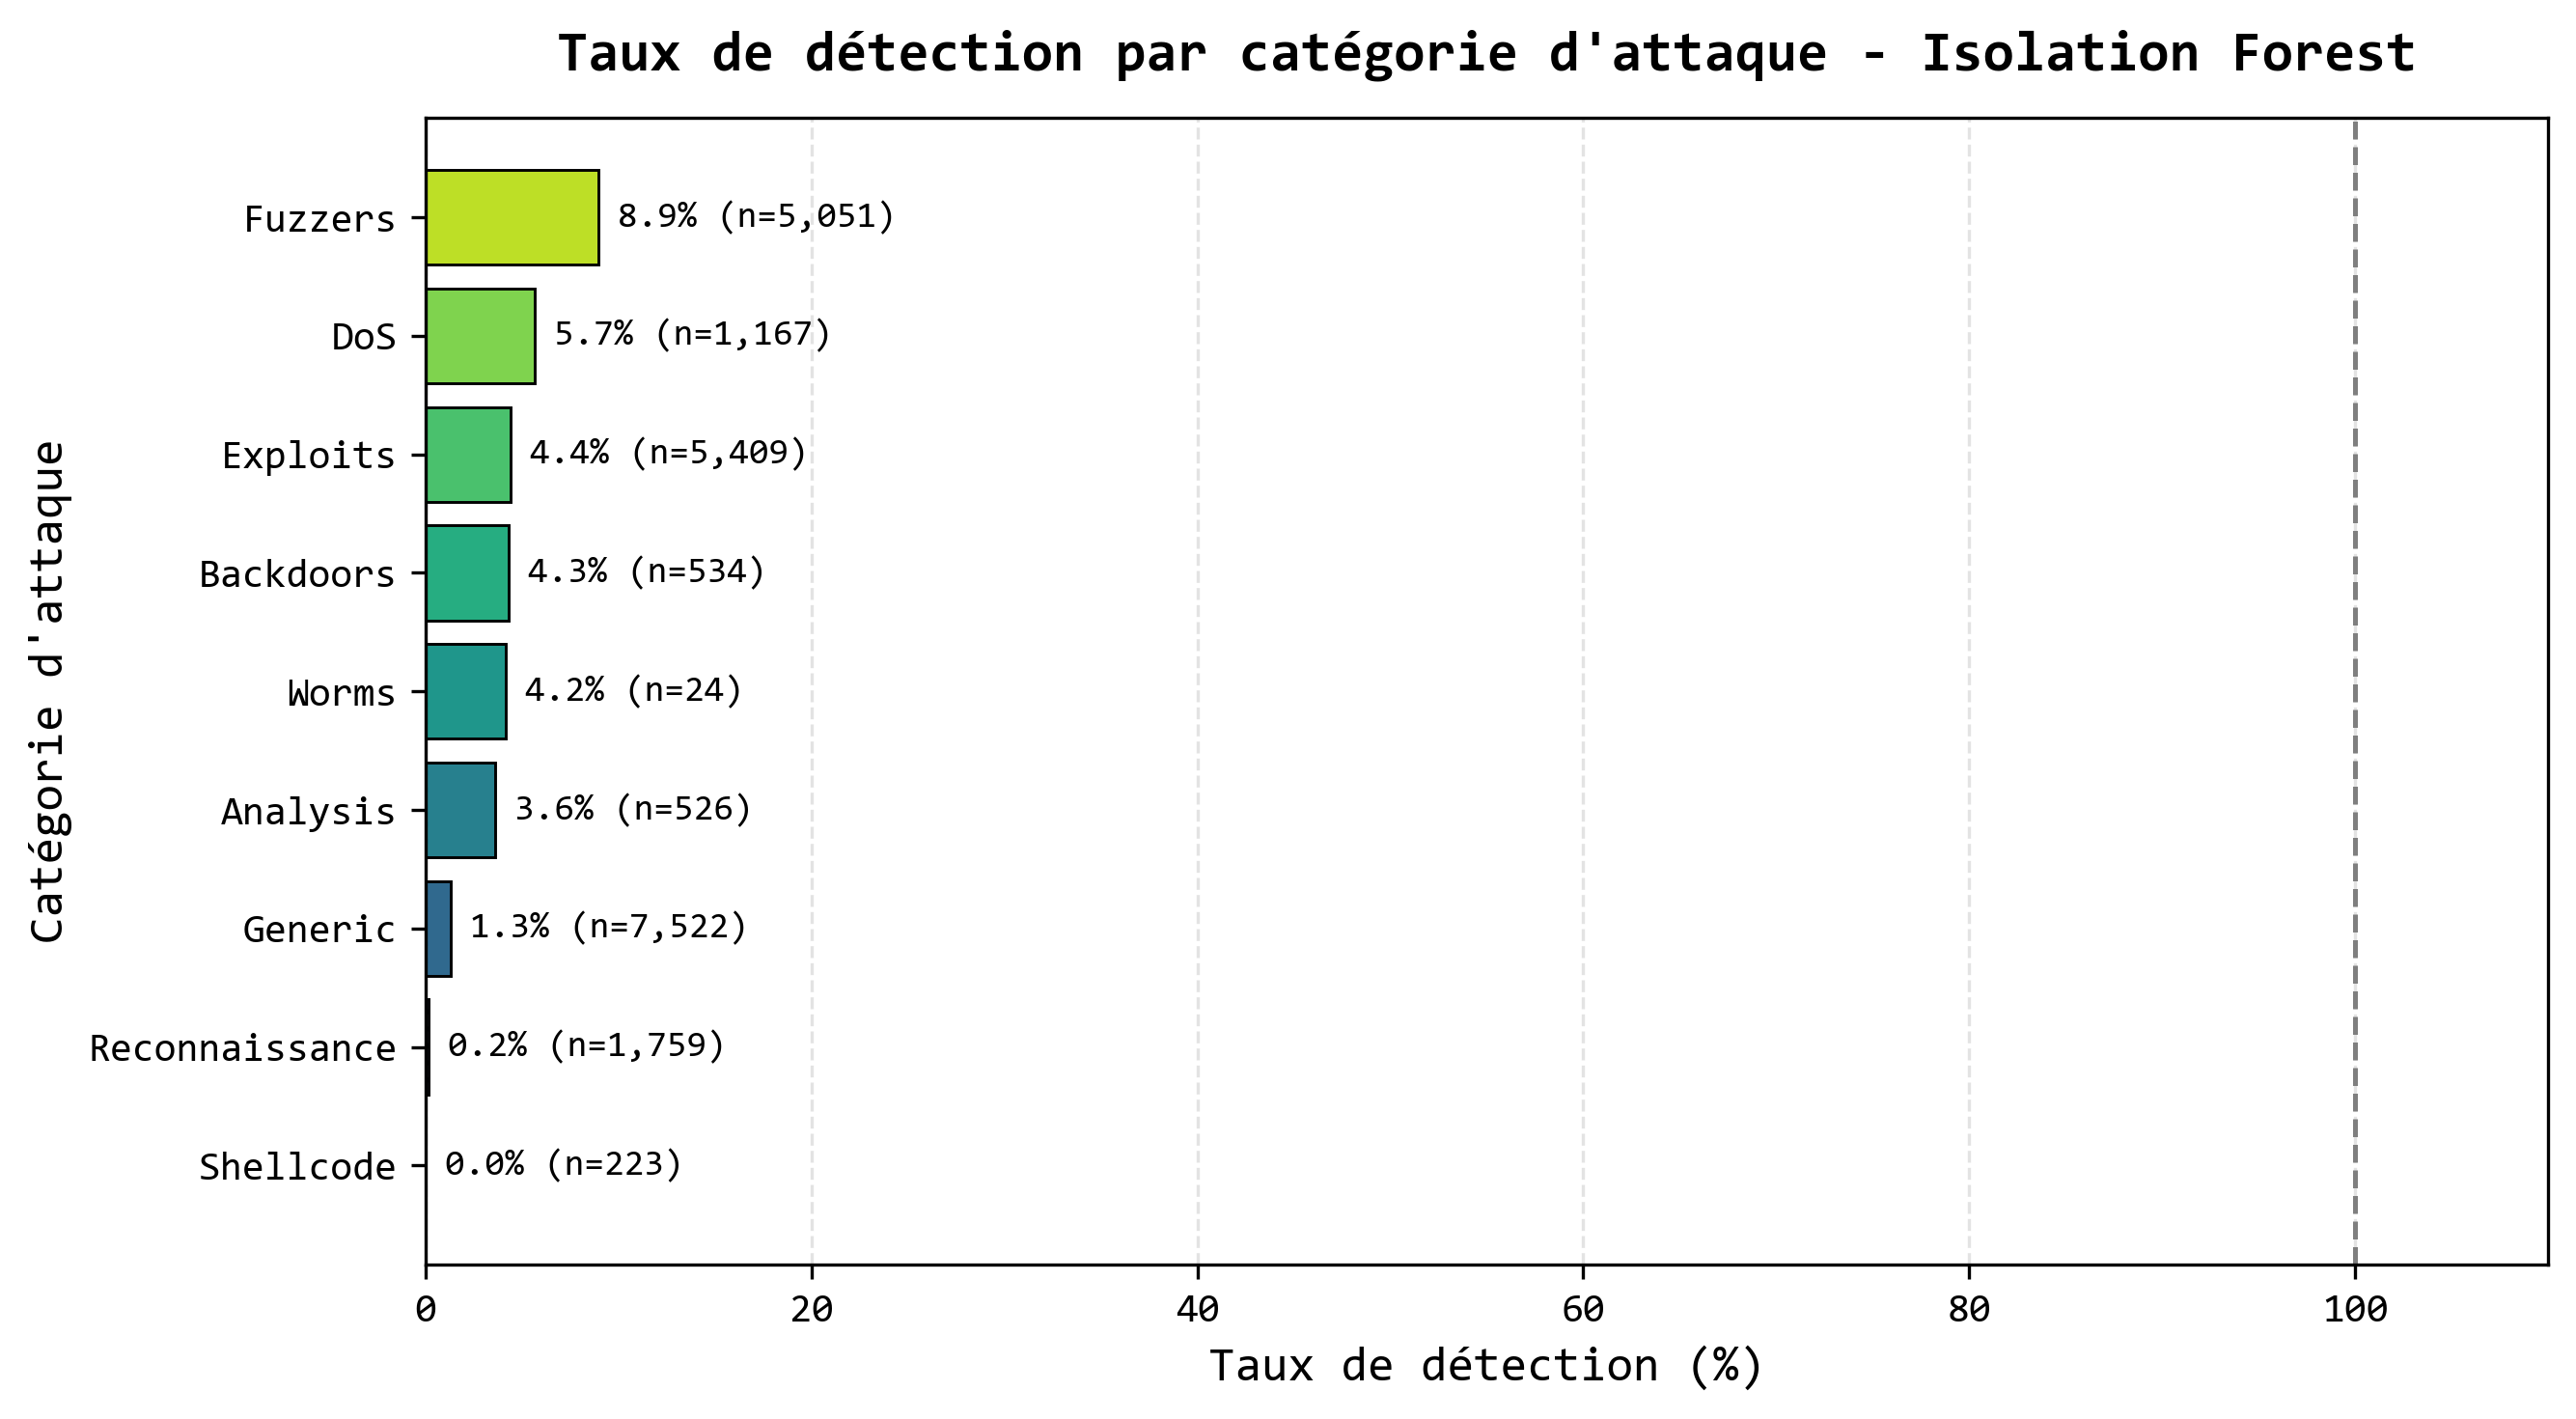

In [120]:
# ==========================================
# Taux de détection par catégorie d'attaque
# ==========================================

# Police Consolas
plt.rcParams["font.family"] = "Consolas"


# Création du dossier
os.makedirs(
    "figures/evaluation",
    exist_ok=True
)


# ==========================================
# Préparation des données
# ==========================================

plot_data = (
    attack_category_results
    .sort_values(
        by="Detection_Rate_Percent",
        ascending=True
    )
)


# ==========================================
# Création de la figure
# ==========================================

fig, ax = plt.subplots(
    figsize=(9,5),
    dpi=300
)


# ==========================================
# Barres
# ==========================================

bars = ax.barh(
    plot_data["Attack_Category"],
    plot_data["Detection_Rate_Percent"],
    color=plt.cm.viridis(
        np.linspace(
            0.15,
            0.90,
            len(plot_data)
        )
    ),
    edgecolor="black",
    linewidth=0.7
)


# ==========================================
# Valeurs
# ==========================================

for bar, rate, total in zip(
    bars,
    plot_data["Detection_Rate_Percent"],
    plot_data["Total_Attacks"]
):

    ax.text(
        rate + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{rate:.1f}% (n={total:,})",
        va="center",
        fontsize=9,
        fontfamily="Consolas"
    )


# ==========================================
# Mise en forme
# ==========================================

ax.set_xlim(
    0,
    110
)


ax.set_title(
    "Taux de détection par catégorie d'attaque - Isolation Forest",
    fontsize=14,
    fontweight="bold",
    fontfamily="Consolas",
    pad=12
)


ax.set_xlabel(
    "Taux de détection (%)",
    fontsize=12,
    fontfamily="Consolas"
)


ax.set_ylabel(
    "Catégorie d'attaque",
    fontsize=12,
    fontfamily="Consolas"
)


ax.axvline(
    100,
    linestyle="--",
    linewidth=1.2,
    color="#7F7F7F"
)


ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.35
)


# ==========================================
# Ajustement
# ==========================================

plt.tight_layout()


# ==========================================
# Sauvegarde
# ==========================================

plt.savefig(
    "figures/evaluation/fr_isolation_forest_detection_rate_by_attack_category.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

In [122]:
# ===================================
# Synthèse des performances
# Isolation Forest
# ===================================


# ===================================
# Métriques principales
# ===================================

performance_metrics = pd.DataFrame({

    "Metric": [

        "Accuracy",

        "Precision",

        "Recall",

        "F1-score",

        "Specificity",

        "ROC-AUC",

        "Average Precision"

    ],

    "Score": [

        accuracy,

        precision,

        recall,

        f1,

        specificity,

        roc_auc,

        average_precision

    ]

})


# ===================================
# Conversion en pourcentage
# pour l'affichage
# ===================================

performance_metrics[
    "Score (%)"
] = (

    performance_metrics[
        "Score"
    ]

    * 100

)


# ===================================
# Affichage du tableau
# ===================================


display(

    performance_metrics

    .style

    .format(
        {
            "Score":
                "{:.4f}",

            "Score (%)":
                "{:.2f} %"
        }
    )

)

,Metric,Score,Score (%)
0,Accuracy,0.8198,81.98 %
1,Precision,0.4719,47.19 %
2,Recall,0.0404,4.04 %
3,F1-score,0.0744,7.44 %
4,Specificity,0.9901,99.01 %
5,ROC-AUC,0.9574,95.74 %
6,Average Precision,0.6804,68.04 %


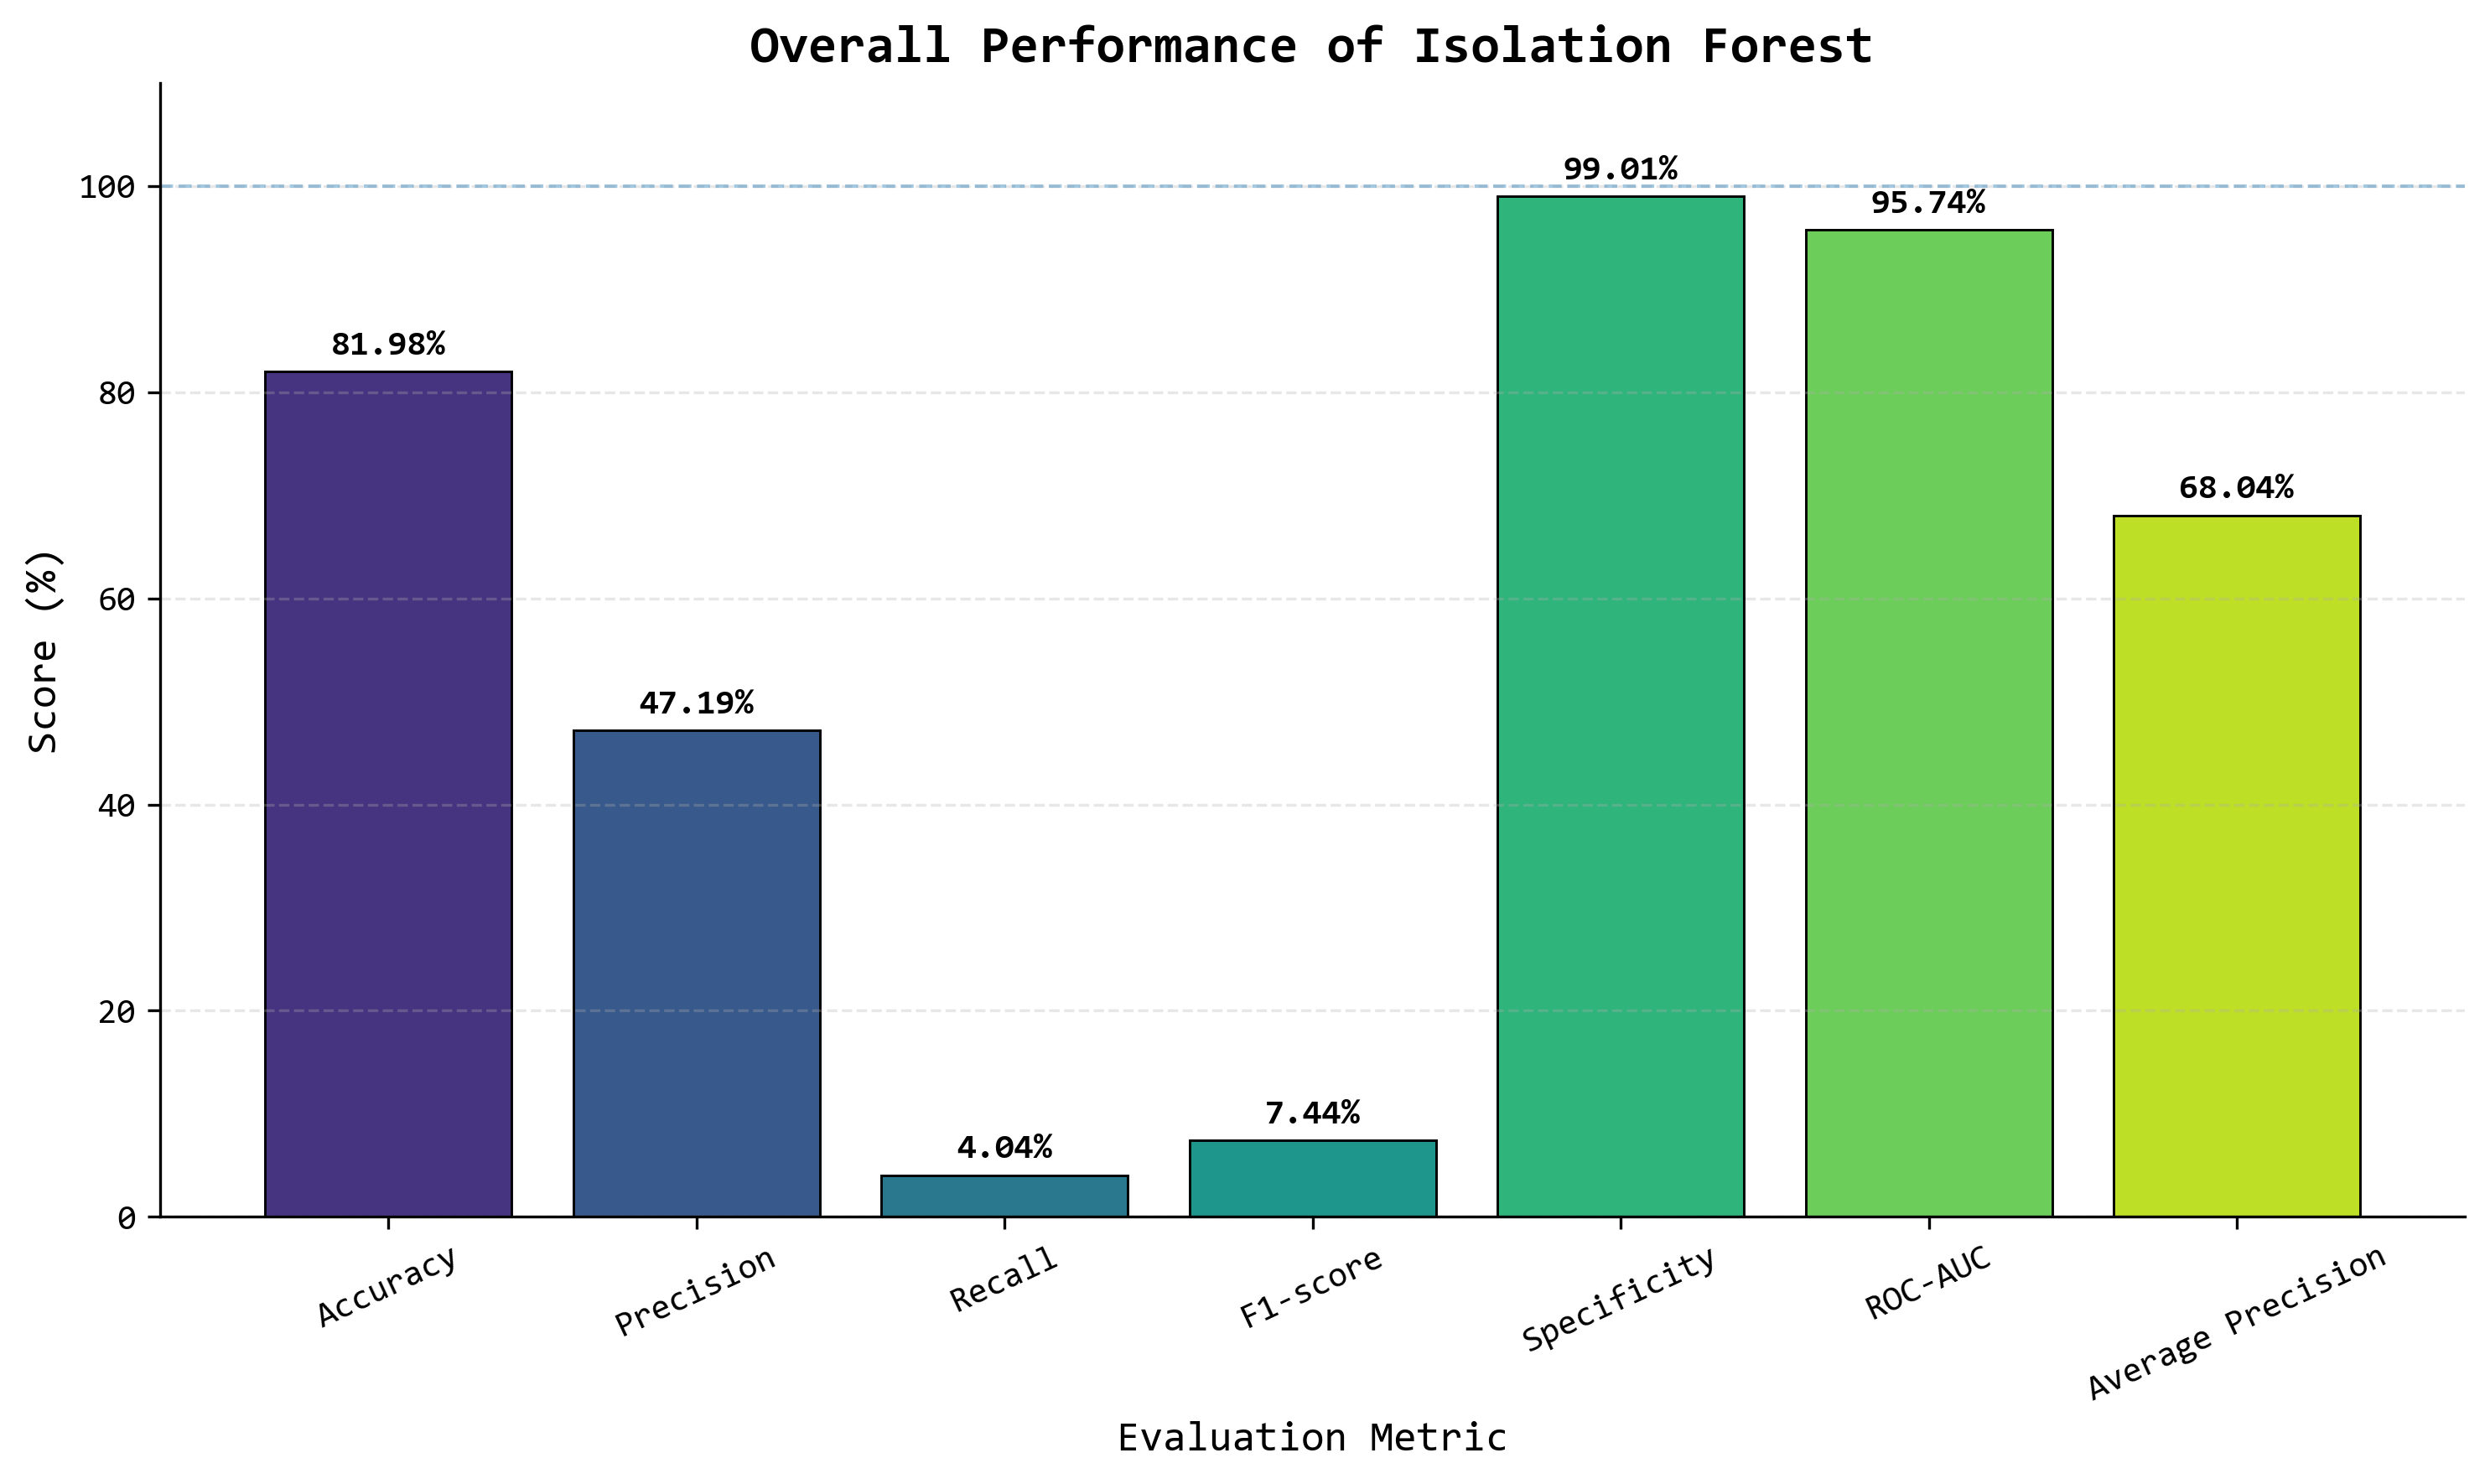

In [124]:
# ===================================
# Métriques globales
# Isolation Forest
# ===================================


plt.rcParams[
    "font.family"
] = "Consolas"


fig, ax = plt.subplots(

    figsize=(
        10,
        6
    ),

    dpi=300

)


# ===================================
# Palette scientifique
# ===================================

colors = plt.cm.viridis(

    np.linspace(
        0.15,
        0.90,
        len(performance_metrics)
    )

)


# ===================================
# Graphique
# ===================================

bars = ax.bar(

    performance_metrics[
        "Metric"
    ],

    performance_metrics[
        "Score (%)"
    ],

    color=colors,

    edgecolor="black",

    linewidth=0.7

)


# ===================================
# Valeurs sur les barres
# ===================================

for bar, value in zip(

    bars,

    performance_metrics[
        "Score (%)"
    ]

):

    ax.text(

        bar.get_x()
        +
        bar.get_width() / 2,

        bar.get_height()
        +
        1,

        f"{value:.2f}%",

        ha="center",

        va="bottom",

        fontsize=10,

        fontfamily="Consolas",

        fontweight="bold"

    )


# ===================================
# Axe Y
# ===================================

ax.set_ylim(
    0,
    110
)


# ===================================
# Ligne de référence à 100 %
# ===================================

ax.axhline(

    100,

    linestyle="--",

    linewidth=1,

    alpha=0.4

)


# ===================================
# Mise en forme
# ===================================

ax.set_title(

    "Overall Performance of Isolation Forest",

    fontsize=15,

    fontweight="bold",

    fontfamily="Consolas"

)


ax.set_xlabel(

    "Evaluation Metric",

    fontsize=12,

    fontfamily="Consolas"

)


ax.set_ylabel(

    "Score (%)",

    fontsize=12,

    fontfamily="Consolas"

)


ax.tick_params(

    axis="x",

    rotation=25

)


ax.grid(

    axis="y",

    linestyle="--",

    alpha=0.30

)


ax.spines[
    "top"
].set_visible(False)


ax.spines[
    "right"
].set_visible(False)


plt.tight_layout()


# ===================================
# Sauvegarde
# ===================================

figure_name = (

    "isolation_forest_overall_performance.png"

)


plt.savefig(

    figure_name,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


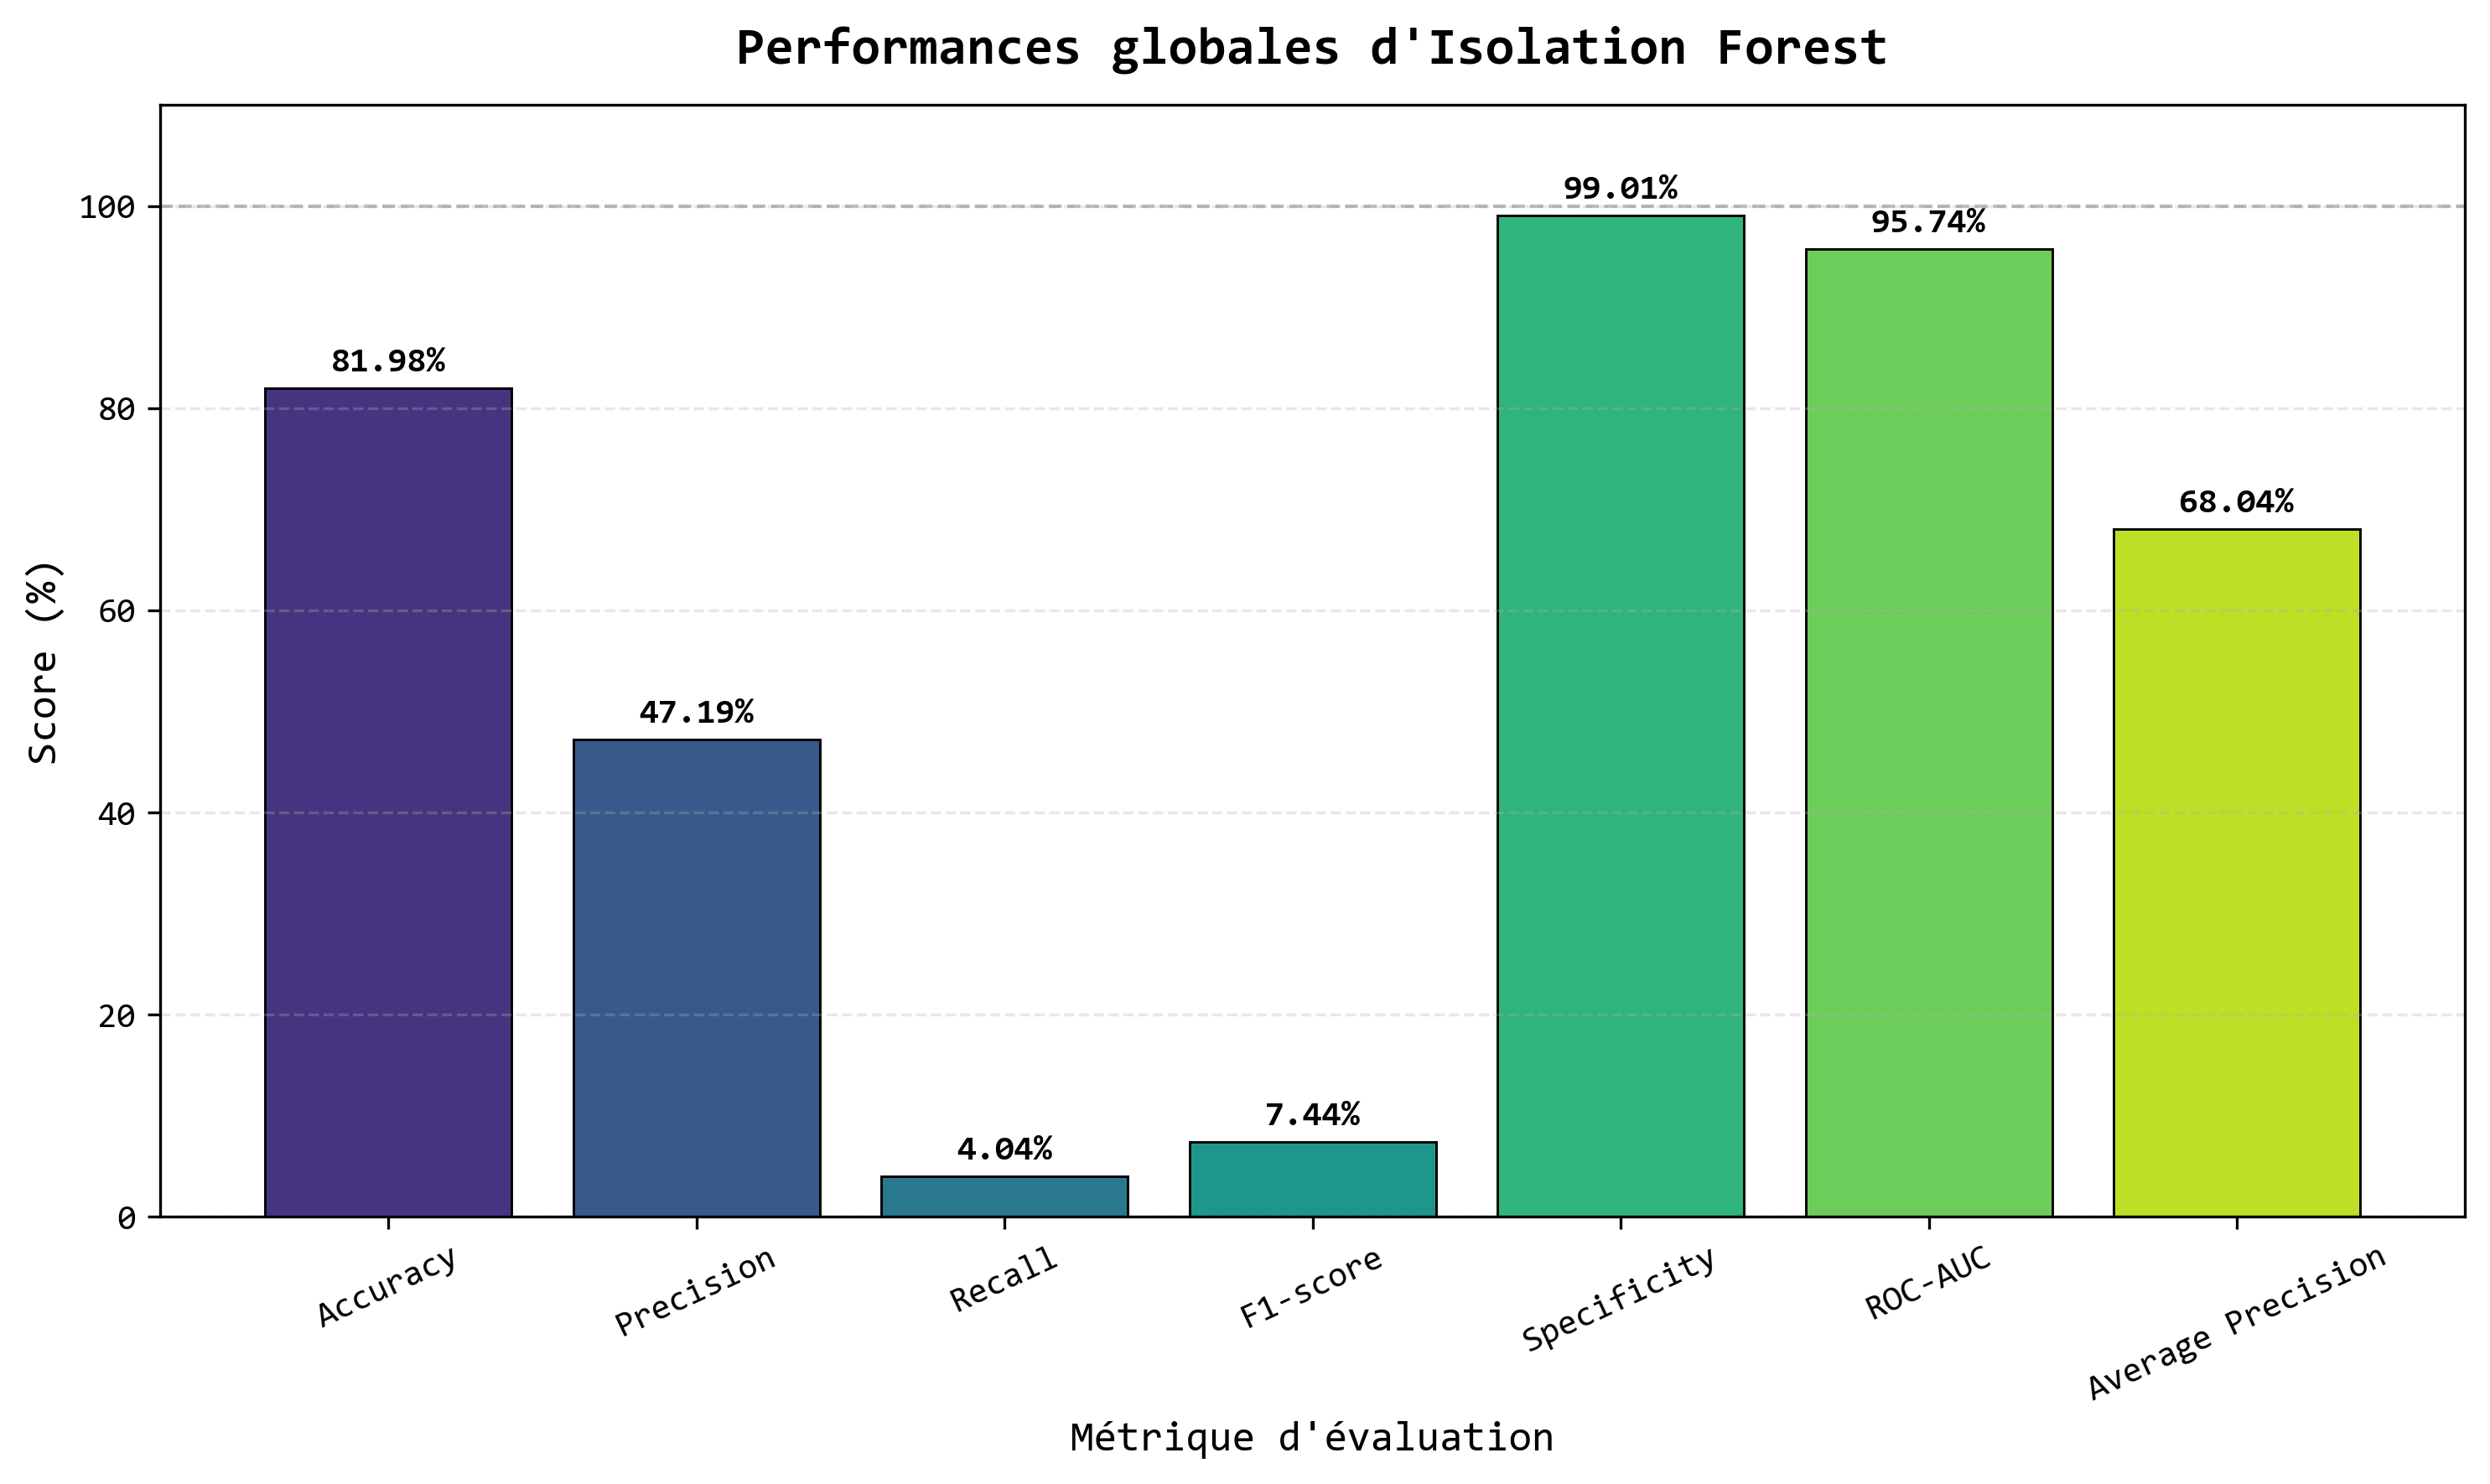

In [125]:
# ==========================================
# Métriques globales - Isolation Forest
# ==========================================

# Police Consolas
plt.rcParams["font.family"] = "Consolas"


# Création du dossier
os.makedirs(
    "figures/evaluation",
    exist_ok=True
)


# ==========================================
# Création de la figure
# ==========================================

fig, ax = plt.subplots(
    figsize=(10, 6),
    dpi=300
)


# ==========================================
# Graphique
# ==========================================

bars = ax.bar(
    performance_metrics["Metric"],
    performance_metrics["Score (%)"],
    color=plt.cm.viridis(
        np.linspace(
            0.15,
            0.90,
            len(performance_metrics)
        )
    ),
    edgecolor="black",
    linewidth=0.7
)


# ==========================================
# Valeurs sur les barres
# ==========================================

for bar, value in zip(
    bars,
    performance_metrics["Score (%)"]
):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=10,
        fontfamily="Consolas",
        fontweight="bold"
    )


# ==========================================
# Mise en forme
# ==========================================

ax.set_ylim(
    0,
    110
)

ax.axhline(
    100,
    linestyle="--",
    linewidth=1,
    color="#7F7F7F",
    alpha=0.5
)

ax.set_title(
    "Performances globales d'Isolation Forest",
    fontsize=15,
    fontweight="bold",
    fontfamily="Consolas",
    pad=12
)

ax.set_xlabel(
    "Métrique d'évaluation",
    fontsize=12,
    fontfamily="Consolas"
)

ax.set_ylabel(
    "Score (%)",
    fontsize=12,
    fontfamily="Consolas"
)

ax.tick_params(
    axis="x",
    rotation=25
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.30
)


# ==========================================
# Ajustement
# ==========================================

plt.tight_layout()


# ==========================================
# Sauvegarde
# ==========================================

plt.savefig(
    "figures/evaluation/fr_isolation_forest_overall_performance.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

In [127]:
# ===================================
# Sauvegarde du modèle
# et des résultats
# ===================================
# ===================================
# Nom du fichier principal
# ===================================

model_filename = (

    "isolation_forest_unsw_nb15.joblib"

)


# ===================================
# Regroupement de tous les éléments
# nécessaires à la réutilisation
# ===================================

isolation_forest_package = {

    # -----------------------------------
    # Modèle
    # -----------------------------------

    "model":
        isolation_forest,


    # -----------------------------------
    # Seuil final
    # -----------------------------------

    "anomaly_threshold":
        float(
            anomaly_threshold
        ),


    # -----------------------------------
    # Convention des classes
    # -----------------------------------

    "normal_label":
        int(
            NORMAL_LABEL
        ),

    "attack_label":
        int(
            ATTACK_LABEL
        ),


    # -----------------------------------
    # Variables finales
    # -----------------------------------

    "feature_names":
        feature_names,


    # -----------------------------------
    # Encodage
    # -----------------------------------

    "frequency_mappings":
        frequency_mappings,

    "high_cardinality_features":
        high_cardinality_features,

    "low_cardinality_features":
        low_cardinality_features,


    # -----------------------------------
    # Seuil de cardinalité
    # -----------------------------------

    "high_cardinality_threshold":
        HIGH_CARDINALITY_THRESHOLD,


    # -----------------------------------
    # Variables constantes supprimées
    # -----------------------------------

    "constant_features":
        constant_features,


    # -----------------------------------
    # Paramètres Isolation Forest
    # -----------------------------------

    "model_parameters": {

        "n_estimators":
            N_ESTIMATORS,

        "max_samples":
            MAX_SAMPLES,

        "contamination":
            CONTAMINATION,

        "max_features":
            1.0,

        "bootstrap":
            False,

        "random_state":
            RANDOM_STATE

    },


    # -----------------------------------
    # Paramètres du seuil
    # -----------------------------------

    "threshold_parameters": {

        "target_fpr":
            TARGET_FPR,

        "quantile":
            threshold_quantile

    },


    # -----------------------------------
    # Métriques finales
    # -----------------------------------

    "metrics": {

        "accuracy":
            float(
                accuracy
            ),

        "precision":
            float(
                precision
            ),

        "recall":
            float(
                recall
            ),

        "f1_score":
            float(
                f1
            ),

        "specificity":
            float(
                specificity
            ),

        "roc_auc":
            float(
                roc_auc
            ),

        "average_precision":
            float(
                average_precision
            ),

        "false_positive_rate":
            float(
                false_positive_rate
            ),

        "false_negative_rate":
            float(
                false_negative_rate
            )

    },


    # -----------------------------------
    # Matrice de confusion
    # -----------------------------------

    "confusion_matrix": {

        "TN":
            int(
                tn
            ),

        "FP":
            int(
                fp
            ),

        "FN":
            int(
                fn
            ),

        "TP":
            int(
                tp
            )

    }

}


# ===================================
# Sauvegarde du package
# ===================================

joblib.dump(

    isolation_forest_package,

    model_filename

)


print(
    "\n✓ Modèle sauvegardé :"
)


print(
    model_filename
)


# ===================================
# Sauvegarde des métriques
# au format CSV
# ===================================

metrics_filename = (

    "isolation_forest_metrics.csv"

)


performance_metrics.to_csv(

    metrics_filename,

    index=False

)


print(
    "\n✓ Métriques sauvegardées :"
)


print(
    metrics_filename
)


# ===================================
# Sauvegarde de la matrice
# de confusion
# ===================================

confusion_matrix_table = pd.DataFrame(

    cm,

    index=[
        "True_Normal",
        "True_Attack"
    ],

    columns=[
        "Predicted_Normal",
        "Predicted_Attack"
    ]

)


confusion_filename = (

    "isolation_forest_confusion_matrix.csv"

)


confusion_matrix_table.to_csv(

    confusion_filename

)


print(
    "\n✓ Matrice de confusion sauvegardée :"
)


print(
    confusion_filename
)


# ===================================
# Sauvegarde des résultats
# par catégorie d'attaque
# ===================================

attack_results_filename = (

    "isolation_forest_attack_category_results.csv"

)


if "attack_category_results" in globals():

    attack_category_results.to_csv(

        attack_results_filename,

        index=False

    )


    print(
        "\n✓ Résultats par catégorie sauvegardés :"
    )


    print(
        attack_results_filename
    )


# ===================================
# Sauvegarde des scores du test
# ===================================

test_results = pd.DataFrame({

    "True_Label":
        y_test_if,

    "Predicted_Label":
        y_pred_if,

    "Anomaly_Score":
        test_anomaly_scores

})


# ===================================
# Ajout des catégories
# si disponibles
# ===================================

if "test_attack_categories" in globals():

    test_results[
        "Attack_Category"
    ] = test_attack_categories


# ===================================
# Indication de bonne/mauvaise
# classification
# ===================================

test_results[
    "Correct_Prediction"
] = (

    test_results[
        "True_Label"
    ]

    ==
    test_results[
        "Predicted_Label"
    ]

)


# ===================================
# Distance au seuil
# ===================================

test_results[
    "Distance_to_Threshold"
] = (

    test_results[
        "Anomaly_Score"
    ]

    -
    anomaly_threshold

)


test_results_filename = (

    "isolation_forest_test_predictions.csv"

)


test_results.to_csv(

    test_results_filename,

    index=False

)


print(
    "\n✓ Prédictions du test sauvegardées :"
)


print(
    test_results_filename
)


# ===================================
# Vérification du fichier modèle
# ===================================

loaded_package = joblib.load(

    model_filename

)


loaded_model = (

    loaded_package[
        "model"
    ]

)


loaded_threshold = (

    loaded_package[
        "anomaly_threshold"
    ]

)



# ===================================
# Vérification d'une prédiction
# ===================================

verification_scores = (

    -loaded_model.score_samples(

        X_test_if[:10]

    )

)


verification_predictions = (

    verification_scores

    >
    loaded_threshold

).astype(
    np.int8
)


# ===================================
# Vérification finale
# ===================================

if np.array_equal(

    verification_predictions,

    y_pred_if[:10]

):

    print(
        "\n✓ Le modèle sauvegardé reproduit correctement les prédictions."
    )

else:

    print(
        "\nATTENTION : différence détectée lors de la vérification."
    )



print(
    "\n✓ Sauvegarde complète terminée."
)


✓ Modèle sauvegardé :
isolation_forest_unsw_nb15.joblib

✓ Métriques sauvegardées :
isolation_forest_metrics.csv

✓ Matrice de confusion sauvegardée :
isolation_forest_confusion_matrix.csv

✓ Résultats par catégorie sauvegardés :
isolation_forest_attack_category_results.csv

✓ Prédictions du test sauvegardées :
isolation_forest_test_predictions.csv

✓ Le modèle sauvegardé reproduit correctement les prédictions.

✓ Sauvegarde complète terminée.


In [128]:
# ===================================
# Cellule 22
# Synthèse finale des résultats
# Isolation Forest
# ===================================


print(
    "=" * 70
)

print(
    "SYNTHÈSE FINALE - ISOLATION FOREST"
)

print(
    "=" * 70
)


# ===================================
# Tableau final des performances
# ===================================

final_results = pd.DataFrame({

    "Modèle": [
        "Isolation Forest"
    ],

    "Accuracy": [
        accuracy
    ],

    "Precision": [
        precision
    ],

    "Recall": [
        recall
    ],

    "F1-score": [
        f1
    ],

    "Specificity": [
        specificity
    ],

    "ROC-AUC": [
        roc_auc
    ],

    "Average Precision": [
        average_precision
    ],

    "FPR": [
        false_positive_rate
    ],

    "FNR": [
        false_negative_rate
    ],

    "Seuil": [
        anomaly_threshold
    ]

})


# ===================================
# Affichage du tableau
# ===================================

print(
    "\nTableau final des performances :"
)


display(

    final_results

    .style

    .format({

        "Accuracy":
            "{:.4f}",

        "Precision":
            "{:.4f}",

        "Recall":
            "{:.4f}",

        "F1-score":
            "{:.4f}",

        "Specificity":
            "{:.4f}",

        "ROC-AUC":
            "{:.4f}",

        "Average Precision":
            "{:.4f}",

        "FPR":
            "{:.4f}",

        "FNR":
            "{:.4f}",

        "Seuil":
            "{:.6f}"

    })

)

SYNTHÈSE FINALE - ISOLATION FOREST

Tableau final des performances :


,Modèle,Accuracy,Precision,Recall,F1-score,Specificity,ROC-AUC,Average Precision,FPR,FNR,Seuil
0,Isolation Forest,0.8198,0.4719,0.0404,0.0744,0.9901,0.9574,0.6804,0.0099,0.9596,0.516526


In [129]:
# ===================================
# Interprétation automatique
# ===================================


print(
    "\n" + "=" * 70
)

print(
    "INTERPRÉTATION DES RÉSULTATS"
)

print(
    "=" * 70
)


print(
    f"\nIsolation Forest atteint une accuracy de "
    f"{accuracy * 100:.2f} %."
)


print(
    f"Le modèle obtient une précision de "
    f"{precision * 100:.2f} %, ce qui indique la proportion "
    f"d'alertes prédites comme attaques qui correspondent "
    f"réellement à des attaques."
)


print(
    f"\nLe rappel atteint "
    f"{recall * 100:.2f} %, ce qui signifie que le modèle "
    f"détecte environ {recall * 100:.2f} % des attaques "
    f"présentes dans le jeu de test."
)


print(
    f"\nLe F1-score est de "
    f"{f1:.4f}, représentant le compromis entre "
    f"précision et rappel."
)


print(
    f"\nLa spécificité est de "
    f"{specificity * 100:.2f} %, indiquant la capacité du "
    f"modèle à reconnaître correctement le trafic normal."
)


print(
    f"\nLe taux de faux positifs est de "
    f"{false_positive_rate * 100:.2f} %."
)


print(
    f"Le taux de faux négatifs est de "
    f"{false_negative_rate * 100:.2f} %."
)


print(
    f"\nLe ROC-AUC atteint "
    f"{roc_auc:.4f}."
)


print(
    f"L'Average Precision atteint "
    f"{average_precision:.4f}."
)


INTERPRÉTATION DES RÉSULTATS

Isolation Forest atteint une accuracy de 81.98 %.
Le modèle obtient une précision de 47.19 %, ce qui indique la proportion d'alertes prédites comme attaques qui correspondent réellement à des attaques.

Le rappel atteint 4.04 %, ce qui signifie que le modèle détecte environ 4.04 % des attaques présentes dans le jeu de test.

Le F1-score est de 0.0744, représentant le compromis entre précision et rappel.

La spécificité est de 99.01 %, indiquant la capacité du modèle à reconnaître correctement le trafic normal.

Le taux de faux positifs est de 0.99 %.
Le taux de faux négatifs est de 95.96 %.

Le ROC-AUC atteint 0.9574.
L'Average Precision atteint 0.6804.


In [130]:
# ===================================
# Interprétation automatique
# ===================================


print(
    "\n" + "=" * 70
)

print(
    "INTERPRÉTATION DES RÉSULTATS"
)

print(
    "=" * 70
)


print(
    f"\nIsolation Forest atteint une accuracy de "
    f"{accuracy * 100:.2f} %."
)


print(
    f"Le modèle obtient une précision de "
    f"{precision * 100:.2f} %, ce qui indique la proportion "
    f"d'alertes prédites comme attaques qui correspondent "
    f"réellement à des attaques."
)


print(
    f"\nLe rappel atteint "
    f"{recall * 100:.2f} %, ce qui signifie que le modèle "
    f"détecte environ {recall * 100:.2f} % des attaques "
    f"présentes dans le jeu de test."
)


print(
    f"\nLe F1-score est de "
    f"{f1:.4f}, représentant le compromis entre "
    f"précision et rappel."
)


print(
    f"\nLa spécificité est de "
    f"{specificity * 100:.2f} %, indiquant la capacité du "
    f"modèle à reconnaître correctement le trafic normal."
)


print(
    f"\nLe taux de faux positifs est de "
    f"{false_positive_rate * 100:.2f} %."
)


print(
    f"Le taux de faux négatifs est de "
    f"{false_negative_rate * 100:.2f} %."
)


print(
    f"\nLe ROC-AUC atteint "
    f"{roc_auc:.4f}."
)


print(
    f"L'Average Precision atteint "
    f"{average_precision:.4f}."
)


INTERPRÉTATION DES RÉSULTATS

Isolation Forest atteint une accuracy de 81.98 %.
Le modèle obtient une précision de 47.19 %, ce qui indique la proportion d'alertes prédites comme attaques qui correspondent réellement à des attaques.

Le rappel atteint 4.04 %, ce qui signifie que le modèle détecte environ 4.04 % des attaques présentes dans le jeu de test.

Le F1-score est de 0.0744, représentant le compromis entre précision et rappel.

La spécificité est de 99.01 %, indiquant la capacité du modèle à reconnaître correctement le trafic normal.

Le taux de faux positifs est de 0.99 %.
Le taux de faux négatifs est de 95.96 %.

Le ROC-AUC atteint 0.9574.
L'Average Precision atteint 0.6804.


In [131]:
# ===================================
# Appréciation qualitative
# ===================================


print(
    "\n" + "=" * 70
)

print(
    "APPRÉCIATION QUALITATIVE"
)

print(
    "=" * 70
)


if roc_auc >= 0.90:

    roc_quality = "excellente"

elif roc_auc >= 0.80:

    roc_quality = "bonne"

elif roc_auc >= 0.70:

    roc_quality = "acceptable"

elif roc_auc >= 0.60:

    roc_quality = "faible"

else:

    roc_quality = "très faible"


print(
    f"\nCapacité discriminante globale : {roc_quality}."
)


if recall >= 0.90:

    recall_quality = "très élevée"

elif recall >= 0.80:

    recall_quality = "élevée"

elif recall >= 0.70:

    recall_quality = "correcte"

else:

    recall_quality = "limitée"


print(
    f"Capacité de détection des attaques : {recall_quality}."
)


if false_positive_rate <= 0.02:

    fp_quality = "très faible"

elif false_positive_rate <= 0.05:

    fp_quality = "faible"

elif false_positive_rate <= 0.10:

    fp_quality = "modéré"

else:

    fp_quality = "élevé"


print(
    f"Niveau de faux positifs : {fp_quality}."
)


APPRÉCIATION QUALITATIVE

Capacité discriminante globale : excellente.
Capacité de détection des attaques : limitée.
Niveau de faux positifs : très faible.


In [132]:
# ===================================
# Sauvegarde du tableau final
# ===================================


final_results_filename = (

    "isolation_forest_final_results.csv"

)


final_results.to_csv(

    final_results_filename,

    index=False

)


print(
    "\n" + "=" * 70
)

print(
    "SAUVEGARDE"
)

print(
    "=" * 70
)


print(
    "\nTableau final sauvegardé :"
)


print(
    final_results_filename
)


print(
    "\n✓ Analyse Isolation Forest terminée."
)


SAUVEGARDE

Tableau final sauvegardé :
isolation_forest_final_results.csv

✓ Analyse Isolation Forest terminée.
